In [95]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, LogNorm, Normalize
import seaborn as sns
import numpy as np
from collections import defaultdict

In [96]:
ROOT = Path().cwd()
DATA_INITIAL = Path("../data_initial").resolve()
DATA = Path("../data").resolve()
FANTOM = DATA / "fantom_cat"
FANTOM_INITIAL = DATA_INITIAL / "fantom_cat"
PREPROCESSING = Path("../preprocessing")

MATRICES = PREPROCESSING / "matrices"
MATRICES_V2 = PREPROCESSING / "matrices-v2"
IPS_MATRICES = MATRICES / "ips_matrices"
FIBRO_MATRICES = MATRICES / "fibro_matrices"

IPS_MATRICES_V2 = MATRICES_V2 / "ips_matrices"
FIBRO_MATRICES_V2 = MATRICES_V2 / "fibro_matrices"

INFO = PREPROCESSING / "info"
INFO_V2 = PREPROCESSING / "info-v2"
IPS_INFO = INFO / "ips_info"
FIBRO_INFO = INFO / "fibro_info"

IPS_INFO_V2 = INFO / "ips_info"
FIBRO_INFO_V2 = INFO_V2 / "fibro_info"

FISHER = PREPROCESSING / "fisher_test"
IPS_FISHER = FISHER / "ips_fisher_exact_test"
FIBRO_FISHER = FISHER / "fibro_fisher_exact_test"

FISHER_V2 = PREPROCESSING / "fisher_test-v2"
IPS_FISHER_V2 = FISHER_V2 / "ips_fisher_exact_test"
FIBRO_FISHER_V2 = FISHER_V2 / "fibro_fisher_exact_test"

RESULTS = Path("../results")
FISHER_RESULTS = RESULTS / "fisher_test"
FISHER_RESULTS_V2 = RESULTS / "fisher_test-v2"
#JACCARD_RESULTS = RESULTS / "jaccard"

PERMUTATION_RES_AFTER_FDR = RESULTS / "rnachrom_himorna-intersection"
PERMUTATION_RES_AFTER_FDR_V2 = RESULTS / "rnachrom_himorna-intersection-v2"

IMAGES = RESULTS / "images"
IMAGES_V2 = RESULTS / "images-v2"

OUR_CHIPSEQ_RES = DATA / "our_chipseq_res"

In [136]:
fisher_results_filt_by_exp_bootstraped["fibro"]

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,old-lnc,lnc_aso
0,H4K20me1,ENSG00000234456,G0234456_04,1.000000e+00,1.000000,1.359610e-02,1.000000,MAGI2-AS3,MAGI2-AS3-H4K20me1,MAGI2-AS3-G0234456_04-H4K20me1,MAGI2-AS3,MAGI2-AS3_G0234456_04
1,H3K9ac,ENSG00000197182,G0241990_01,1.000000e+00,1.000000,1.455114e-03,1.000000,MIRLET7BHG,MIRLET7BHG-H3K9ac,MIRLET7BHG-G0241990_01-H3K9ac,RP6-109B7.3,MIRLET7BHG_G0241990_01
2,H3K9ac,ENSG00000197182,G0241990_01,1.000000e+00,1.000000,1.455114e-03,1.000000,MIRLET7BHG,MIRLET7BHG-H3K9ac,MIRLET7BHG-G0241990_01-H3K9ac,FLJ27365,MIRLET7BHG_G0241990_01
3,H3K9ac,ENSG00000197182,G0241990_01,1.000000e+00,1.000000,1.455114e-03,1.000000,MIRLET7BHG,MIRLET7BHG-H3K9ac,MIRLET7BHG-G0241990_01-H3K9ac,RP6-109B7.5,MIRLET7BHG_G0241990_01
4,H3K9ac,ENSG00000204054,G0204054_06,3.218342e-13,0.159147,1.601883e-03,1.000000,LINC00963,LINC00963-H3K9ac,LINC00963-G0204054_06-H3K9ac,LINC00963,LINC00963_G0204054_06
...,...,...,...,...,...,...,...,...,...,...,...,...
198,H3K4me1,ENSG00000231185,G0231185_03,8.235406e-19,0.124082,4.018830e-22,1.000000,SPRY4-AS1,SPRY4-AS1-H3K4me1,SPRY4-AS1-G0231185_03-H3K4me1,AC005592.1,SPRY4-AS1_G0231185_03
199,H3K4me1,ENSG00000233117,G0233117_02,3.273493e-12,0.000054,8.451290e-101,1.000000,LINC00702,LINC00702-H3K4me1,LINC00702-G0233117_02-H3K4me1,LINC00702,LINC00702_G0233117_02
200,H3K4me1,ENSG00000234456,G0234456_01,1.000000e+00,1.000000,1.932246e-04,1.000000,MAGI2-AS3,MAGI2-AS3-H3K4me1,MAGI2-AS3-G0234456_01-H3K4me1,MAGI2-AS3,MAGI2-AS3_G0234456_01
201,H3K4me1,ENSG00000237187,G0237187_AD_01,1.000000e+00,1.000000,9.467026e-03,1.000000,NR2F1-AS1,NR2F1-AS1-H3K4me1,NR2F1-AS1-G0237187_AD_01-H3K4me1,NR2F1-AS1,NR2F1-AS1_G0237187_AD_01


In [325]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
from matplotlib.cm import get_cmap


def heatmap_pval_blue_red(
    df, exp, gene_name_col="lnc", save=True,
    use_edge_styles_rows=False, use_edge_styles_cols=False,
    pad_rows=0.25, pad_cols=0.20,
    color_rows=True, color_cols=True
):
    df = df.copy()

    aso_col = "lnc-aso"   # имя колонки в вашем df
    hm_col  = "hm"

    # --- проверки ---
    needed = [hm_col, aso_col, gene_name_col, "er", "ea", "wa", "wr"]
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(f"В df не хватает колонок: {missing}")

    # --- шкала цветов значений (как у вас) ---
    cmap = ListedColormap(['orange', 'yellow', 'black', 'grey'])
    bounds = [0, 0.01, 0.05, 0.1, 1]
    norm = BoundaryNorm(bounds, cmap.N)

    # --- данные для heatmap ---
    df_for_heatmap = (
        df[[hm_col, aso_col, "er", "ea", "wa", "wr"]]
        .pivot_table(index=aso_col, columns=hm_col)
        .sort_index(axis=1, level=1)
    )

    fig, ax = plt.subplots(figsize=(30, 20))

    ax.add_patch(Rectangle(
        (0, 0),
        len(df_for_heatmap.columns),
        len(df_for_heatmap.index),
        color='white',
        alpha=0.1,
        zorder=0
    ))

    hm_plot = sns.heatmap(
        df_for_heatmap,
        cmap=cmap,
        norm=norm,
        linewidths=0.5,
        linecolor='black',
        cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]},
        ax=ax
    )

    # --- порог на colorbar ---
    colorbar = hm_plot.collections[0].colorbar
    colorbar.ax.axhline(0.05, color='yellow', linewidth=2)
    colorbar.ax.text(
        0.5, 0.05, '0.05', color='yellow',
        ha='center', va='center',
        transform=colorbar.ax.transAxes
    )

    base_cmap = get_cmap("tab20")
    base_n = base_cmap.N
    edge_styles = ["solid", "dashed", "dashdot", "dotted"]

    # ==========================================================
    # 1) РАСКРАСКА ПОДПИСЕЙ СТРОК: lnc-aso → lnc
    # ==========================================================
    if color_rows:
        gene_map = df.drop_duplicates(aso_col).set_index(aso_col)[gene_name_col].astype(str)

        genes_in_order = gene_map.loc[df_for_heatmap.index].tolist()
        unique_genes = list(dict.fromkeys(genes_in_order))

        gene_to_style = {}
        for i, g in enumerate(unique_genes):
            face = base_cmap(i % base_n)
            if use_edge_styles_rows:
                style = edge_styles[(i // base_n) % len(edge_styles)]
            else:
                style = "solid"
            gene_to_style[g] = (face, style)

        ax.tick_params(axis='y', length=0)
        for tick, g in zip(ax.get_yticklabels(), genes_in_order):
            face, style = gene_to_style[g]
            tick.set_bbox(dict(
                facecolor=face,
                edgecolor='black',
                linewidth=1.5,
                linestyle=style,
                boxstyle=f'round,pad={pad_rows}'
            ))
            tick.set_color('black')

    # ==========================================================
    # 2) РАСКРАСКА ПОДПИСЕЙ СТОЛБЦОВ ПО hm
    # ==========================================================
    if color_cols:
        # Колонки heatmap — это MultiIndex: (metric, hm) из pivot_table,
        # поэтому берём уровень "hm" (последний уровень).
        hm_labels_in_order = [str(col[-1]) for col in df_for_heatmap.columns]
        unique_hm = list(dict.fromkeys(hm_labels_in_order))

        hm_to_style = {}
        for i, h in enumerate(unique_hm):
            face = base_cmap(i % base_n)
            if use_edge_styles_cols:
                style = edge_styles[(i // base_n) % len(edge_styles)]
            else:
                style = "solid"
            hm_to_style[h] = (face, style)
            ax.tick_params(axis='x', length=0)
        for tick, h in zip(ax.get_xticklabels(), hm_labels_in_order):
            face, style = hm_to_style[h]
            tick.set_bbox(dict(
                facecolor=face,
                edgecolor='black',
                linewidth=1.5,
                linestyle=style,
                boxstyle=f'round,pad={pad_cols}'
            ))
            tick.set_color('black')

        # Обычно для читаемости поворачивают подписи столбцов
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    plt.title(f'Heatmap grouped by {gene_name_col} and colored by {hm_col} — {exp}', fontsize=25)

    if save:
        plt.savefig(IMAGES / f"heatmap_pval_blue_red_{exp}.png", dpi=300, bbox_inches="tight")

    plt.show()
    return fig, ax

def heatmap_pval_blue_red(df, exp, gene_name_col, save=False):
    from matplotlib.patches import Rectangle

    df["lnc_aso"] = df["lnc"] + "_" + df["aso"]
    df["old-lnc_aso"] = df["old-lnc"] + "_" + df["aso"]
    
    cmap = ListedColormap(['blue', 'green', 'black', 'red'])
    bounds = [0, 0.01, 0.05, 0.1, 1]
    norm = BoundaryNorm(bounds, cmap.N)
    
    # Подготовка данных для тепловой карты
    df_for_heatmap = pd.pivot_table(
        data=df[["hm", f"{gene_name_col}_aso", "er", "ea", "wa", "wr"]], 
        index=[f"{gene_name_col}_aso"], 
        columns="hm"
    ).sort_index(axis=1, level=1)
    
    # Создание фигуры и осей
    fig, ax = plt.subplots(figsize=(30, 20))
    
    # Добавление прозрачного желтого фона
    ax.add_patch(Rectangle(
        (0, 0),  # Нижний левый угол
        len(df_for_heatmap.columns),  # Ширина (по количеству столбцов)
        len(df_for_heatmap.index),   # Высота (по количеству строк)
        color='yellow',  # Цвет фона
        alpha=0.1,       # Прозрачность фона
        zorder=0         # Слой ниже всех элементов
    ))

    # Построение тепловой карты
    heatmap = sns.heatmap(
        df_for_heatmap, 
        cmap=cmap, 
        norm=norm, 
        annot=False, 
        linewidths=0.5,  # Толщина линий сетки
        linecolor='black',  # Цвет линий сетки
        cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]},
        ax=ax
    )
    
    # Добавление порогового значения на легенду
    colorbar = heatmap.collections[0].colorbar
    colorbar.ax.axhline(0.05, color='yellow', linewidth=2)
    colorbar.ax.text(0.5, 0.05, '0.05', color='yellow', ha='center', va='center', transform=colorbar.ax.transAxes)
    
    # Настройка заголовка и сохранение
    plt.title(f'Heatmap with Custom Threshold Highlighted {exp}', fontsize=25)
    if save == True:
        plt.savefig(IMAGES / f"heatmap_pval_blue_red_{exp}.png")
    plt.show()

def heatmap_pval_blue_red(df, exp, gene_name_col, save=False):
    from matplotlib.patches import Rectangle

    df["lnc_aso"] = df[gene_name_col] + "_" + df["aso"]
    cmap = ListedColormap(['blue', 'green', 'black', 'red'])
    bounds = [0, 0.01, 0.05, 0.1, 1]
    norm = BoundaryNorm(bounds, cmap.N)
    
    # Подготовка данных для тепловой карты
    df_for_heatmap = pd.pivot_table(
        data=df[["hm", "lnc_aso", "er", "ea", "wa", "wr"]], 
        index=["lnc_aso"], 
        columns="hm"
    ).sort_index(axis=1, level=1)
    
    # Создание фигуры и осей
    fig, ax = plt.subplots(figsize=(30, 20))
    
    # Добавление прозрачного желтого фона
    ax.add_patch(Rectangle(
        (0, 0),  # Нижний левый угол
        len(df_for_heatmap.columns),  # Ширина (по количеству столбцов)
        len(df_for_heatmap.index),   # Высота (по количеству строк)
        color='yellow',  # Цвет фона
        alpha=0.1,       # Прозрачность фона
        zorder=0         # Слой ниже всех элементов
    ))

    # Построение тепловой карты
    heatmap = sns.heatmap(
        df_for_heatmap, 
        cmap=cmap, 
        norm=norm, 
        annot=False, 
        linewidths=0.5,  # Толщина линий сетки
        linecolor='black',  # Цвет линий сетки
        cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]},
        ax=ax
    )
    
    # Добавление порогового значения на легенду
    colorbar = heatmap.collections[0].colorbar
    colorbar.ax.axhline(0.05, color='yellow', linewidth=2)
    colorbar.ax.text(0.5, 0.05, '0.05', color='yellow', ha='center', va='center', transform=colorbar.ax.transAxes)
    
    # Настройка заголовка и сохранение
    plt.title(f'Heatmap with Custom Threshold Highlighted {exp}', fontsize=25)
    if save == True:
        plt.savefig(IMAGES_V2 / f"heatmap_pval_blue_red_{exp}.png")
    plt.show()

In [349]:
to_file = OUR_CHIPSEQ_RES / 'df_our_chipseq_res_updated.tsv'
df_our_chipseq_res_updated = pd.read_csv(to_file, sep="\t")
df_our_chipseq_res_updated["lnc-hm"] = df_our_chipseq_res_updated["lnc"] + "-" + df_our_chipseq_res_updated["hm"]
df_our_chipseq_res_updated

,old-lnc,hm,lnc_ens,lnc,lnc-hm
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac
1,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac
2,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3
3,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac
4,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3
5,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3
6,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3
7,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3
8,NCA,H3K9me3,NaN,NaN,NaN
9,NCA,H3K36me3,NaN,NaN,NaN


In [350]:
df_our_chipseq_res_updated["old-lnc"].to_list()

['FGD5-AS1',
 'EMX2OS',
 'AC005592.2',
 'RP11-398K22.12',
 'CTD-2587H24.5',
 'JPX',
 'MAPKAPK5-AS1',
 'MAPKAPK5-AS1',
 'NCA',
 'NCA',
 'NCA',
 'NCA',
 'NCA',
 'NCA']

In [174]:
to_file = FANTOM / 'fantom_l2-genes_with_name-hg38-all_info.tsv'
fantom_l2_genes_update_with_names = pd.read_csv(to_file, sep="\t")
fantom_l2_genes_update_with_names

,chrom,start,end,ens_gene,gene_name,score,strand,new-ens_gene,new-gene_name
0,chr1,159537,162485,CATG00000042730,CATG00000042730,.,-,CATG00000042730,CATG00000042730
1,chr1,273882,274416,CATG00000042731,CATG00000042731,.,-,CATG00000042731,CATG00000042731
2,chr1,588120,634563,CATG00000042732,CATG00000042732,.,-,CATG00000042732,CATG00000042732
3,chr1,627377,629095,ENSG00000223659,RP5-857K21.5,.,-,<retired>,<retired>
4,chr1,629083,634376,ENSG00000248527,MTATP6P1,.,+,ENSG00000248527,MTATP6P1
...,...,...,...,...,...,...,...,...,...
123992,chrY,56838851,56850959,CATG00000115125,CATG00000115125,.,-,CATG00000115125,CATG00000115125
123993,chrY,56855491,56858320,CATG00000114976,CATG00000114976,.,+,CATG00000114976,CATG00000114976
123994,chrY,56855793,56856102,CATG00000115126,CATG00000115126,.,-,CATG00000115126,CATG00000115126
123995,chrY,56867675,56882339,CATG00000114977,CATG00000114977,.,+,CATG00000114977,CATG00000114977


In [175]:
fisher_results_filt_by_exp = {}
for exp in ["fibro", "ips"]:
    to_file = FISHER_RESULTS_V2 / f"{exp}-fisher-significant.tsv"
    fisher_results_filt = pd.read_csv(to_file, sep="\t")
    fisher_results_filt["lnc-hm"] = fisher_results_filt["lnc"] + "-" + fisher_results_filt["hm"]
    fisher_results_filt["lnc-aso-hm"] = fisher_results_filt["lnc"] + "-" + fisher_results_filt["aso"] + "-" + fisher_results_filt["hm"]
    fisher_results_filt_with_old_gene_names = pd.merge(left=fisher_results_filt, right=fantom_l2_genes_update_with_names[["new-ens_gene","gene_name"]], how="left", left_on="lnc_ens", right_on="new-ens_gene")
    del fisher_results_filt_with_old_gene_names["new-ens_gene"]
    fisher_results_filt_with_old_gene_names = fisher_results_filt_with_old_gene_names.rename(columns={"gene_name":"old-lnc"})
    fisher_results_filt_by_exp[exp] = fisher_results_filt_with_old_gene_names

In [351]:
pd.merge(left=df_our_chipseq_res_updated, right=fisher_results_filt_by_exp["fibro"][["lnc_ens", "lnc-hm"]], how="inner", left_on="lnc-hm", right_on="lnc-hm").drop_duplicates()

,old-lnc,hm,lnc_ens_x,lnc,lnc-hm,lnc_ens_y
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733
3,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852
10,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,ENSG00000267577
12,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3,ENSG00000225470
13,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,ENSG00000234608
16,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,ENSG00000234608


In [352]:
pd.merge(left=df_our_chipseq_res_updated, right=fisher_results_filt_by_exp["ips"][["lnc_ens", "lnc-hm"]], how="inner", left_on="lnc-hm", right_on="lnc-hm").drop_duplicates()

,old-lnc,hm,lnc_ens_x,lnc,lnc-hm,lnc_ens_y
0,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,ENSG00000234608
1,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,ENSG00000234608


In [353]:
df_our_chipseq_res_updated

,old-lnc,hm,lnc_ens,lnc,lnc-hm
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac
1,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac
2,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3
3,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac
4,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3
5,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3
6,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3
7,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3
8,NCA,H3K9me3,NaN,NaN,NaN
9,NCA,H3K36me3,NaN,NaN,NaN


In [191]:
fisher_results_fibro = pd.concat([pd.read_csv(i, sep="\t") for i in (FISHER_V2 / f"fibro_fisher_exact_test").glob("*.tsv")])
fisher_results_fibro.head(3)

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,H4K20me1,ENSG00000163364,G0163364_06,1.0,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0
1,H4K20me1,ENSG00000163364,G0163364_AD_01,1.0,1.0,0.064891,1.0,1.0,1.0,0.673245,1.0
2,H4K20me1,ENSG00000197182,G0241990_01,1.0,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0


In [197]:
fisher_results_ips = pd.concat([pd.read_csv(i, sep="\t") for i in (FISHER_V2 / f"ips_fisher_exact_test").glob("*.tsv")])
fisher_results_ips.head(3)

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,H3K4me1,ENSG00000196668,G0196668_02,1.0,0.021343,1.0,1.0,1.0,0.215806,1.0,1.0
1,H3K4me1,ENSG00000196668,G0196668_08,1.0,0.027428,1.0,1.0,1.0,0.245843,1.0,1.0
2,H3K4me1,ENSG00000213468,G0213468_04,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0,1.0


In [218]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000154783')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj


In [207]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000154783')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj


In [200]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000229847') & (`hm` == 'H3K9ac')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj


In [216]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000229847') & (`hm` == 'H3K9ac')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj


In [201]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000231185') & (`hm` == 'H3K9me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
31,H3K9me3,ENSG00000231185,G0231185_02,1.105415e-06,1.000000,1.0,1.0,1.566004e-05,1.000000,1.0,1.0
32,H3K9me3,ENSG00000231185,G0231185_03,4.999947e-11,0.129475,1.0,1.0,1.062489e-09,0.949772,1.0,1.0


In [209]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000231185') & (`hm` == 'H3K9me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
16,H3K9me3,ENSG00000231185,G0231185_03,1.0,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0
17,H3K9me3,ENSG00000231185,G0231185_09,1.0,1.0,0.003568,1.0,1.0,1.0,0.121307,1.0


In [202]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000229852') & (`hm` == 'H3K27ac')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
45,H3K27ac,ENSG00000229852,G0229852_03,2.709692e-08,0.001268,1.369728e-17,0.063357,1.585170e-07,0.009894,1.456892e-16,0.322296
46,H3K27ac,ENSG00000229852,G0229852_05,1.350263e-01,0.087856,2.052213e-13,1.000000,3.361294e-01,0.324695,1.846992e-12,1.000000
47,H3K27ac,ENSG00000229852,G0229852_AD_01,1.000000e+00,1.000000,1.122300e-02,1.000000,1.000000e+00,1.000000,3.751689e-02,1.000000


In [210]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000229852') & (`hm` == 'H3K27ac')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
19,H3K27ac,ENSG00000229852,G0229852_01,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
20,H3K27ac,ENSG00000229852,G0229852_AD_01,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [203]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000267577') & (`hm` == 'H3K36me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
75,H3K36me3,ENSG00000267577,G0267577_01,4.005485e-11,0.025963,7.600183e-41,0.002567,3.604937e-09,1.0,6.840165e-39,0.046199
76,H3K36me3,ENSG00000267577,G0267577_03,2.676853e-03,0.417092,8.201845e-26,0.000066,6.022918e-02,1.0,3.690830e-24,0.001981


In [211]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000267577') & (`hm` == 'H3K36me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj


In [204]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000225470') & (`hm` == 'H3K9me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
14,H3K9me3,ENSG00000225470,G0225470_05,1.0,1.0,0.007954,1.0,1.0,1.0,0.075122,1.0
15,H3K9me3,ENSG00000225470,G0225470_AD_04,1.0,1.0,0.000189,1.0,1.0,1.0,0.002290,1.0


In [212]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000225470') & (`hm` == 'H3K9me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj


In [205]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000234608') & (`hm` == 'H3K27me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
54,H3K27me3,ENSG00000234608,G0234608_06,1.826223e-71,0.013047,0.000002,0.041512,9.678980e-70,0.345752,0.000186,0.733376
55,H3K27me3,ENSG00000234608,G0234608_AD_01,3.960037e-03,0.486284,0.421589,0.029390,3.228953e-02,1.000000,1.000000,0.623069
56,H3K27me3,ENSG00000234608,G0234608_AD_04,7.040369e-12,1.000000,0.450667,0.001718,1.492558e-10,1.000000,1.000000,0.091073


In [213]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000234608') & (`hm` == 'H3K27me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
27,H3K27me3,ENSG00000234608,G0234608_03,0.000020,0.800261,0.120208,1.0,0.001572,1.0,1.0,1.0
28,H3K27me3,ENSG00000234608,G0234608_AD_08,0.092531,1.000000,0.786819,1.0,1.000000,1.0,1.0,1.0


In [206]:
fisher_results_fibro.query("(`lnc_ens` == 'ENSG00000234608') & (`hm` == 'H3K4me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
69,H3K4me3,ENSG00000234608,G0234608_06,6.926421e-83,5.997036e-07,2.818037e-36,0.000022,2.320351e-81,0.000010,9.440425e-35,0.000274
70,H3K4me3,ENSG00000234608,G0234608_AD_01,1.897208e-02,1.373090e-03,1.520509e-08,0.044780,8.474198e-02,0.017903,1.358321e-07,0.285741
71,H3K4me3,ENSG00000234608,G0234608_AD_04,1.823413e-03,3.550090e-02,3.544293e-19,0.761485,9.773496e-03,0.254881,6.784789e-18,1.000000


In [214]:
fisher_results_ips.query("(`lnc_ens` == 'ENSG00000234608') & (`hm` == 'H3K4me3')")

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
43,H3K4me3,ENSG00000234608,G0234608_03,0.000045,1.000000,9.922127e-04,7.544314e-14,0.002433,1.0,0.053083,8.072416e-12
44,H3K4me3,ENSG00000234608,G0234608_AD_08,0.199045,0.331436,1.273468e-08,1.000000e+00,1.000000,1.0,0.000001,1.000000e+00


In [117]:
len(fisher_results_filt_by_exp["fibro"]["lnc-hm"].unique())

199

In [126]:
to_file = PERMUTATION_RES_AFTER_FDR_V2 / "bootstraped_paires.tsv"
bootstraped_paires = pd.read_csv(to_file, sep="\t")
bootstraped_paires.head(3)

,hm,lnc_ens,lnc
0,H4K20me1,ENSG00000234456,MAGI2-AS3
1,H3K9ac,ENSG00000197182,MIRLET7BHG
2,H3K9ac,ENSG00000204054,LINC00963


In [127]:
len(bootstraped_paires)

100

In [128]:
bootstraped_paires["lnc-hm"] = bootstraped_paires["lnc"] + "-" + bootstraped_paires["hm"]

In [129]:
bootstraped_paires

,hm,lnc_ens,lnc,lnc-hm
0,H4K20me1,ENSG00000234456,MAGI2-AS3,MAGI2-AS3-H4K20me1
1,H3K9ac,ENSG00000197182,MIRLET7BHG,MIRLET7BHG-H3K9ac
2,H3K9ac,ENSG00000204054,LINC00963,LINC00963-H3K9ac
3,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac
4,H3K9ac,ENSG00000227036,LINC00511,LINC00511-H3K9ac
...,...,...,...,...
95,H3K4me1,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K4me1
96,H3K4me1,ENSG00000233117,LINC00702,LINC00702-H3K4me1
97,H3K4me1,ENSG00000234456,MAGI2-AS3,MAGI2-AS3-H3K4me1
98,H3K4me1,ENSG00000237187,NR2F1-AS1,NR2F1-AS1-H3K4me1


In [130]:
fisher_results_filt_by_exp_bootstraped = {}
for exp in ["fibro", "ips"]:
    subdf = pd.merge(left=fisher_results_filt_by_exp[exp], right=bootstraped_paires[["lnc-hm"]], how="inner", left_on="lnc-hm", right_on="lnc-hm")
    fisher_results_filt_by_exp_bootstraped[exp] = subdf

In [131]:
fisher_results_filt_by_exp_bootstraped["fibro"]["lnc"].unique()

array(['MAGI2-AS3', 'MIRLET7BHG', 'LINC00963', 'FGD5-AS1', 'LINC00511',
       'DNM3OS', 'LINC00702', 'NR2F1-AS1', 'TIPARP-AS1', 'SLC12A2-DT',
       'LNCOG', 'LINC00654', 'MEG3', 'LINC01615', 'LINC02482', 'JPX',
       'MUC12-AS1', 'INKA2-AS1', 'WDFY3-AS2', 'EMX2OS', 'FTX',
       'ZNF529-AS1', 'LINC01503', 'MIATNB', 'MYOSLID', 'KHDC1-AS1',
       'LINC00968', 'LINC02454', 'NORAD', 'PPP3CB-AS1', 'ZDHHC12-DT',
       'LNCTAM34A', 'RAB30-DT', 'SBF2-AS1', 'LINP1', 'SPRY4-AS1',
       'MAPKAPK5-AS1', 'LASTR', 'LINC02381', 'SNHG18', 'TUG1',
       'LINC01116'], dtype=object)

In [354]:
pd.merge(left=df_our_chipseq_res_updated, right=fisher_results_filt_by_exp_bootstraped["fibro"][["lnc_ens", "lnc-hm"]], how="inner", left_on="lnc-hm", right_on="lnc-hm").drop_duplicates()

,old-lnc,hm,lnc_ens_x,lnc,lnc-hm,lnc_ens_y
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733
3,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852
6,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3,ENSG00000225470
7,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,ENSG00000234608


In [355]:
pd.merge(left=df_our_chipseq_res_updated, right=fisher_results_filt_by_exp_bootstraped["ips"][["lnc_ens", "lnc-hm"]], how="inner", left_on="lnc-hm", right_on="lnc-hm").drop_duplicates()

,old-lnc,hm,lnc_ens_x,lnc,lnc-hm,lnc_ens_y
0,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,ENSG00000234608


In [132]:
fisher_results_filt_by_exp_bootstraped["ips"]["lnc"].unique()

array(['LNCTAM34A', 'SBF2-AS1', 'MAPKAPK5-AS1'], dtype=object)

In [147]:
len(fisher_results_filt_by_exp["fibro"]), len(fisher_results_filt_by_exp["ips"])

(374, 48)

In [146]:
len(fisher_results_filt_by_exp_bootstraped["fibro"]), len(fisher_results_filt_by_exp_bootstraped["ips"])

(203, 4)

/tmp/ipykernel_4879/989489717.py:67: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = get_cmap("tab20")


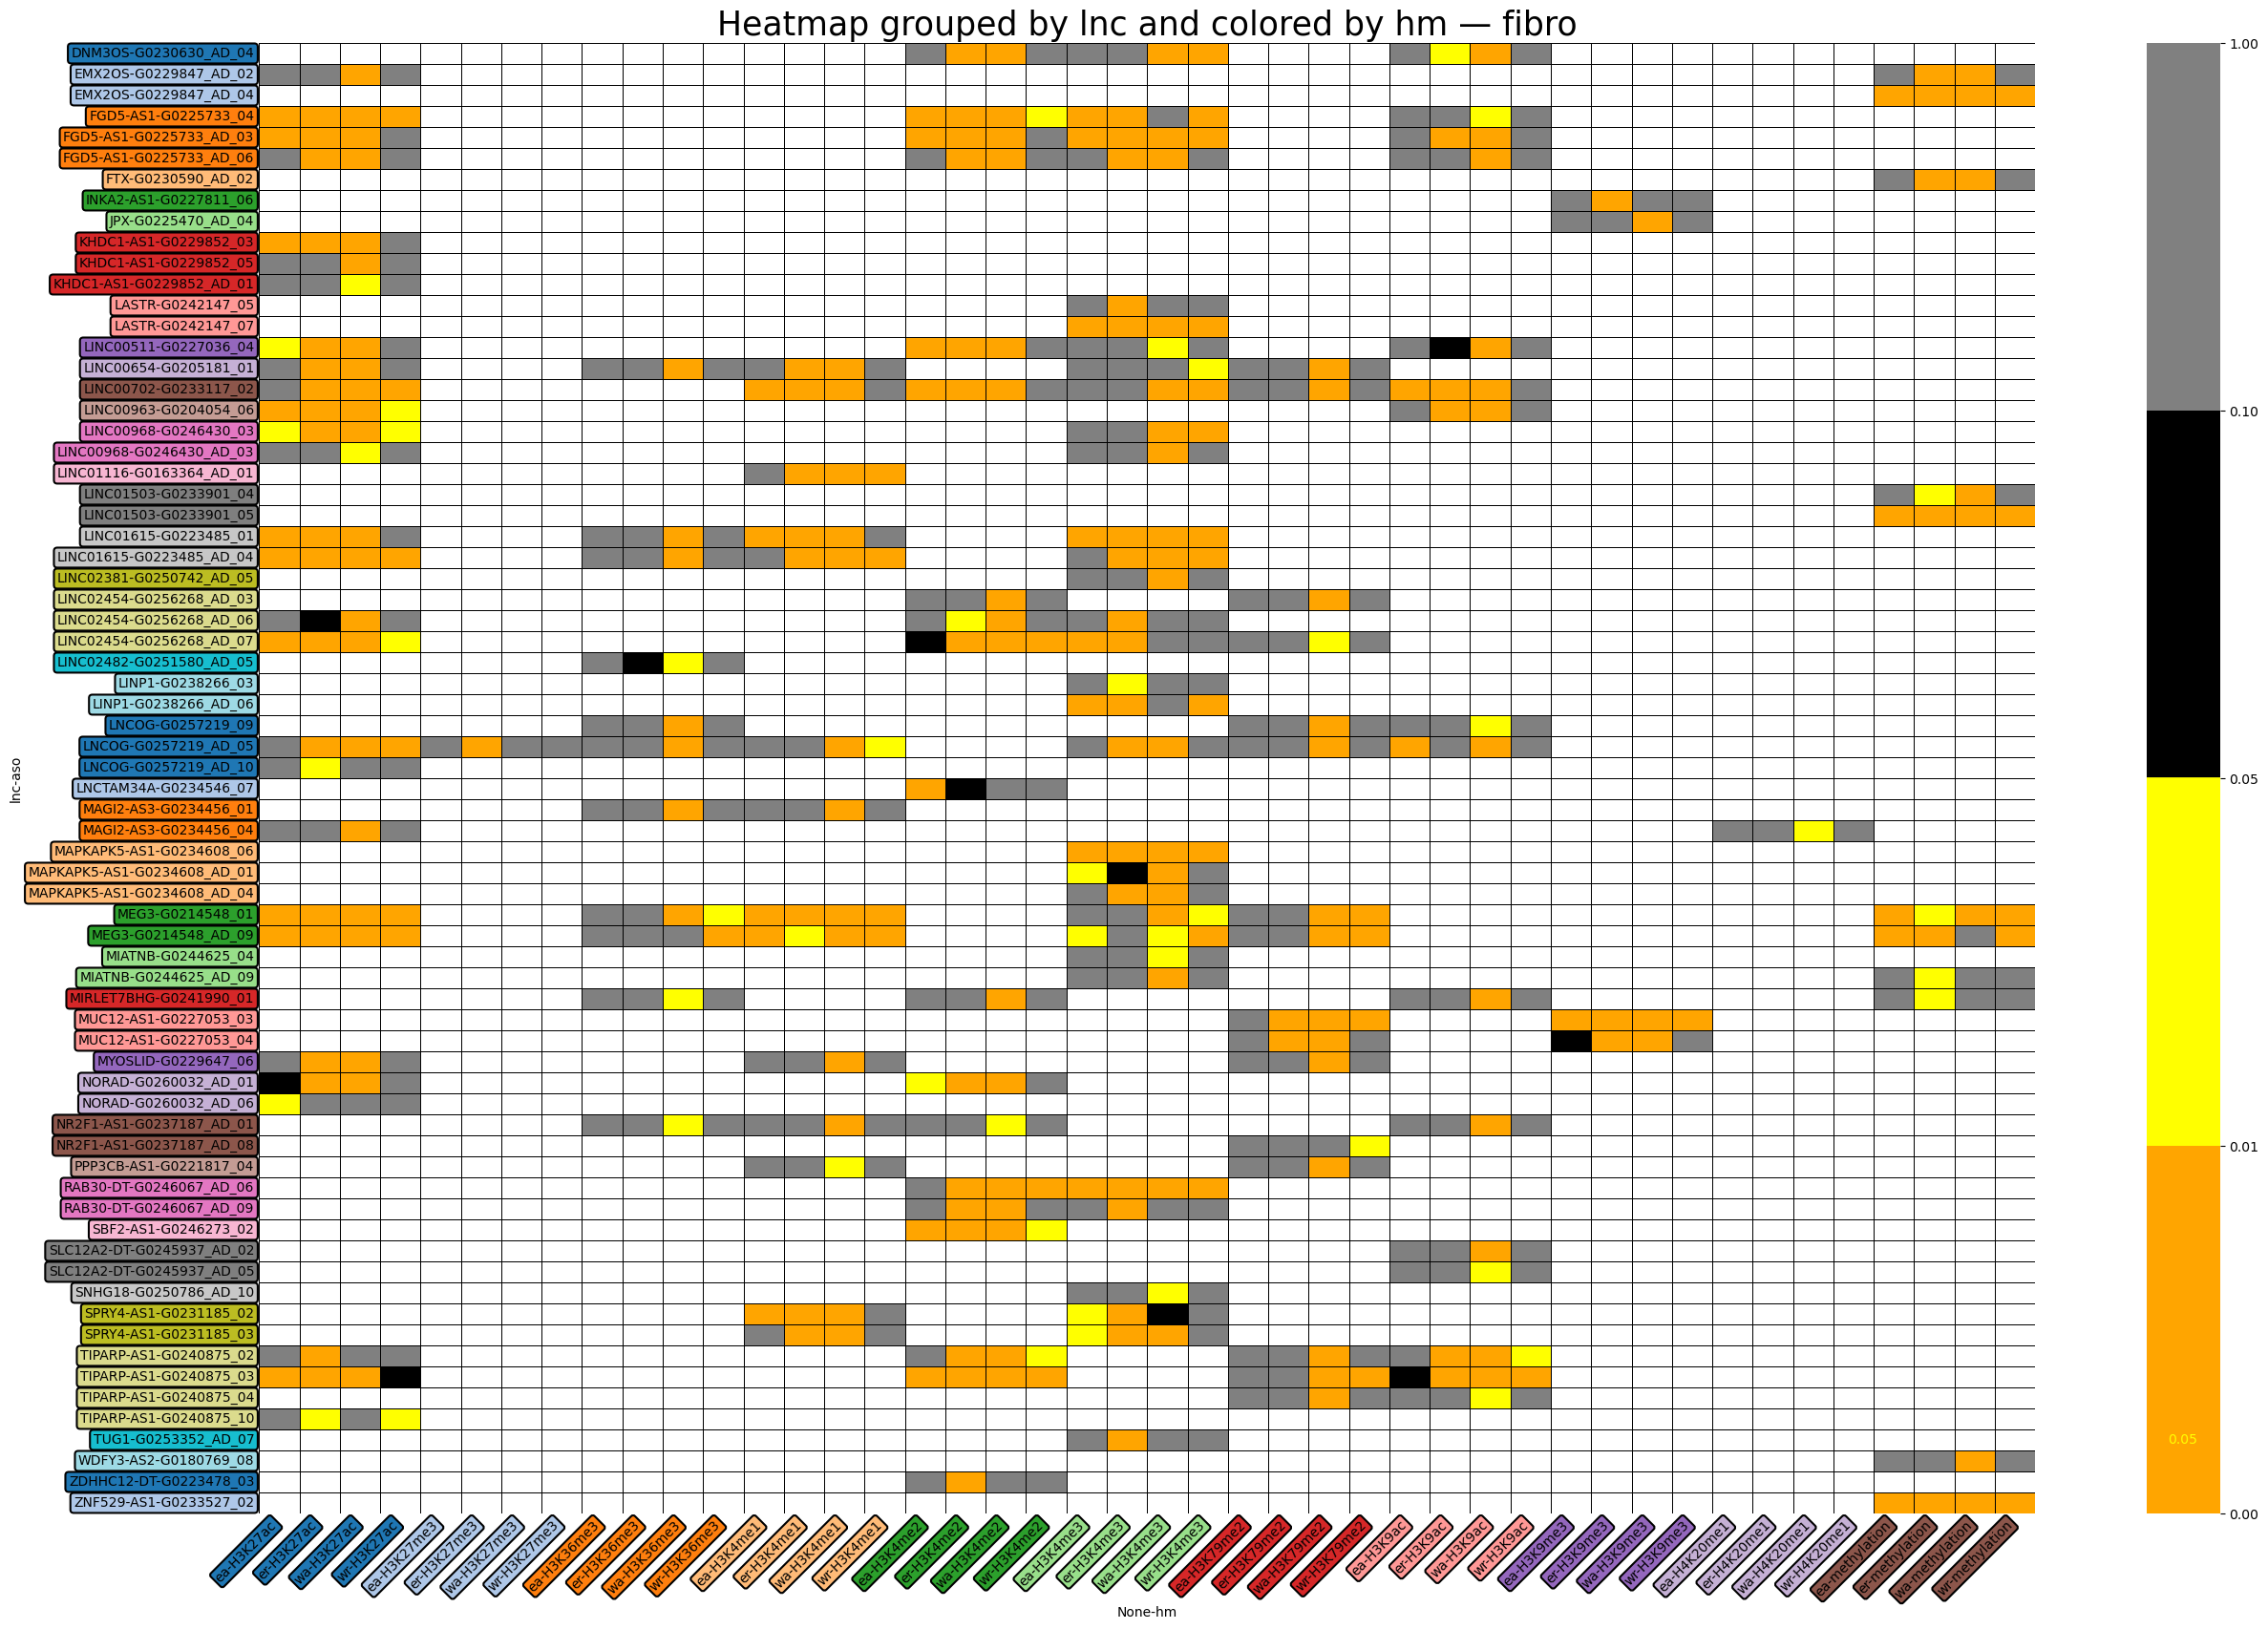

(<Figure size 3000x2000 with 2 Axes>,
 <Axes: title={'center': 'Heatmap grouped by lnc and colored by hm — fibro'}, xlabel='None-hm', ylabel='lnc-aso'>)

In [326]:
heatmap_pval_blue_red(
    df=fisher_results_filt_by_exp_bootstraped["fibro"],
    gene_name_col="lnc",
    exp="fibro",
    save=True,
    use_edge_styles_rows=False,
    use_edge_styles_cols=False,
    color_rows=True,
    color_cols=True
)

/tmp/ipykernel_4879/989489717.py:67: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = get_cmap("tab20")


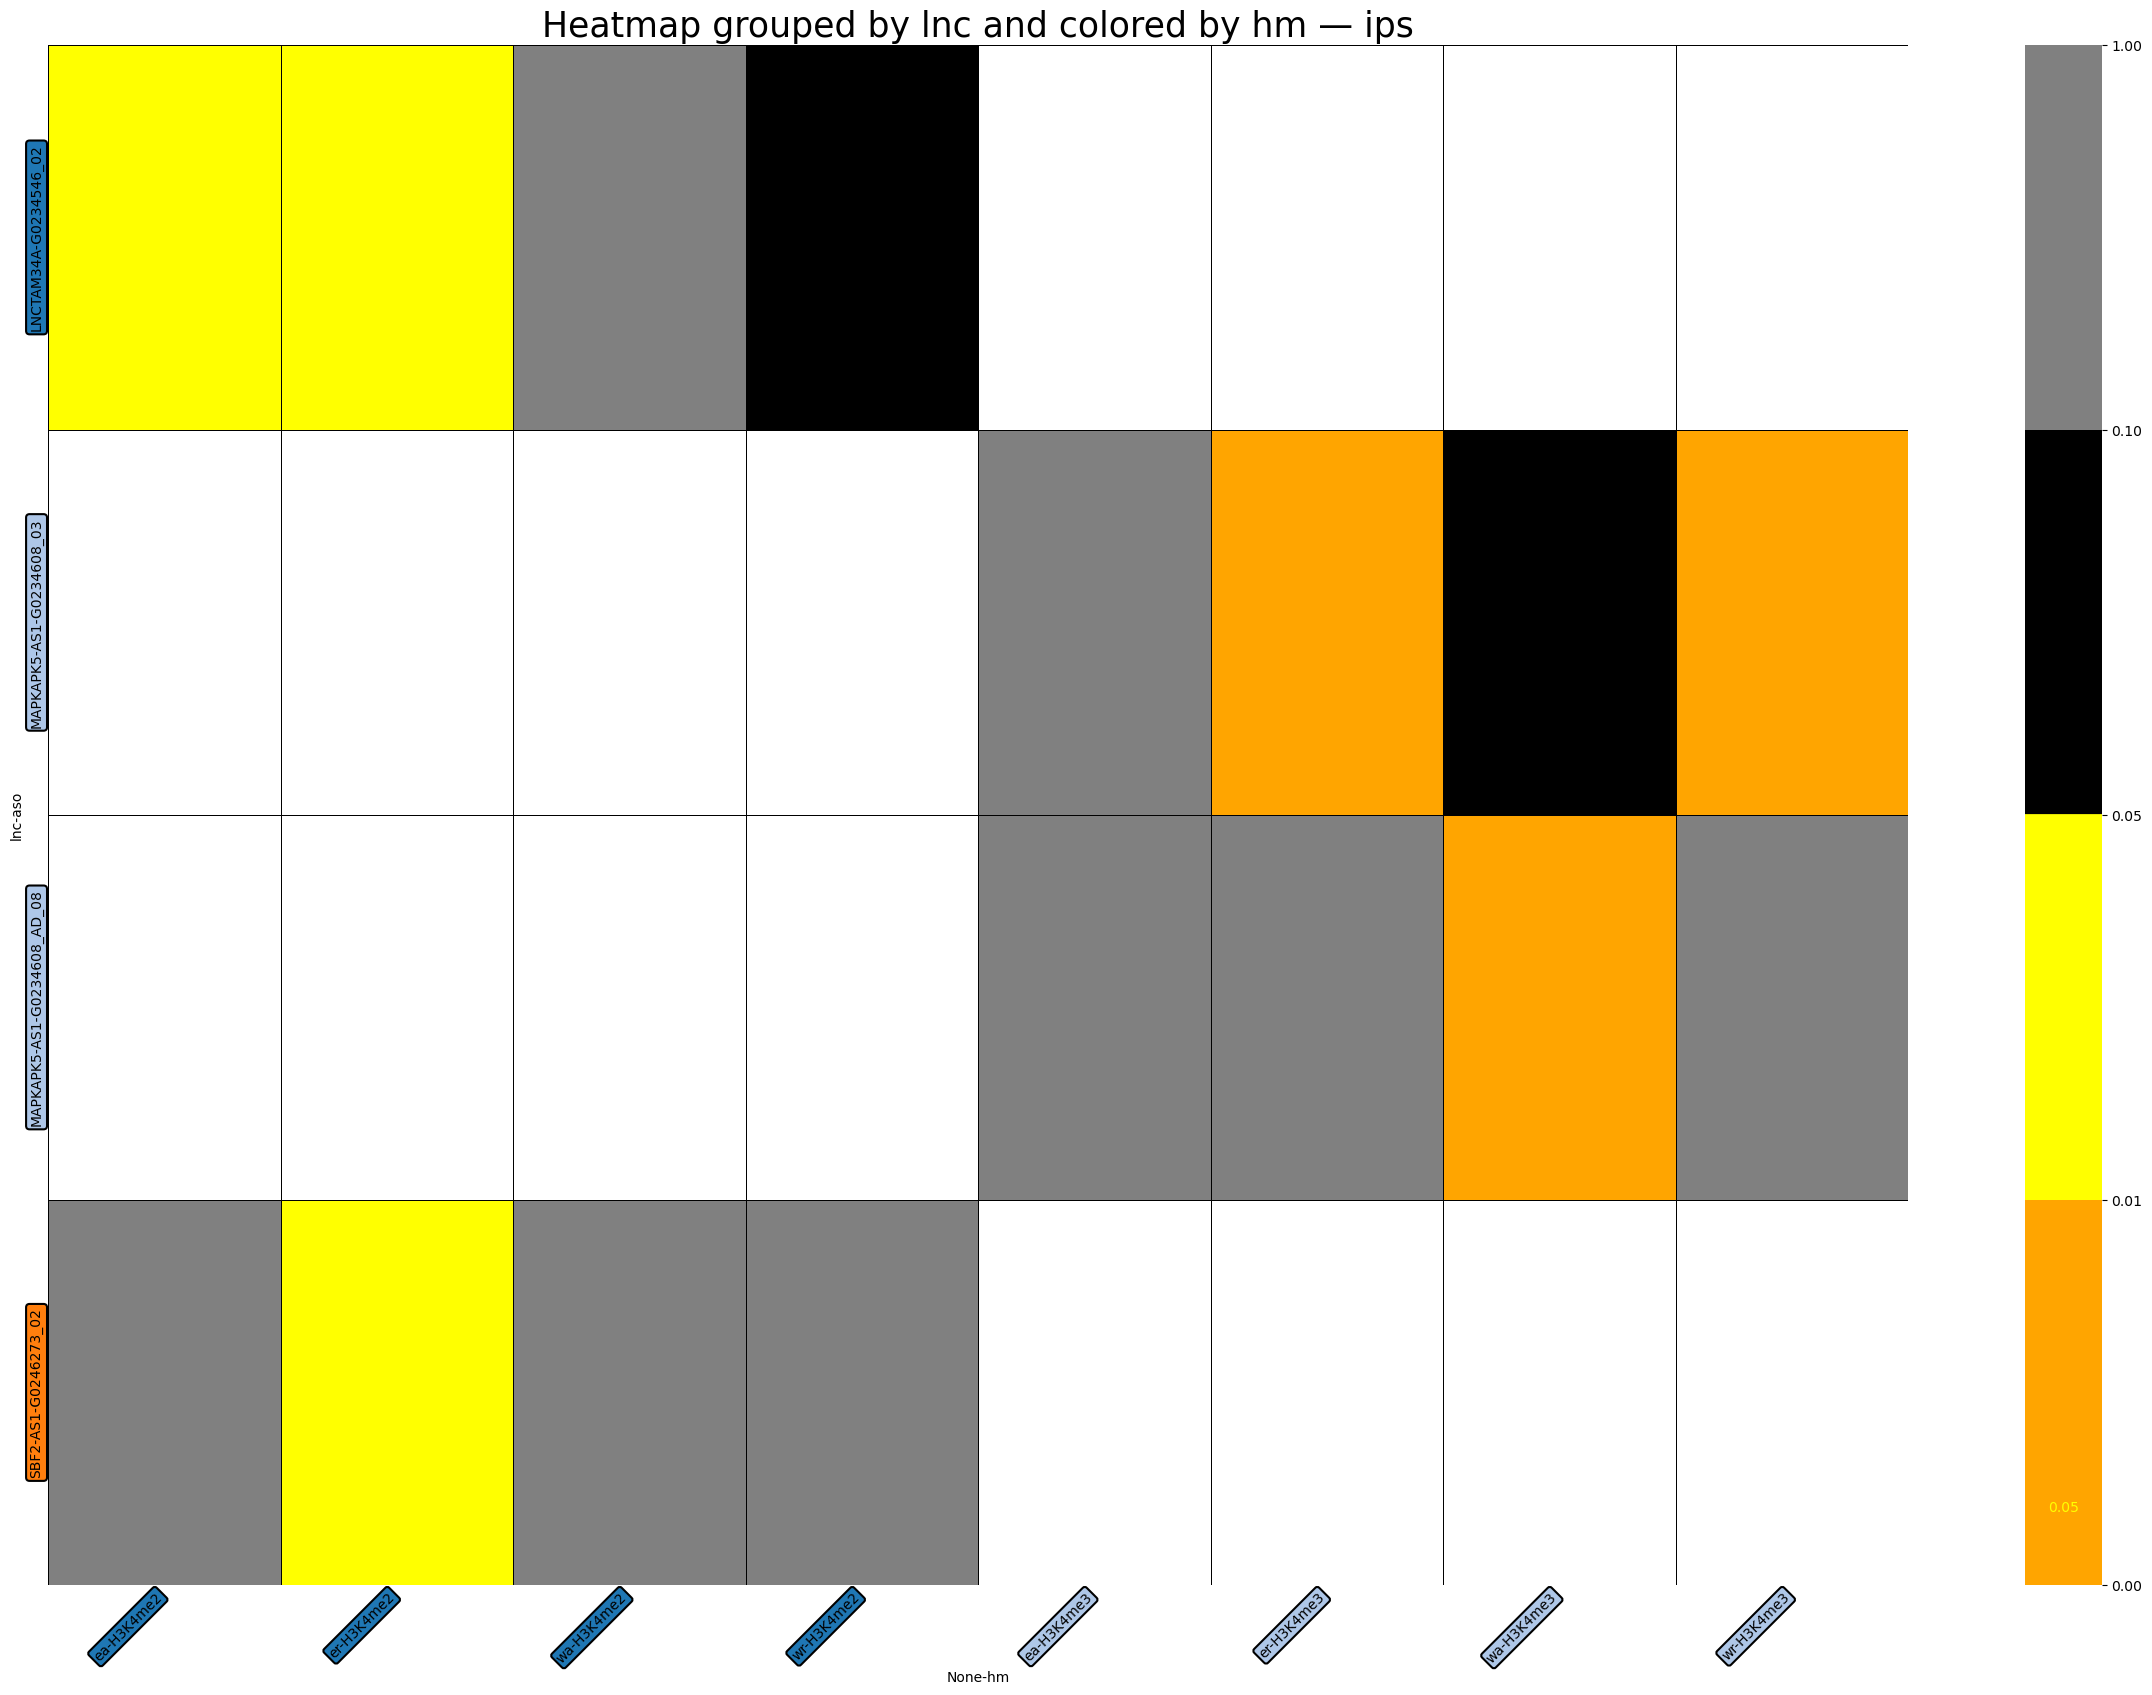

(<Figure size 3000x2000 with 2 Axes>,
 <Axes: title={'center': 'Heatmap grouped by lnc and colored by hm — ips'}, xlabel='None-hm', ylabel='lnc-aso'>)

In [327]:
heatmap_pval_blue_red(
    df=fisher_results_filt_by_exp_bootstraped["ips"],
    gene_name_col="lnc",
    exp="ips",
    save=True,
    use_edge_styles_rows=False,
    use_edge_styles_cols=False,
    color_rows=True,
    color_cols=True
)

/tmp/ipykernel_4879/989489717.py:67: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = get_cmap("tab20")


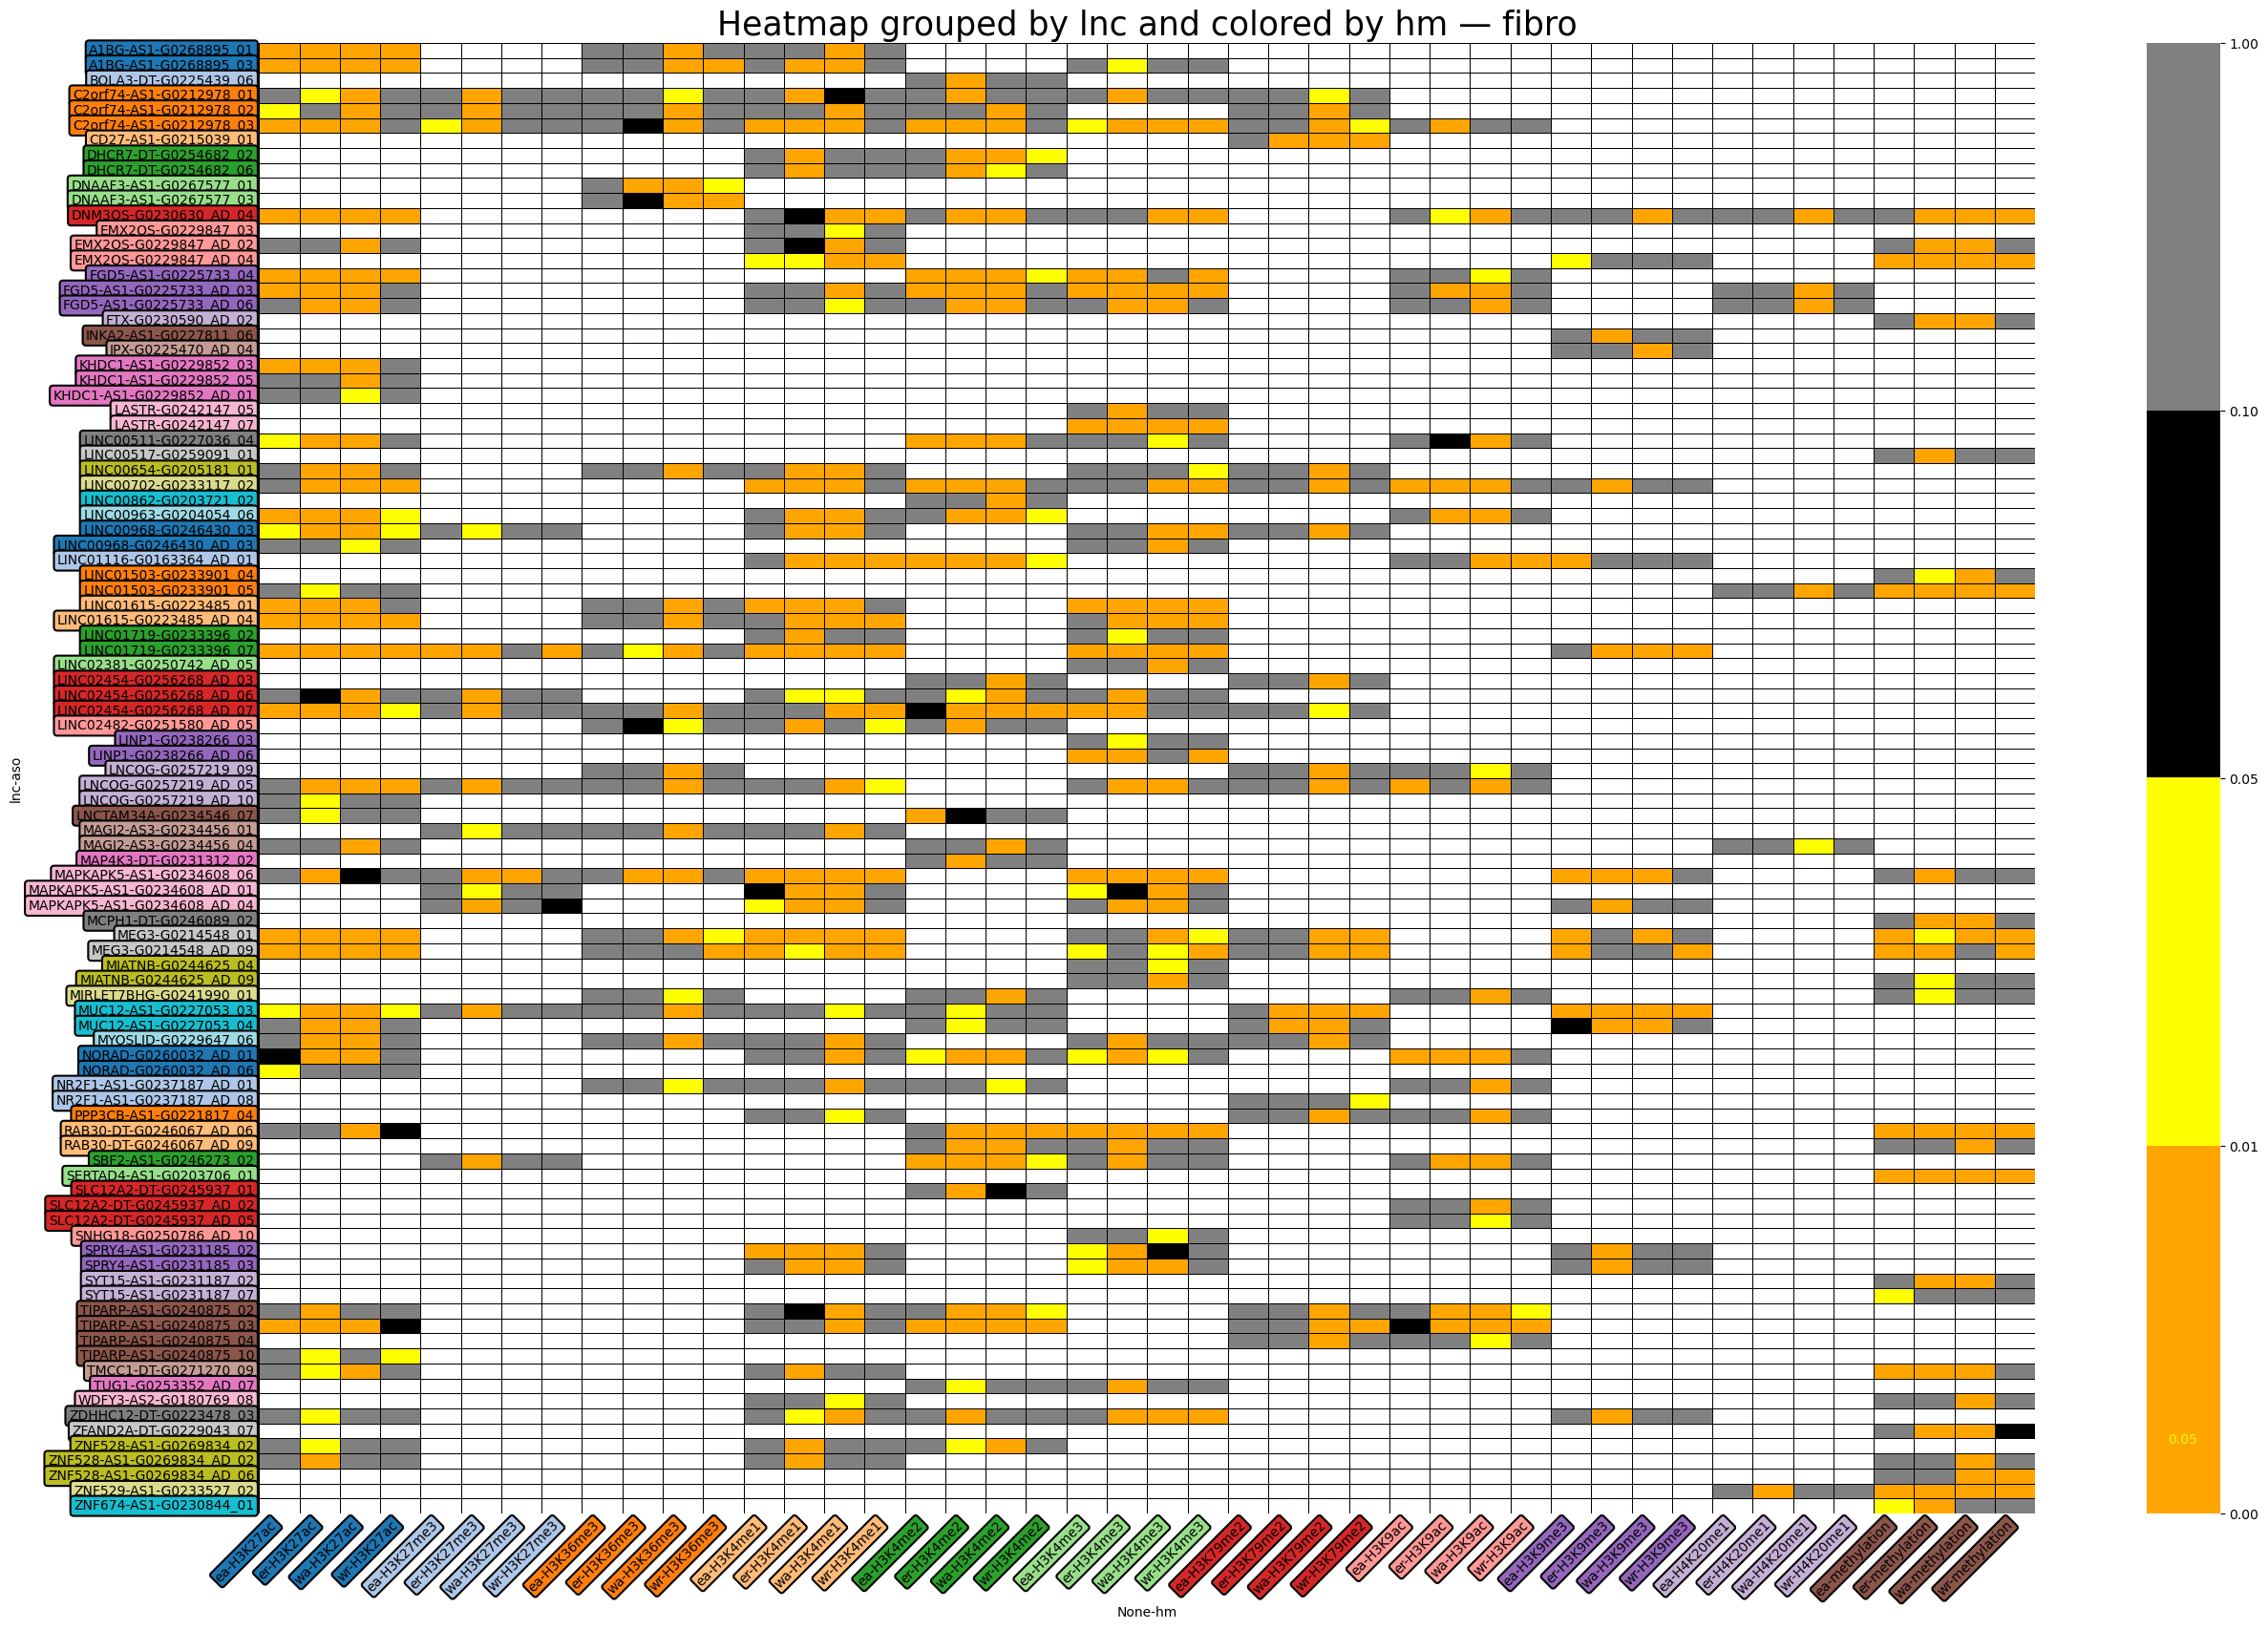

(<Figure size 3000x2000 with 2 Axes>,
 <Axes: title={'center': 'Heatmap grouped by lnc and colored by hm — fibro'}, xlabel='None-hm', ylabel='lnc-aso'>)

In [328]:
heatmap_pval_blue_red(
    df=fisher_results_filt_by_exp["fibro"],
    gene_name_col="lnc",
    exp="fibro",
    save=True,
    use_edge_styles_rows=False,
    use_edge_styles_cols=False,
    color_rows=True,
    color_cols=True
)

/tmp/ipykernel_4879/989489717.py:67: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = get_cmap("tab20")


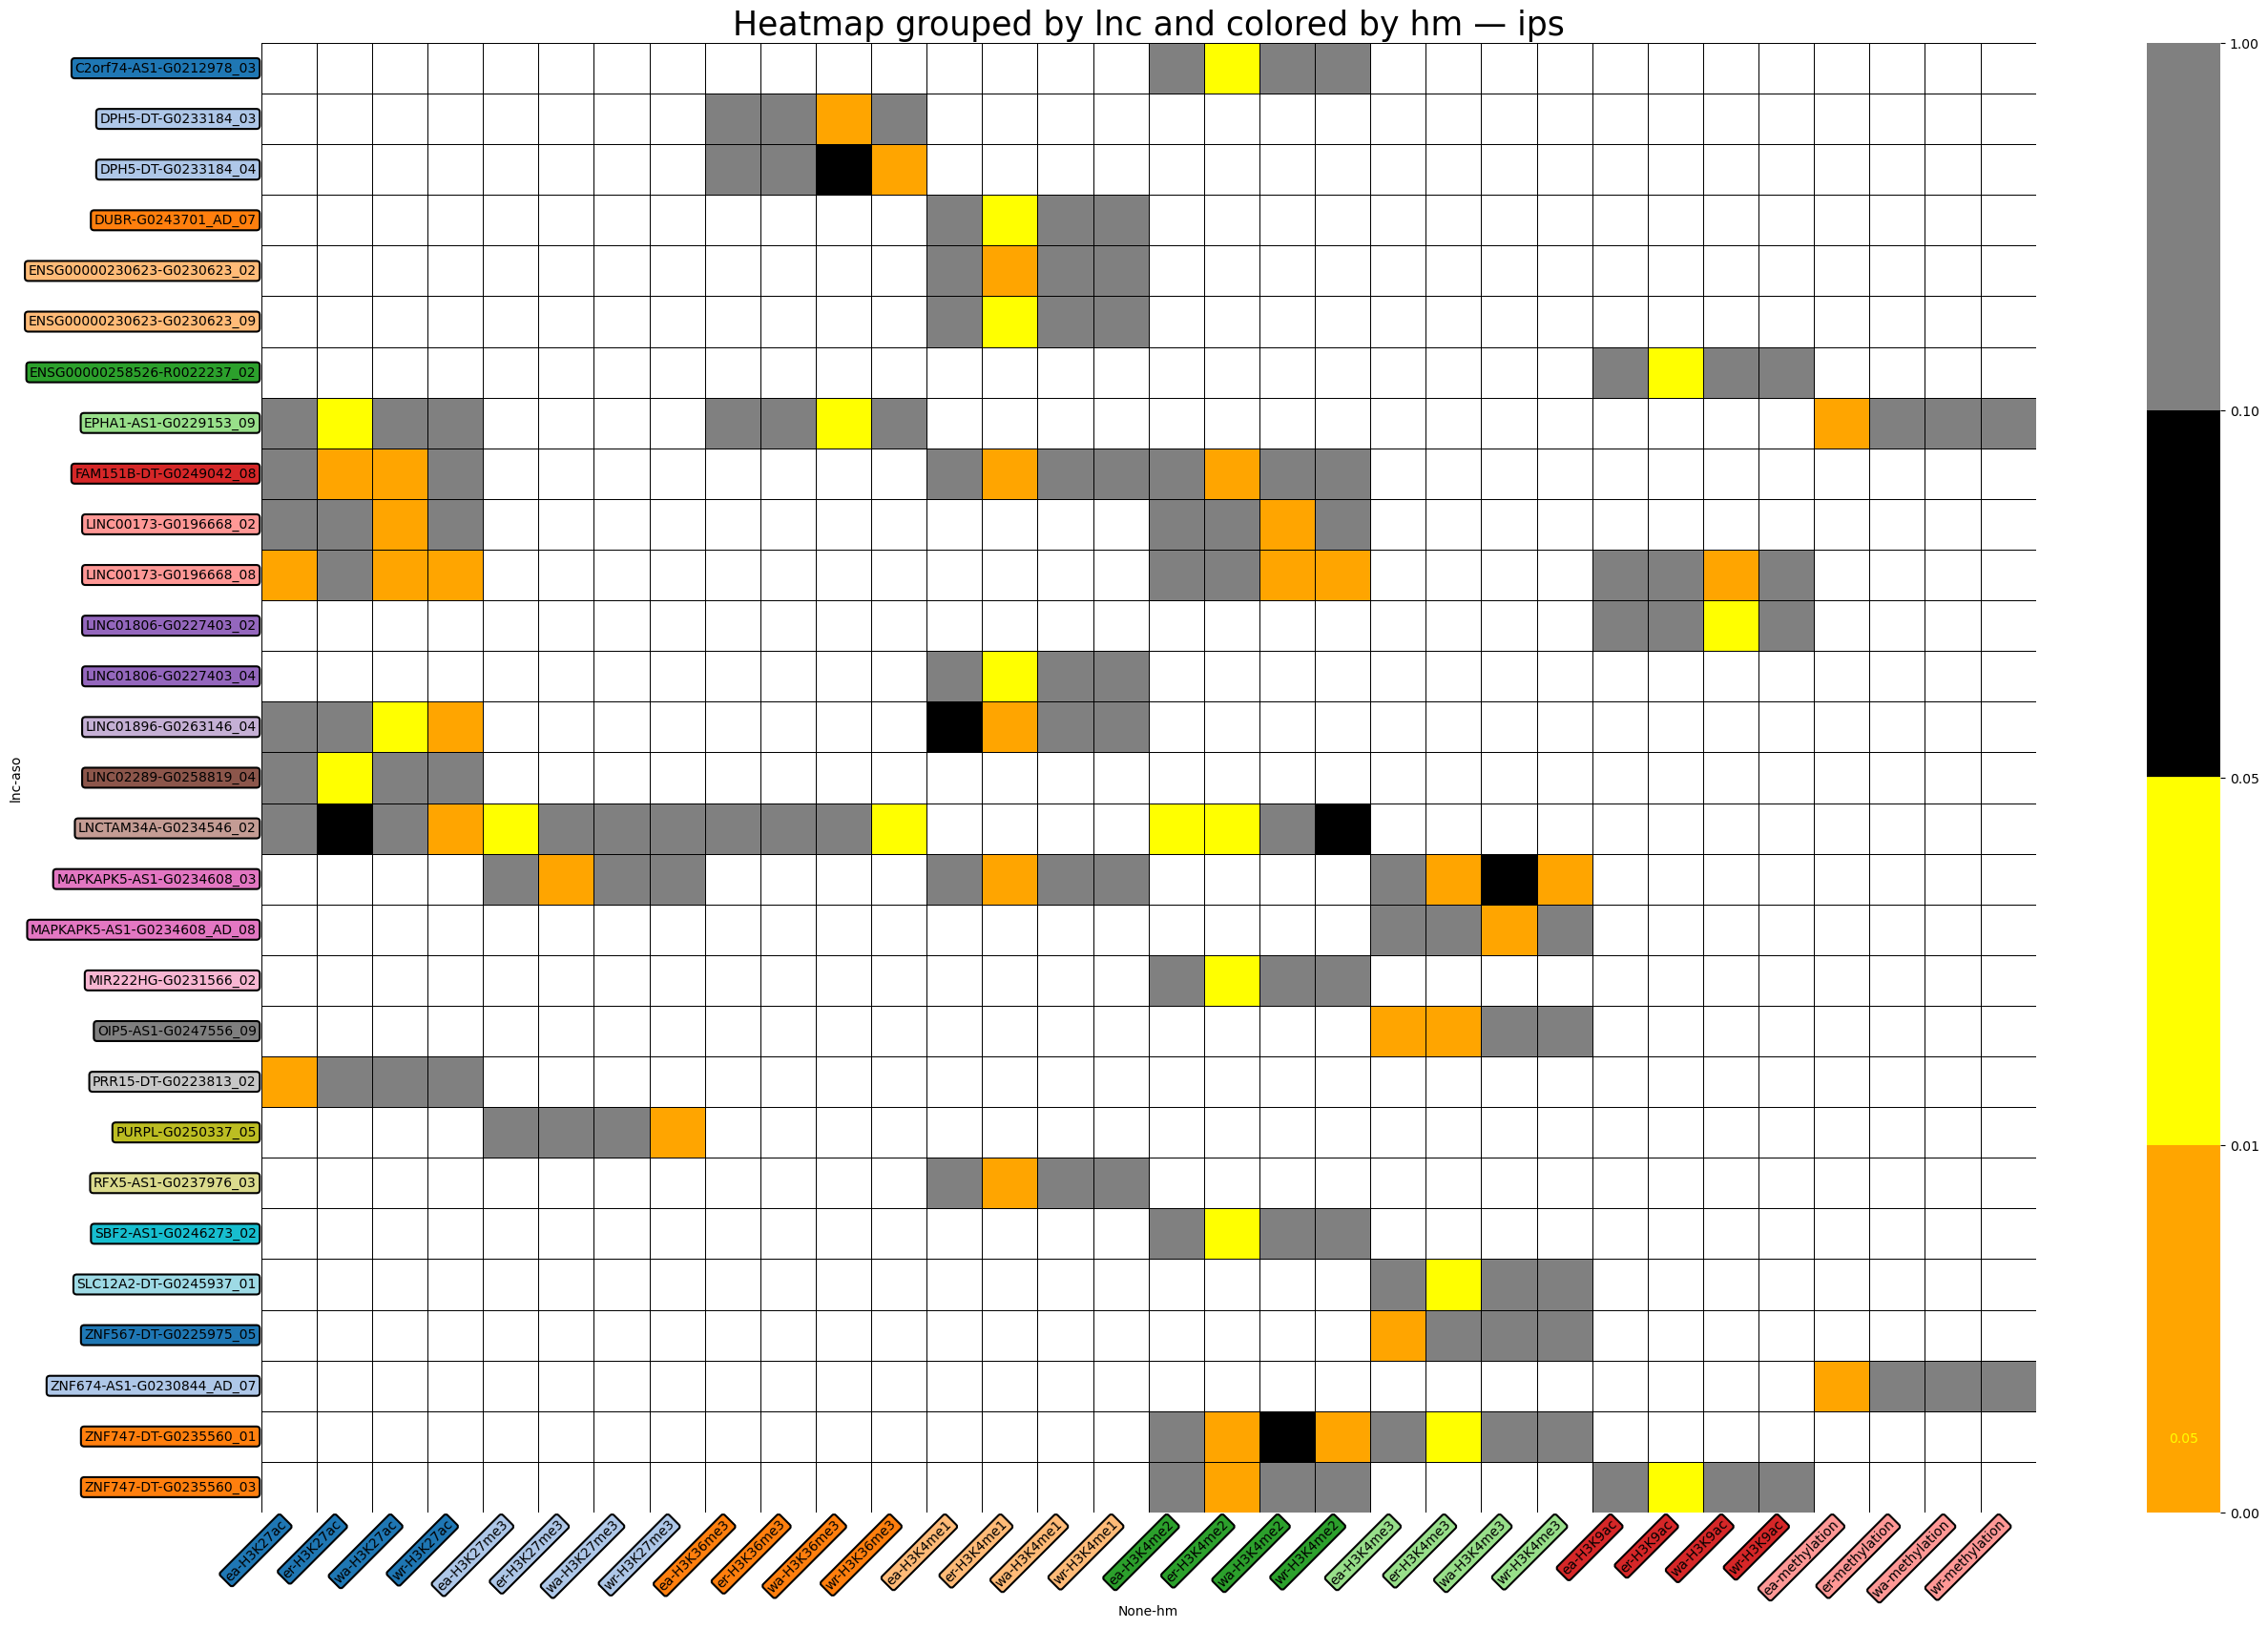

(<Figure size 3000x2000 with 2 Axes>,
 <Axes: title={'center': 'Heatmap grouped by lnc and colored by hm — ips'}, xlabel='None-hm', ylabel='lnc-aso'>)

In [329]:
heatmap_pval_blue_red(
    df=fisher_results_filt_by_exp["ips"],
    gene_name_col="lnc",
    exp="ips",
    save=True,
    use_edge_styles_rows=False,
    use_edge_styles_cols=False,
    color_rows=True,
    color_cols=True
)

In [339]:
fisher_results_fibro = pd.concat([pd.read_csv(i, sep="\t") for i in (FISHER_V2 / f"fibro_fisher_exact_test").glob("*.tsv")])
fisher_results_fibro.head(3)

,hm,lnc_ens,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,H4K20me1,ENSG00000163364,G0163364_06,1.0,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0
1,H4K20me1,ENSG00000163364,G0163364_AD_01,1.0,1.0,0.064891,1.0,1.0,1.0,0.673245,1.0
2,H4K20me1,ENSG00000197182,G0241990_01,1.0,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0


In [364]:
fisher_results_fibro.shape

(1114, 11)

In [356]:
df_our_chipseq_res_updated_subset = df_our_chipseq_res_updated.loc[:7,:]
df_our_chipseq_res_updated_subset

,old-lnc,hm,lnc_ens,lnc,lnc-hm
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac
1,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac
2,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3
3,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac
4,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3
5,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3
6,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3
7,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3


In [361]:
#проверка
to_csv= FIBRO_INFO_V2  / "H3K9ac.tsv"
pd.read_csv(to_csv, sep="\t").query("lnc == 'ENSG00000229847'")

,hm,lnc,aso,expr,corr,number_of_DEG,number_genes_from_himorna,TP,TN,FP,FN


In [371]:
fisher_results_fibro_intersect = pd.merge(left=df_our_chipseq_res_updated_subset, right=fisher_results_fibro, how="left", left_on=["lnc_ens", "hm"], right_on=["lnc_ens", "hm"])
fisher_results_fibro_intersect

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_03,1.347538e-01,1.000000e+00,1.000000e+00,1.000000,5.257605e-01,1.000000,1.000000e+00,1.000000
1,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_04,5.697934e-02,3.591148e-01,1.074227e-02,0.006789,2.884579e-01,1.000000,4.579599e-02,0.137481
2,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_AD_03,5.234635e-14,9.625299e-03,2.111320e-13,1.000000,1.413352e-12,0.129942,8.550845e-12,1.000000
3,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_AD_06,3.803517e-02,2.143495e-01,2.870747e-10,0.132501,2.369884e-01,1.000000,5.813262e-09,1.000000
4,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,G0231185_02,1.105415e-06,1.000000e+00,1.000000e+00,1.000000,1.566004e-05,1.000000,1.000000e+00,1.000000
6,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,G0231185_03,4.999947e-11,1.294748e-01,1.000000e+00,1.000000,1.062489e-09,0.949772,1.000000e+00,1.000000
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_03,2.709692e-08,1.268399e-03,1.369728e-17,0.063357,1.585170e-07,0.009894,1.456892e-16,0.322296
8,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_05,1.350263e-01,8.785644e-02,2.052213e-13,1.000000,3.361294e-01,0.324695,1.846992e-12,1.000000
9,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_AD_01,1.000000e+00,1.000000e+00,1.122300e-02,1.000000,1.000000e+00,1.000000,3.751689e-02,1.000000


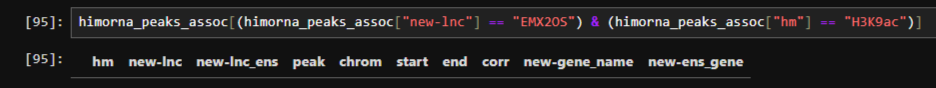

In [363]:
to_file = FISHER_V2 / "all_pvalues-ivan_antonov.tsv"
fisher_results_fibro_ivan_antonov = pd.read_csv(to_file, sep="\t")
fisher_results_fibro_ivan_antonov

,lncRNAId,lncRNAName,mark_name,pvalue,mm_pvalue,mp_pvalue,pm_pvalue,pp_pvalue,adj_pvalue,mm_adj_pvalue,mp_adj_pvalue,pm_adj_pvalue,pp_adj_pvalue
0,ENSG00000257219_ASO_G0257219_AD_10,RP11-54A9.1,H3K27ac,1.037151e-02,7.355283e-02,0.169588,3.453283e-01,1.000000,2.044669e-02,1.585983e-01,0.487566,4.672089e-01,1.000000
1,ENSG00000260032_ASO_G0260032_AD_01,LINC00657,H3K27ac,5.819208e-01,3.160325e-02,0.630880,1.930921e-01,0.017298,6.692089e-01,7.519394e-02,1.000000,3.098454e-01,0.238714
2,ENSG00000268895_ASO_G0268895_01,A1BG-AS1,H3K27ac,4.993508e-11,4.089968e-09,0.060256,6.477048e-24,0.238033,2.650400e-10,4.031540e-08,0.259853,2.234582e-22,0.966132
3,ENSG00000271270_ASO_G0271270_09,TMCC1-AS1,H3K27ac,5.816311e-04,9.877877e-02,1.000000,1.412279e-06,0.646489,1.543559e-03,2.065374e-01,1.000000,7.495943e-06,1.000000
4,ENSG00000212978_ASO_G0212978_01,AC016747.3,H3K27ac,1.811621e-04,6.613420e-03,0.207435,4.872205e-06,1.000000,5.208412e-04,2.074209e-02,0.550500,2.241214e-05,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
291,ENSG00000246067_ASO_G0246067_AD_06,RAB30-AS1,methylation,2.819039e-10,2.514307e-08,0.247093,8.093048e-11,0.534625,1.444757e-09,1.718110e-07,0.708284,5.530250e-10,1.000000
292,ENSG00000246089_ASO_G0246089_02,RP11-115C21.2,methylation,1.767379e-04,8.565799e-03,0.185215,6.872491e-03,1.000000,6.038546e-04,3.284091e-02,0.708284,2.348101e-02,1.000000
293,ENSG00000246067_ASO_G0246067_AD_09,RAB30-AS1,methylation,1.000000e+00,9.815948e-02,1.000000,1.777502e-03,1.000000,1.000000e+00,2.683026e-01,1.000000,8.097509e-03,1.000000
294,ENSG00000269834_ASO_G0269834_AD_06,CTD-3018O17.3,methylation,5.677378e-03,1.000000e+00,1.000000,3.364275e-02,0.025223,1.723483e-02,1.000000e+00,1.000000,8.620956e-02,0.178816


In [417]:
fisher_results_fibro_ivan_antonov_intersect = pd.merge(left=df_our_chipseq_res_updated_subset, right=fisher_results_fibro_ivan_antonov, how="left", left_on=["old-lnc", "hm"], right_on=["lncRNAName", "mark_name"])
fisher_results_fibro_ivan_antonov_intersect

,old-lnc,hm,lnc_ens,lnc,lnc-hm,lncRNAId,lncRNAName,mark_name,pvalue,mm_pvalue,mp_pvalue,pm_pvalue,pp_pvalue,adj_pvalue,mm_adj_pvalue,mp_adj_pvalue,pm_adj_pvalue,pp_adj_pvalue
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_03,FGD5-AS1,H3K9ac,1.075714e-05,3.932407e-06,0.503403,8.618163e-05,0.011770,1.936285e-04,4.718888e-05,1.000000,1.420240e-03,0.141241
1,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_06,FGD5-AS1,H3K9ac,3.388541e-04,4.160519e-01,0.586869,1.183533e-04,0.144600,1.355417e-03,8.016514e-01,1.000000,1.420240e-03,0.743657
2,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_04,FGD5-AS1,H3K9ac,1.560985e-01,1.000000e+00,0.631184,4.592009e-03,0.585934,2.554339e-01,1.000000e+00,1.000000,2.024210e-02,1.000000
3,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_03,AC005592.2,H3K9me3,6.731348e-05,6.050140e-06,0.300742,1.000000e+00,1.000000,4.880227e-04,4.386351e-05,1.000000,1.000000e+00,1.000000
5,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_02,AC005592.2,H3K9me3,1.669854e-01,3.606784e-03,0.271252,1.000000e+00,1.000000,2.548725e-01,1.743279e-02,1.000000,1.000000e+00,1.000000
6,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_05,RP11-398K22.12,H3K27ac,4.600763e-05,7.253742e-01,0.036341,9.050441e-06,1.000000,1.587263e-04,1.000000e+00,0.187840,3.903003e-05,1.000000
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_03,RP11-398K22.12,H3K27ac,1.649350e-04,2.674764e-02,0.082574,1.574219e-05,0.189498,4.948049e-04,7.098412e-02,0.299873,6.389479e-05,0.817211
8,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_AD_01,RP11-398K22.12,H3K27ac,1.579881e-01,1.000000e+00,1.000000,3.578802e-02,1.000000,2.535158e-01,1.000000e+00,1.000000,7.262864e-02,1.000000
9,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,ENSG00000267577_ASO_G0267577_01,CTD-2587H24.5,H3K36me3,7.022801e-05,1.591713e-03,0.104197,1.928830e-14,0.001087,3.019804e-03,2.281456e-02,1.000000,8.293969e-13,0.023360


In [418]:
fisher_results_fibro_ivan_antonov_intersect

,old-lnc,hm,lnc_ens,lnc,lnc-hm,lncRNAId,lncRNAName,mark_name,pvalue,mm_pvalue,mp_pvalue,pm_pvalue,pp_pvalue,adj_pvalue,mm_adj_pvalue,mp_adj_pvalue,pm_adj_pvalue,pp_adj_pvalue
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_03,FGD5-AS1,H3K9ac,1.075714e-05,3.932407e-06,0.503403,8.618163e-05,0.011770,1.936285e-04,4.718888e-05,1.000000,1.420240e-03,0.141241
1,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_06,FGD5-AS1,H3K9ac,3.388541e-04,4.160519e-01,0.586869,1.183533e-04,0.144600,1.355417e-03,8.016514e-01,1.000000,1.420240e-03,0.743657
2,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_04,FGD5-AS1,H3K9ac,1.560985e-01,1.000000e+00,0.631184,4.592009e-03,0.585934,2.554339e-01,1.000000e+00,1.000000,2.024210e-02,1.000000
3,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_03,AC005592.2,H3K9me3,6.731348e-05,6.050140e-06,0.300742,1.000000e+00,1.000000,4.880227e-04,4.386351e-05,1.000000,1.000000e+00,1.000000
5,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_02,AC005592.2,H3K9me3,1.669854e-01,3.606784e-03,0.271252,1.000000e+00,1.000000,2.548725e-01,1.743279e-02,1.000000,1.000000e+00,1.000000
6,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_05,RP11-398K22.12,H3K27ac,4.600763e-05,7.253742e-01,0.036341,9.050441e-06,1.000000,1.587263e-04,1.000000e+00,0.187840,3.903003e-05,1.000000
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_03,RP11-398K22.12,H3K27ac,1.649350e-04,2.674764e-02,0.082574,1.574219e-05,0.189498,4.948049e-04,7.098412e-02,0.299873,6.389479e-05,0.817211
8,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_AD_01,RP11-398K22.12,H3K27ac,1.579881e-01,1.000000e+00,1.000000,3.578802e-02,1.000000,2.535158e-01,1.000000e+00,1.000000,7.262864e-02,1.000000
9,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,ENSG00000267577_ASO_G0267577_01,CTD-2587H24.5,H3K36me3,7.022801e-05,1.591713e-03,0.104197,1.928830e-14,0.001087,3.019804e-03,2.281456e-02,1.000000,8.293969e-13,0.023360


In [419]:
columns = ["old-lnc","hm","lnc_ens","lnc","lnc-hm","lncRNAId","mm_pvalue","mp_pvalue","pm_pvalue","pp_pvalue","mm_adj_pvalue","mp_adj_pvalue","pm_adj_pvalue","pp_adj_pvalue"]
fisher_results_fibro_ivan_antonov_intersect = fisher_results_fibro_ivan_antonov_intersect[columns]

pm => wa
1st "p" => positive correlation between lncRNA and the level of a histone mark => lncRNA writes the mark => writer (w)

2nd "m" => after lncRNA knockdown the expression of a nearby gene decreases => in normal cells (i.e. without knockdown) lncRNA upregulates expression of the gene.

Taking into account that lncRNA is writer, the only way it can upregulate gene expression is that it writes an active mark => its molecular role is "Writer of an Active mark (wa)"

pp => wr
1st "p" => positive correlation between lncRNA and the level of a histone mark => lncRNA writes the mark => writer (w)

2nd "p" => after lncRNA knockdown the expression of a nearby gene increases => in normal cells (i.e. without knockdown) lncRNA downregulates expression of the gene.

Taking into account that lncRNA is writer, the only way it can downregulate gene expression is that it writes a repressive mark => its molecular role is "Writer of a Repressive mark (wr)"

mp => ea
1st "m" => negative correlation between lncRNA and the level of a histone mark => lncRNA removes the mark => eraser (e)

2nd "p" => after lncRNA knockdown the expression of a nearby gene increases => in normal cells (i.e. without knockdown) lncRNA downregulates expression of the gene.

Taking into account that lncRNA is eraser, the only way it can downregulate gene expression is that it erases an active mark => its molecular role is "Eraser of an Active mark (ea)"

mm => er
1st "m" => negative correlation between lncRNA and the level of a histone mark => lncRNA removes the mark => eraser (e)

2nd "m" => after lncRNA knockdown the expression of a nearby gene decreases => in normal cells (i.e. without knockdown) lncRNA upregulates expression of the gene.

Taking into account that lncRNA is eraser, the only way it can upregulate gene expression is that it removes repressive mark => its molecular role is "Eraser of a Repressive mark (er)"

In [421]:
fisher_results_fibro_ivan_antonov_intersect = fisher_results_fibro_ivan_antonov_intersect.rename(columns={"lncRNAId":"aso","mm_pvalue":"p_value-minus_down", "mp_pvalue":"p_value-minus_up", "pm_pvalue":"p_value-plus_down", "pp_pvalue":"p_value-plus_up", "mm_adj_pvalue":"p_value-md_adj", "mp_adj_pvalue":"p_value-mu_adj", "pm_adj_pvalue":"p_value-pd_adj", "pp_adj_pvalue":"p_value-pu_adj",})

In [422]:
fisher_results_fibro_ivan_antonov_intersect.columns

Index(['old-lnc', 'hm', 'lnc_ens', 'lnc', 'lnc-hm', 'aso',
       'p_value-minus_down', 'p_value-minus_up', 'p_value-plus_down',
       'p_value-plus_up', 'p_value-md_adj', 'p_value-mu_adj', 'p_value-pd_adj',
       'p_value-pu_adj'],
      dtype='object')

In [423]:
fisher_results_fibro_ivan_antonov_intersect

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_03,3.932407e-06,0.503403,8.618163e-05,0.011770,4.718888e-05,1.000000,1.420240e-03,0.141241
1,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_06,4.160519e-01,0.586869,1.183533e-04,0.144600,8.016514e-01,1.000000,1.420240e-03,0.743657
2,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_04,1.000000e+00,0.631184,4.592009e-03,0.585934,1.000000e+00,1.000000,2.024210e-02,1.000000
3,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_03,6.050140e-06,0.300742,1.000000e+00,1.000000,4.386351e-05,1.000000,1.000000e+00,1.000000
5,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_02,3.606784e-03,0.271252,1.000000e+00,1.000000,1.743279e-02,1.000000,1.000000e+00,1.000000
6,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_05,7.253742e-01,0.036341,9.050441e-06,1.000000,1.000000e+00,0.187840,3.903003e-05,1.000000
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_03,2.674764e-02,0.082574,1.574219e-05,0.189498,7.098412e-02,0.299873,6.389479e-05,0.817211
8,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_AD_01,1.000000e+00,1.000000,3.578802e-02,1.000000,1.000000e+00,1.000000,7.262864e-02,1.000000
9,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,ENSG00000267577_ASO_G0267577_01,1.591713e-03,0.104197,1.928830e-14,0.001087,2.281456e-02,1.000000,8.293969e-13,0.023360


In [424]:
fisher_results_fibro_ivan_antonov_intersect[['old-lnc', 'hm', 'lnc_ens', 'lnc', 'lnc-hm', 'aso', 'p_value-minus_down',	'p_value-minus_up',	'p_value-plus_down','p_value-plus_up',	'p_value-md_adj',	'p_value-mu_adj',	'p_value-pd_adj',	'p_value-pu_adj']]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_03,3.932407e-06,0.503403,8.618163e-05,0.011770,4.718888e-05,1.000000,1.420240e-03,0.141241
1,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_AD_06,4.160519e-01,0.586869,1.183533e-04,0.144600,8.016514e-01,1.000000,1.420240e-03,0.743657
2,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,ENSG00000225733_ASO_G0225733_04,1.000000e+00,0.631184,4.592009e-03,0.585934,1.000000e+00,1.000000,2.024210e-02,1.000000
3,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_03,6.050140e-06,0.300742,1.000000e+00,1.000000,4.386351e-05,1.000000,1.000000e+00,1.000000
5,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,ENSG00000231185_ASO_G0231185_02,3.606784e-03,0.271252,1.000000e+00,1.000000,1.743279e-02,1.000000,1.000000e+00,1.000000
6,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_05,7.253742e-01,0.036341,9.050441e-06,1.000000,1.000000e+00,0.187840,3.903003e-05,1.000000
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_03,2.674764e-02,0.082574,1.574219e-05,0.189498,7.098412e-02,0.299873,6.389479e-05,0.817211
8,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,ENSG00000229852_ASO_G0229852_AD_01,1.000000e+00,1.000000,3.578802e-02,1.000000,1.000000e+00,1.000000,7.262864e-02,1.000000
9,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,ENSG00000267577_ASO_G0267577_01,1.591713e-03,0.104197,1.928830e-14,0.001087,2.281456e-02,1.000000,8.293969e-13,0.023360


In [444]:
fisher_results_fibro_ivan_antonov_intersect["aso"] = fisher_results_fibro_ivan_antonov_intersect["aso"].apply(lambda x: x.split("ASO_")[1] if type(x) == str else x)

### FGD5-AS1-H3K9ac

In [445]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "FGD5-AS1-H3K9ac"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_03,1.347538e-01,1.000000,1.000000e+00,1.000000,5.257605e-01,1.000000,1.000000e+00,1.000000
1,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_04,5.697934e-02,0.359115,1.074227e-02,0.006789,2.884579e-01,1.000000,4.579599e-02,0.137481
2,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_AD_03,5.234635e-14,0.009625,2.111320e-13,1.000000,1.413352e-12,0.129942,8.550845e-12,1.000000
3,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_AD_06,3.803517e-02,0.214350,2.870747e-10,0.132501,2.369884e-01,1.000000,5.813262e-09,1.000000


In [446]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "FGD5-AS1-H3K9ac"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
0,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_AD_03,0.000004,0.503403,0.000086,0.011770,0.000047,1.0,0.001420,0.141241
1,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_AD_06,0.416052,0.586869,0.000118,0.144600,0.801651,1.0,0.001420,0.743657
2,FGD5-AS1,H3K9ac,ENSG00000225733,FGD5-AS1,FGD5-AS1-H3K9ac,G0225733_04,1.000000,0.631184,0.004592,0.585934,1.000000,1.0,0.020242,1.000000


In [461]:
heatmap_pval_blue_red(
    df=fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "FGD5-AS1-H3K9ac"],
    gene_name_col="lnc",
    exp="fibro",
    save=False,
    use_edge_styles_rows=False,
    use_edge_styles_cols=False,
    color_rows=True,
    color_cols=True
)

ValueError: В df не хватает колонок: ['lnc-aso', 'er', 'ea', 'wa', 'wr']

### EMX2OS-H3K9ac

In [447]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "EMX2OS-H3K9ac"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
4,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [448]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "EMX2OS-H3K9ac"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
3,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### SPRY4-AS1-H3K9me3

In [449]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "SPRY4-AS1-H3K9me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
5,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,G0231185_02,1.105415e-06,1.000000,1.0,1.0,1.566004e-05,1.000000,1.0,1.0
6,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,G0231185_03,4.999947e-11,0.129475,1.0,1.0,1.062489e-09,0.949772,1.0,1.0


In [450]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "SPRY4-AS1-H3K9me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
4,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,G0231185_03,0.000006,0.300742,1.0,1.0,0.000044,1.0,1.0,1.0
5,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3,G0231185_02,0.003607,0.271252,1.0,1.0,0.017433,1.0,1.0,1.0


### KHDC1-AS1-H3K27ac

In [451]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "KHDC1-AS1-H3K27ac"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_03,2.709692e-08,0.001268,1.369728e-17,0.063357,1.585170e-07,0.009894,1.456892e-16,0.322296
8,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_05,1.350263e-01,0.087856,2.052213e-13,1.000000,3.361294e-01,0.324695,1.846992e-12,1.000000
9,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_AD_01,1.000000e+00,1.000000,1.122300e-02,1.000000,1.000000e+00,1.000000,3.751689e-02,1.000000


In [452]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "KHDC1-AS1-H3K27ac"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
6,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_05,0.725374,0.036341,0.000009,1.000000,1.000000,0.187840,0.000039,1.000000
7,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_03,0.026748,0.082574,0.000016,0.189498,0.070984,0.299873,0.000064,0.817211
8,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac,G0229852_AD_01,1.000000,1.000000,0.035788,1.000000,1.000000,1.000000,0.072629,1.000000


### DNAAF3-AS1-H3K36me3

In [453]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "DNAAF3-AS1-H3K36me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
10,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,G0267577_01,4.005485e-11,0.025963,7.600183e-41,0.002567,3.604937e-09,1.0,6.840165e-39,0.046199
11,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,G0267577_03,2.676853e-03,0.417092,8.201845e-26,0.000066,6.022918e-02,1.0,3.690830e-24,0.001981


In [454]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "DNAAF3-AS1-H3K36me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
9,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,G0267577_01,0.001592,0.104197,1.928830e-14,0.001087,0.022815,1.0,8.293969e-13,0.02336
10,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3,G0267577_03,0.432591,0.190962,1.945111e-06,0.825648,1.000000,1.0,2.090994e-05,1.00000


### JPX-H3K9me3

In [455]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "JPX-H3K9me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
12,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3,G0225470_05,1.0,1.0,0.007954,1.0,1.0,1.0,0.075122,1.0
13,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3,G0225470_AD_04,1.0,1.0,0.000189,1.0,1.0,1.0,0.002290,1.0


In [456]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "JPX-H3K9me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
11,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3,G0225470_05,1.0,1.0,0.010404,1.0,1.0,1.0,0.043104,1.0
12,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3,G0225470_AD_04,1.0,1.0,0.000321,1.0,1.0,1.0,0.002329,1.0


### MAPKAPK5-AS1-H3K27me3

In [457]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "MAPKAPK5-AS1-H3K27me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
14,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,G0234608_06,1.826223e-71,0.013047,0.000002,0.041512,9.678980e-70,0.345752,0.000186,0.733376
15,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,G0234608_AD_01,3.960037e-03,0.486284,0.421589,0.029390,3.228953e-02,1.000000,1.000000,0.623069
16,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,G0234608_AD_04,7.040369e-12,1.000000,0.450667,0.001718,1.492558e-10,1.000000,1.000000,0.091073


In [458]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "MAPKAPK5-AS1-H3K27me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
13,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,G0234608_06,4.267743e-33,0.409985,0.000231,0.059536,1.835129e-31,1.0,0.004960,0.426677
14,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,G0234608_AD_01,2.279134e-01,0.304835,0.146960,0.032147,4.260990e-01,1.0,0.574482,0.345579
15,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,G0234608_AD_04,3.295469e-05,0.510782,0.003955,0.494125,3.542629e-04,1.0,0.042517,1.000000


### MAPKAPK5-AS1-H3K4me3

In [459]:
fisher_results_fibro_intersect[fisher_results_fibro_intersect["lnc-hm"] == "MAPKAPK5-AS1-H3K4me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
17,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,G0234608_06,6.926421e-83,5.997036e-07,2.818037e-36,0.000022,2.320351e-81,0.000010,9.440425e-35,0.000274
18,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,G0234608_AD_01,1.897208e-02,1.373090e-03,1.520509e-08,0.044780,8.474198e-02,0.017903,1.358321e-07,0.285741
19,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,G0234608_AD_04,1.823413e-03,3.550090e-02,3.544293e-19,0.761485,9.773496e-03,0.254881,6.784789e-18,1.000000


In [460]:
fisher_results_fibro_ivan_antonov_intersect[fisher_results_fibro_ivan_antonov_intersect["lnc-hm"] == "MAPKAPK5-AS1-H3K4me3"]

,old-lnc,hm,lnc_ens,lnc,lnc-hm,aso,p_value-minus_down,p_value-minus_up,p_value-plus_down,p_value-plus_up,p_value-md_adj,p_value-mu_adj,p_value-pd_adj,p_value-pu_adj
16,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,G0234608_AD_01,2.304910e-01,0.003311,9.177492e-07,0.104480,4.900901e-01,0.040840,6.173949e-06,0.408933
17,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,G0234608_06,2.577810e-25,0.940474,7.875142e-06,0.033342,3.815159e-24,1.000000,4.482773e-05,0.189793
18,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,G0234608_AD_04,3.323611e-01,0.007809,8.182940e-27,0.028230,6.647222e-01,0.082556,2.018459e-25,0.189793


In [368]:
fisher_results_fibro_ivan_antonov[fisher_results_fibro_ivan_antonov["lncRNAName"] == "EMX2OS"]

,lncRNAId,lncRNAName,mark_name,pvalue,mm_pvalue,mp_pvalue,pm_pvalue,pp_pvalue,adj_pvalue,mm_adj_pvalue,mp_adj_pvalue,pm_adj_pvalue,pp_adj_pvalue
41,ENSG00000229847_ASO_G0229847_AD_02,EMX2OS,H3K27ac,4.704772e-02,1.000000e+00,1.000000,0.026099,1.000000,8.323827e-02,1.000000e+00,1.000000,0.057414,1.000000
76,ENSG00000229847_ASO_G0229847_03,EMX2OS,H3K4me1,2.582137e-01,1.000000e+00,1.000000,0.036126,1.000000,3.625980e-01,1.000000e+00,1.000000,0.089694,1.000000
90,ENSG00000229847_ASO_G0229847_AD_04,EMX2OS,H3K4me1,9.195093e-03,4.781198e-01,0.041472,0.505045,0.065625,2.427505e-02,7.696563e-01,0.684292,0.588437,0.433125
106,ENSG00000229847_ASO_G0229847_AD_02,EMX2OS,H3K4me1,6.273082e-02,3.686066e-01,1.000000,0.026537,1.000000,1.293823e-01,6.402115e-01,1.000000,0.072976,1.000000
231,ENSG00000229847_ASO_G0229847_AD_04,EMX2OS,H3K9me3,2.234052e-01,2.524833e-01,0.650290,0.049143,0.357829,3.239375e-01,6.656378e-01,1.000000,0.118762,1.000000
242,ENSG00000229847_ASO_G0229847_01,EMX2OS,H3K9me3,1.092680e-01,1.000000e+00,1.000000,0.043885,1.000000,1.980482e-01,1.000000e+00,1.000000,0.115696,1.000000
279,ENSG00000229847_ASO_G0229847_AD_04,EMX2OS,methylation,2.076740e-20,4.541844e-25,0.101461,0.249476,0.265070,1.702927e-19,6.207187e-24,0.519989,0.444718,0.768292
280,ENSG00000229847_ASO_G0229847_03,EMX2OS,methylation,9.644003e-02,3.088152e-01,1.000000,0.030660,0.038476,1.797292e-01,5.835815e-01,1.000000,0.083803,0.225359
281,ENSG00000229847_ASO_G0229847_AD_02,EMX2OS,methylation,8.105171e-25,1.982573e-25,0.249904,0.030438,0.175904,1.107707e-23,4.064275e-24,0.708284,0.083803,0.721207


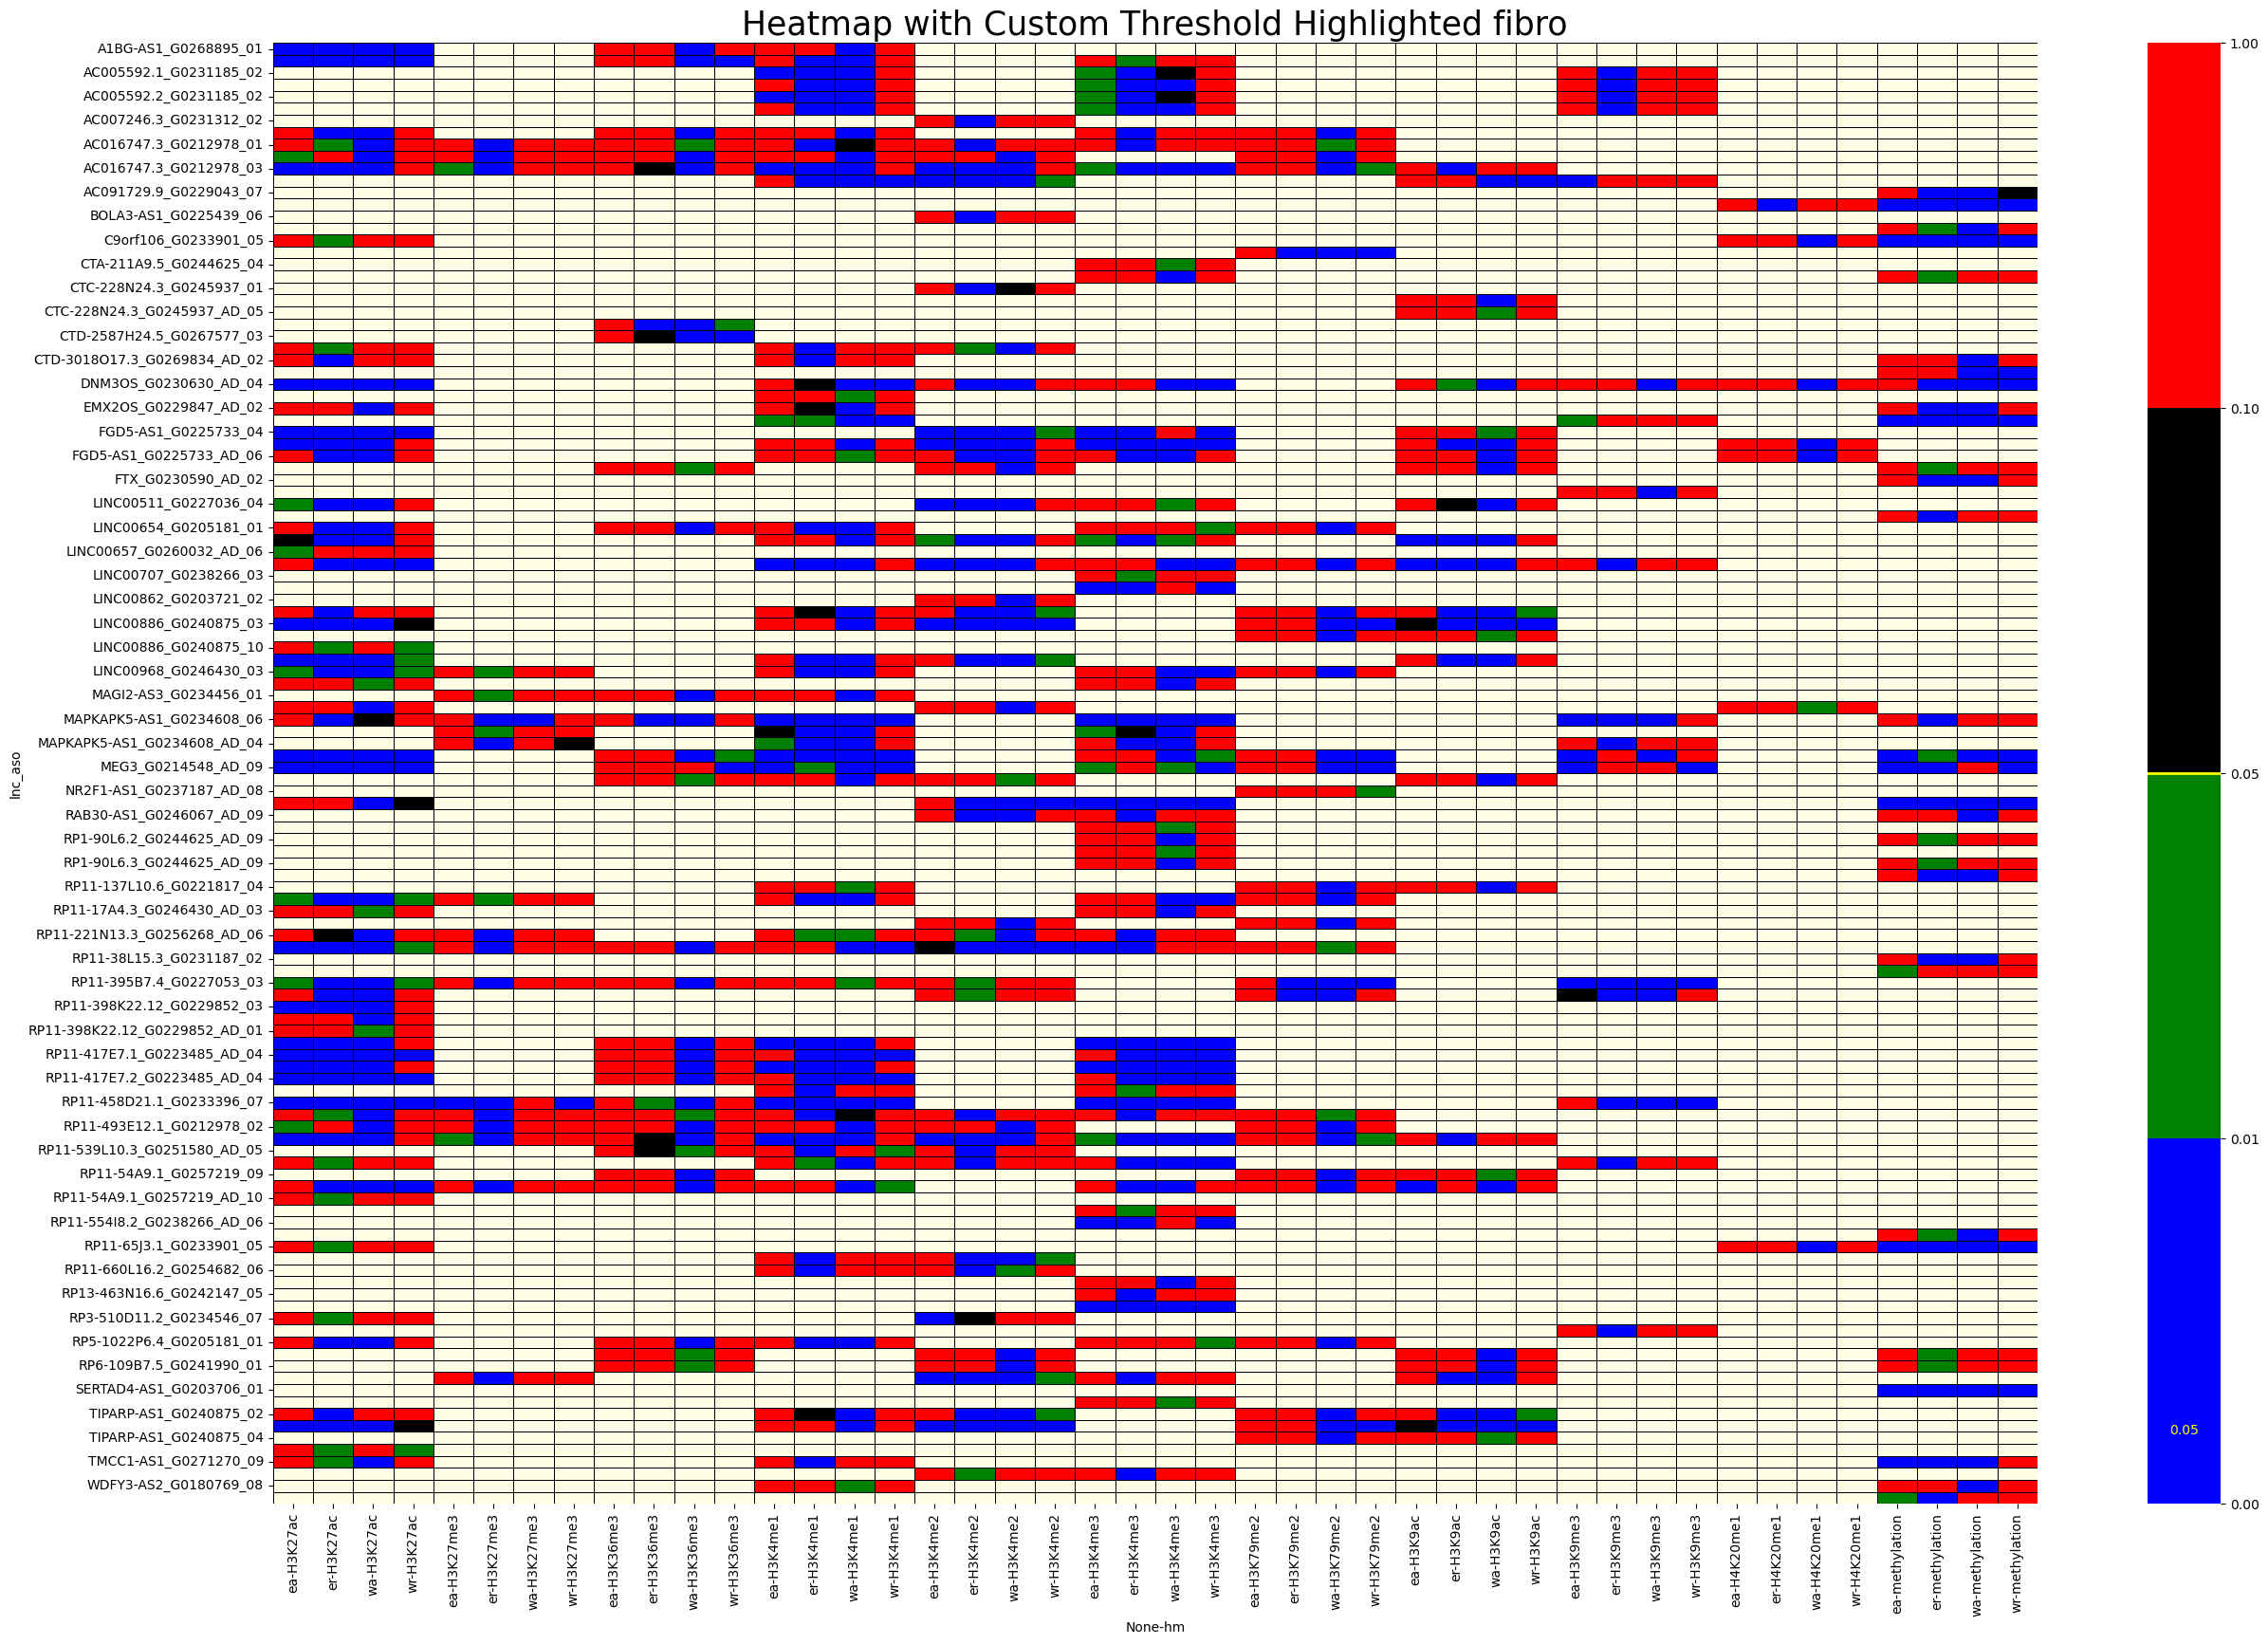

In [55]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"], gene_name_col="gene_name", exp="fibro")

/tmp/ipykernel_4879/4202973988.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df[gene_name_col] + "_" + df["aso"]


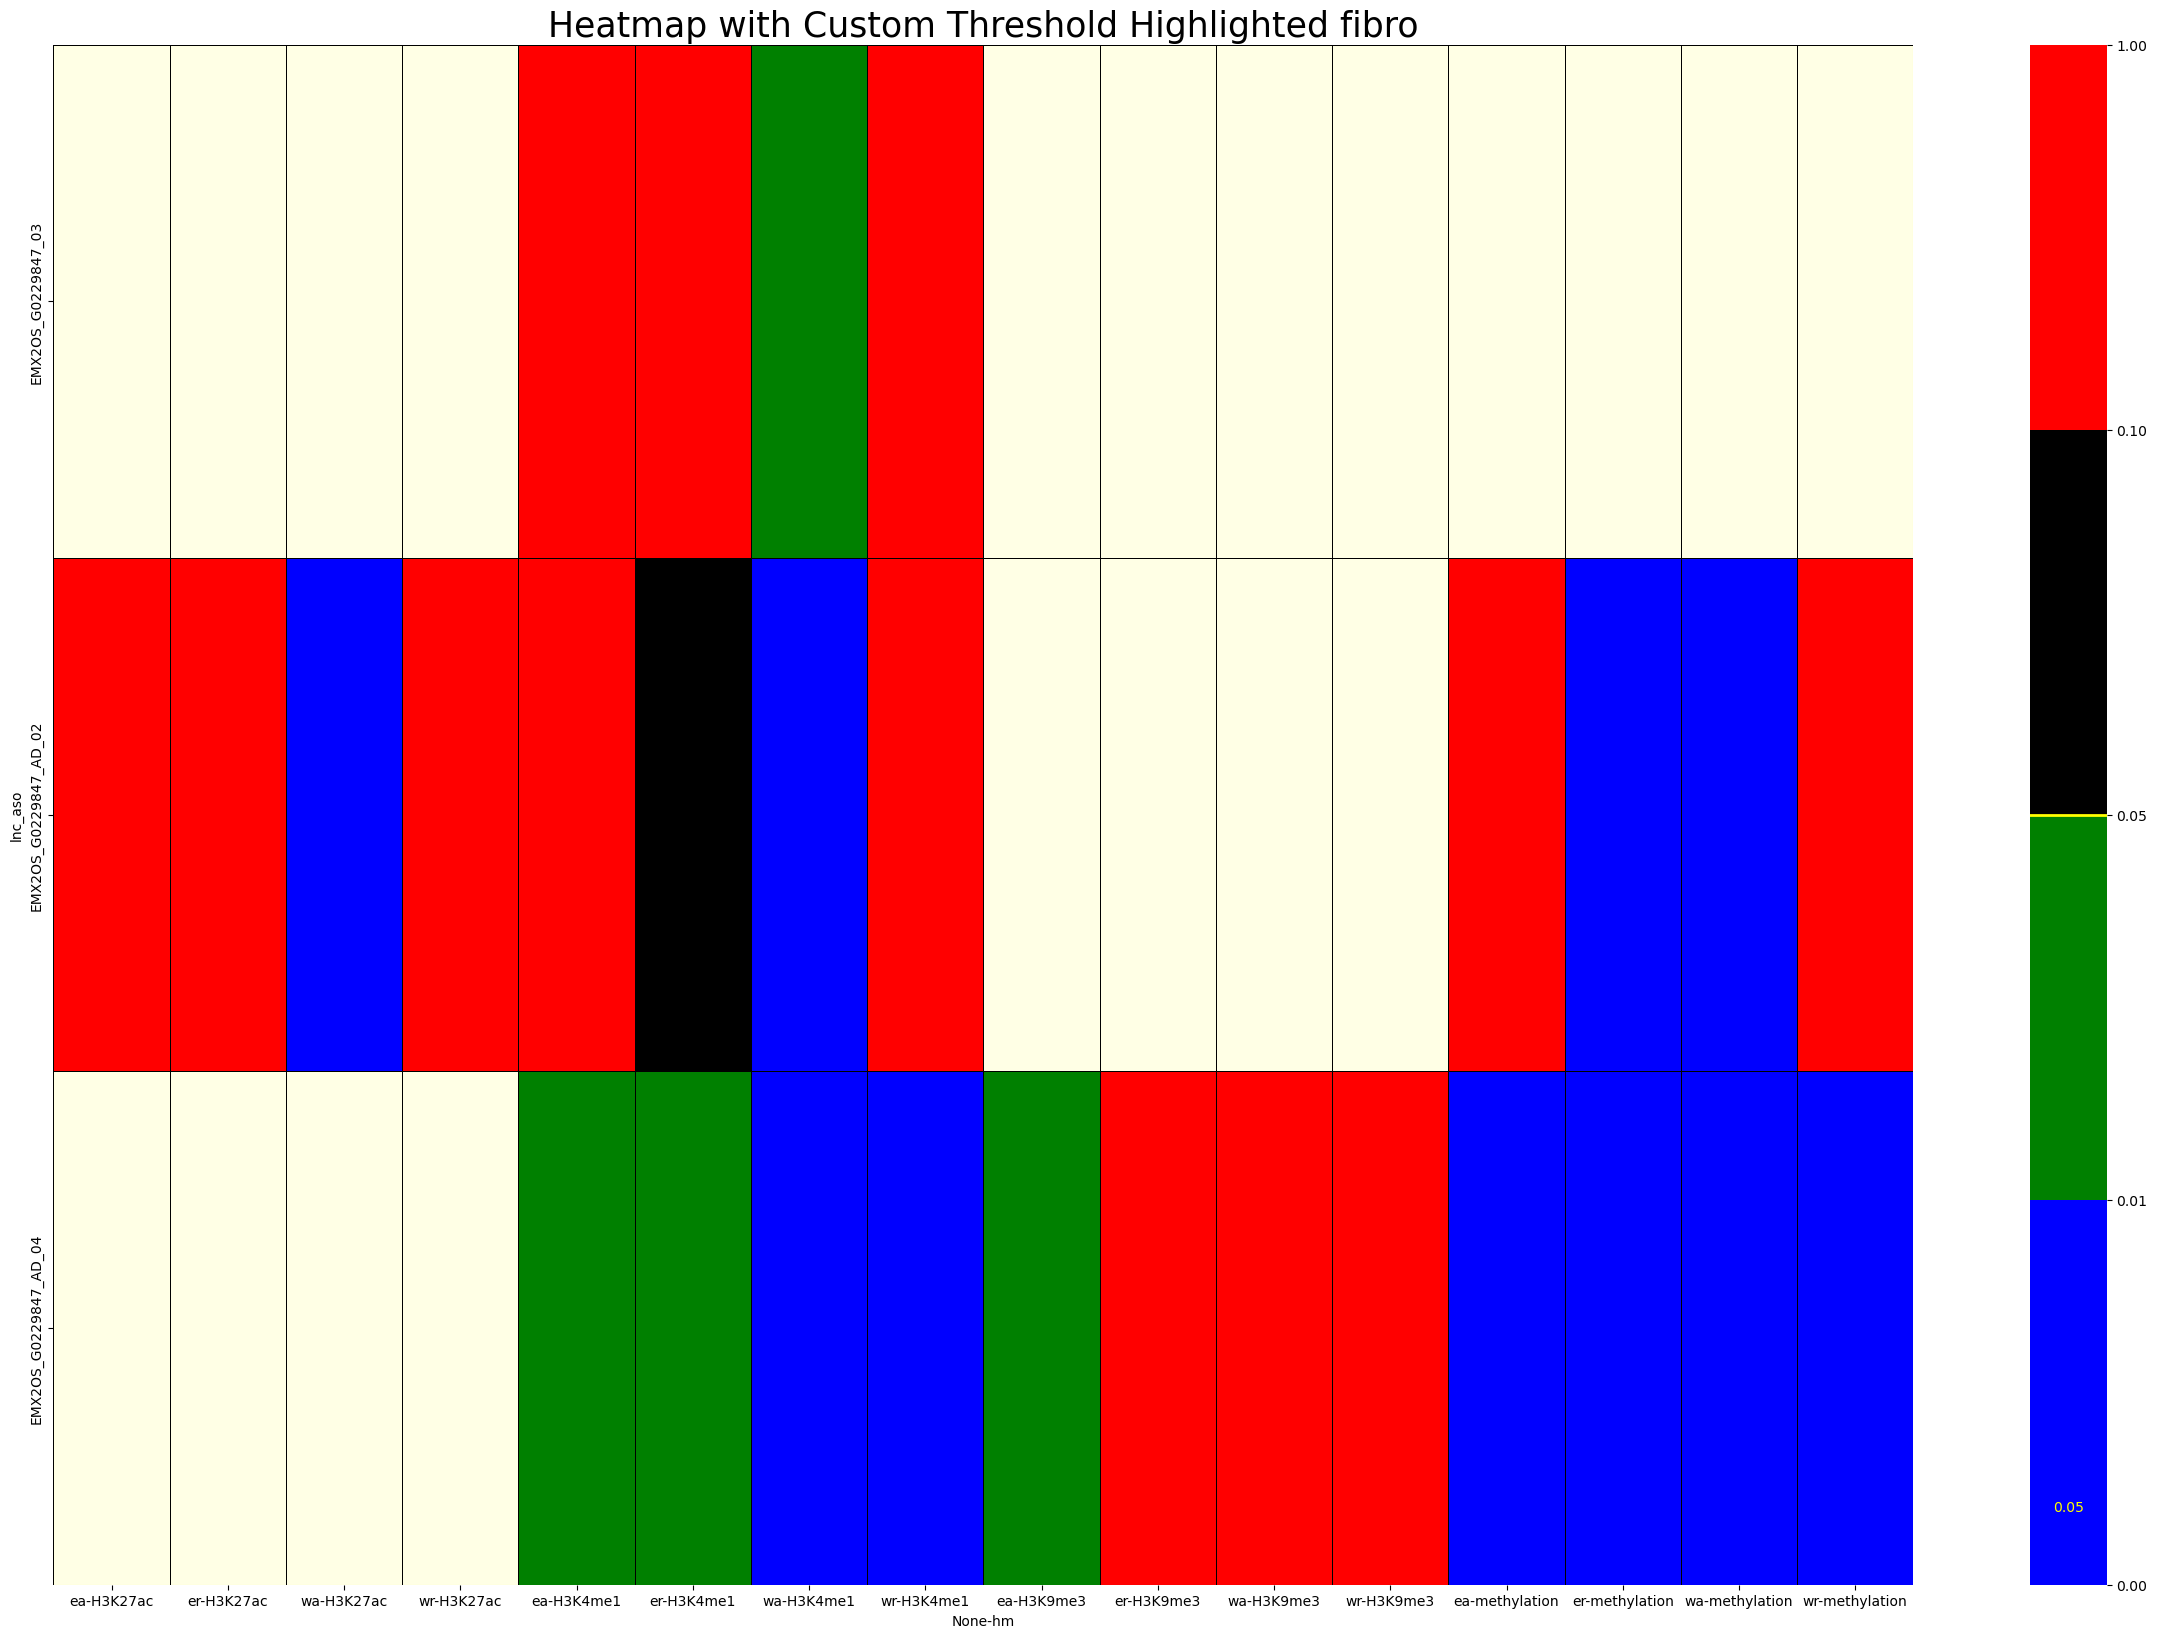

In [66]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"].query("gene_name == 'EMX2OS'"), gene_name_col="gene_name", exp="fibro")

/tmp/ipykernel_4879/4202973988.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df[gene_name_col] + "_" + df["aso"]


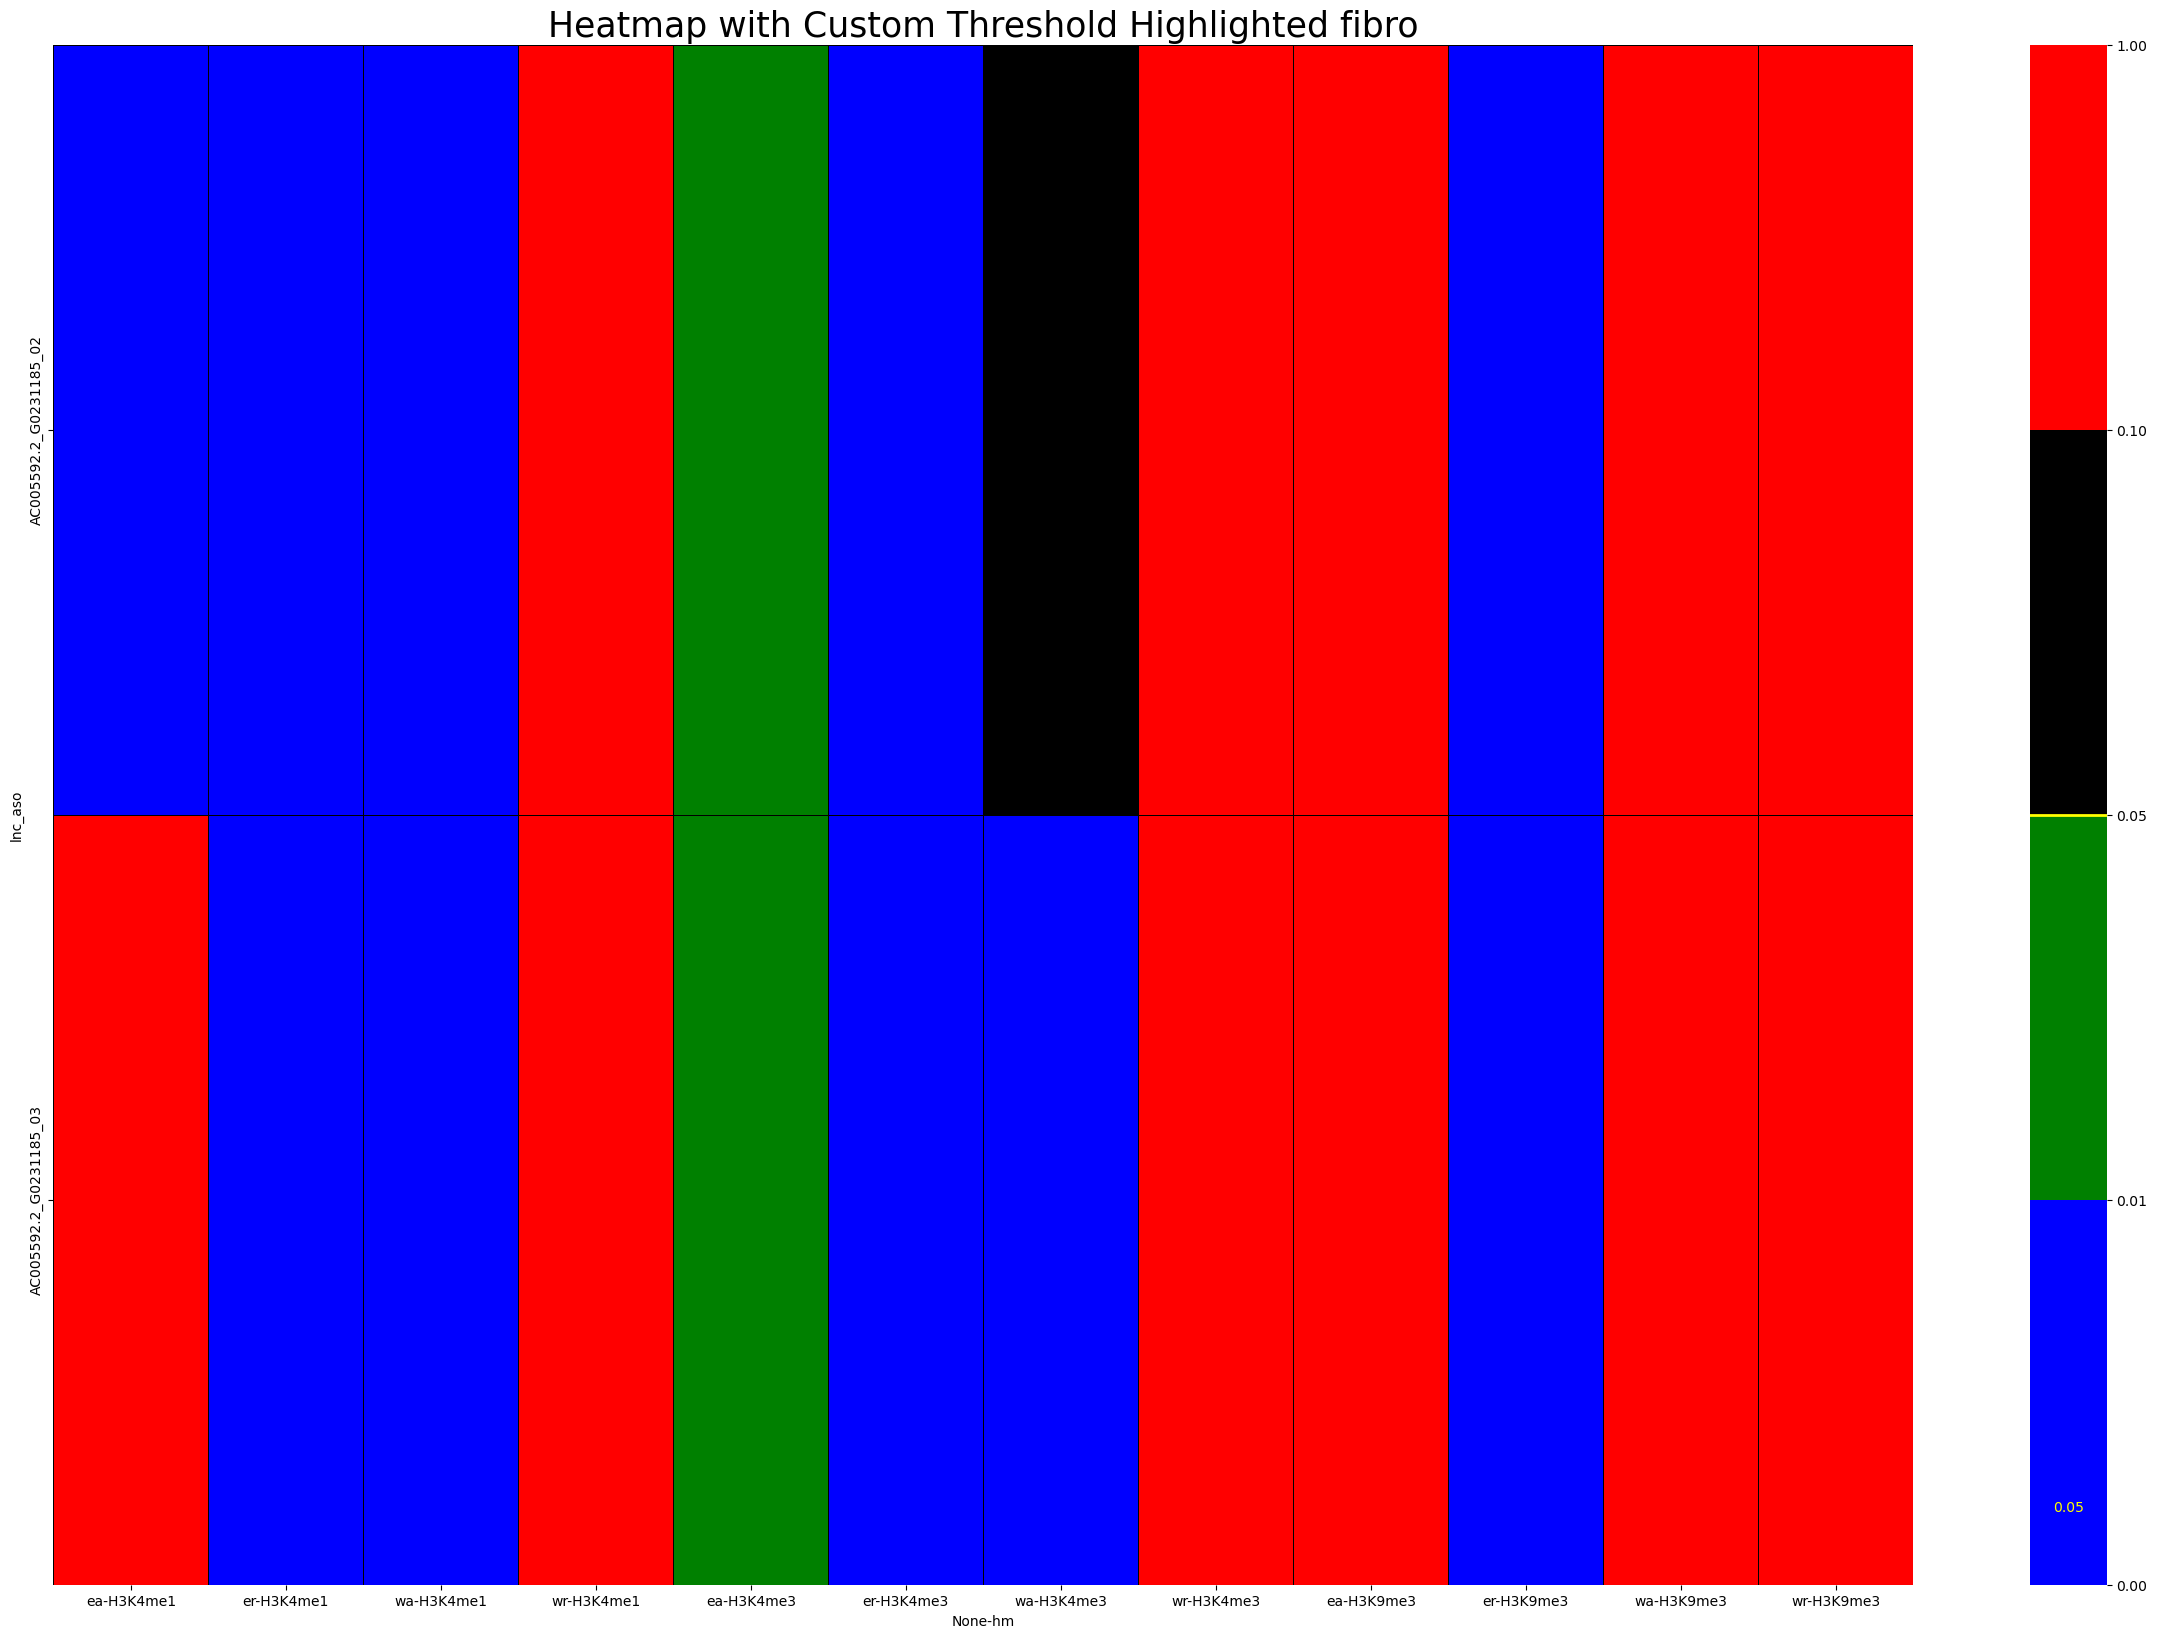

In [67]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"].query("gene_name == 'AC005592.2'"), gene_name_col="gene_name", exp="fibro")

/tmp/ipykernel_4879/4202973988.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df[gene_name_col] + "_" + df["aso"]


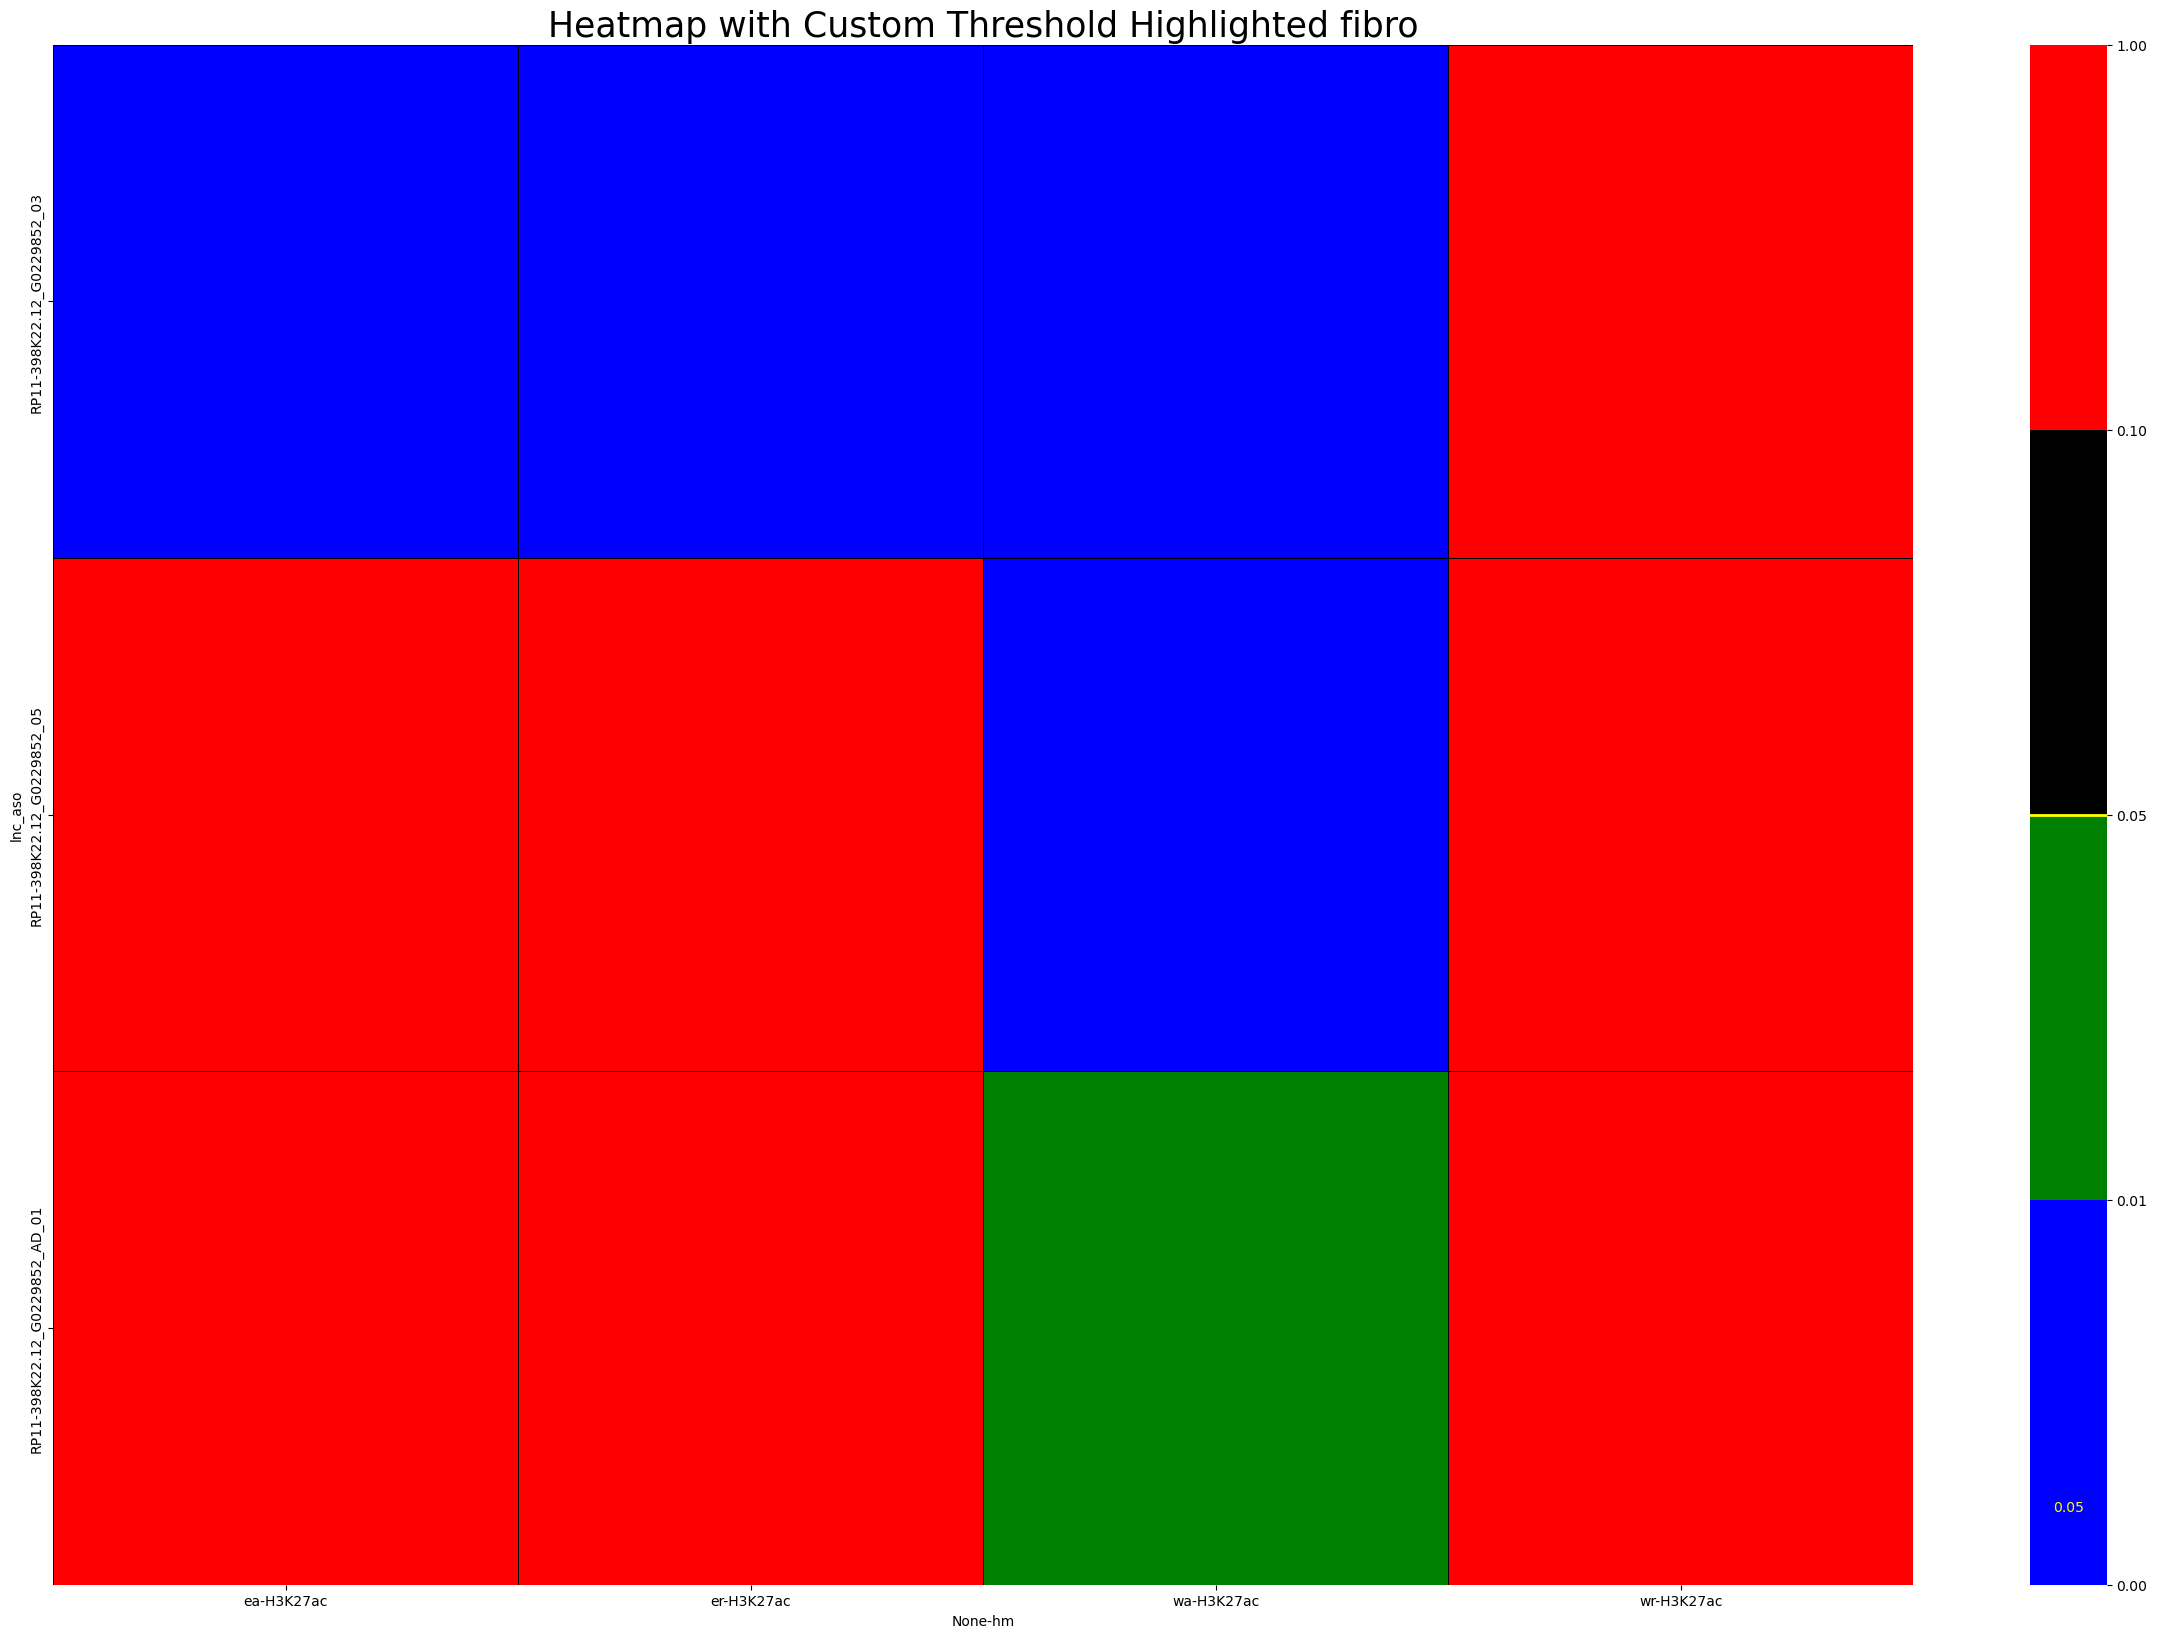

In [68]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"].query("gene_name == 'RP11-398K22.12'"), gene_name_col="gene_name", exp="fibro")

In [62]:
fisher_results_filt_by_exp["fibro"]

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,new-ens_gene,gene_name,lnc_aso
0,H4K20me1,ENSG00000225733,G0225733_AD_03,1.000000e+00,1.000000,5.921321e-04,1.00000,FGD5-AS1,FGD5-AS1-H4K20me1,FGD5-AS1-G0225733_AD_03-H4K20me1,ENSG00000225733,FGD5-AS1,FGD5-AS1_G0225733_AD_03
1,H4K20me1,ENSG00000225733,G0225733_AD_06,1.000000e+00,1.000000,1.821788e-03,1.00000,FGD5-AS1,FGD5-AS1-H4K20me1,FGD5-AS1-G0225733_AD_06-H4K20me1,ENSG00000225733,FGD5-AS1,FGD5-AS1_G0225733_AD_06
2,H4K20me1,ENSG00000230630,G0230630_AD_04,1.000000e+00,1.000000,2.857240e-07,1.00000,DNM3OS,DNM3OS-H4K20me1,DNM3OS-G0230630_AD_04-H4K20me1,ENSG00000230630,DNM3OS,DNM3OS_G0230630_AD_04
3,H4K20me1,ENSG00000233527,G0233527_02,5.630637e-03,1.000000,1.000000e+00,1.00000,ZNF529-AS1,ZNF529-AS1-H4K20me1,ZNF529-AS1-G0233527_02-H4K20me1,ENSG00000233527,AC092295.7,AC092295.7_G0233527_02
4,H4K20me1,ENSG00000233901,G0233901_05,1.000000e+00,1.000000,1.821788e-03,1.00000,LINC01503,LINC01503-H4K20me1,LINC01503-G0233901_05-H4K20me1,ENSG00000233901,C9orf106,C9orf106_G0233901_05
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,H3K4me1,ENSG00000271889,G0212978_01,5.210413e-03,1.000000,6.934834e-02,1.00000,C2orf74-AS1,C2orf74-AS1-H3K4me1,C2orf74-AS1-G0212978_01-H3K4me1,ENSG00000271889,RP11-493E12.1,RP11-493E12.1_G0212978_01
370,H3K4me1,ENSG00000271889,G0212978_02,1.000000e+00,0.398019,2.499270e-03,0.93502,C2orf74-AS1,C2orf74-AS1-H3K4me1,C2orf74-AS1-G0212978_02-H3K4me1,ENSG00000271889,AC016747.3,AC016747.3_G0212978_02
371,H3K4me1,ENSG00000271889,G0212978_02,1.000000e+00,0.398019,2.499270e-03,0.93502,C2orf74-AS1,C2orf74-AS1-H3K4me1,C2orf74-AS1-G0212978_02-H3K4me1,ENSG00000271889,RP11-493E12.1,RP11-493E12.1_G0212978_02
372,H3K4me1,ENSG00000271889,G0212978_03,2.002773e-21,0.000583,7.196830e-12,1.00000,C2orf74-AS1,C2orf74-AS1-H3K4me1,C2orf74-AS1-G0212978_03-H3K4me1,ENSG00000271889,AC016747.3,AC016747.3_G0212978_03


/tmp/ipykernel_4879/4202973988.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df[gene_name_col] + "_" + df["aso"]


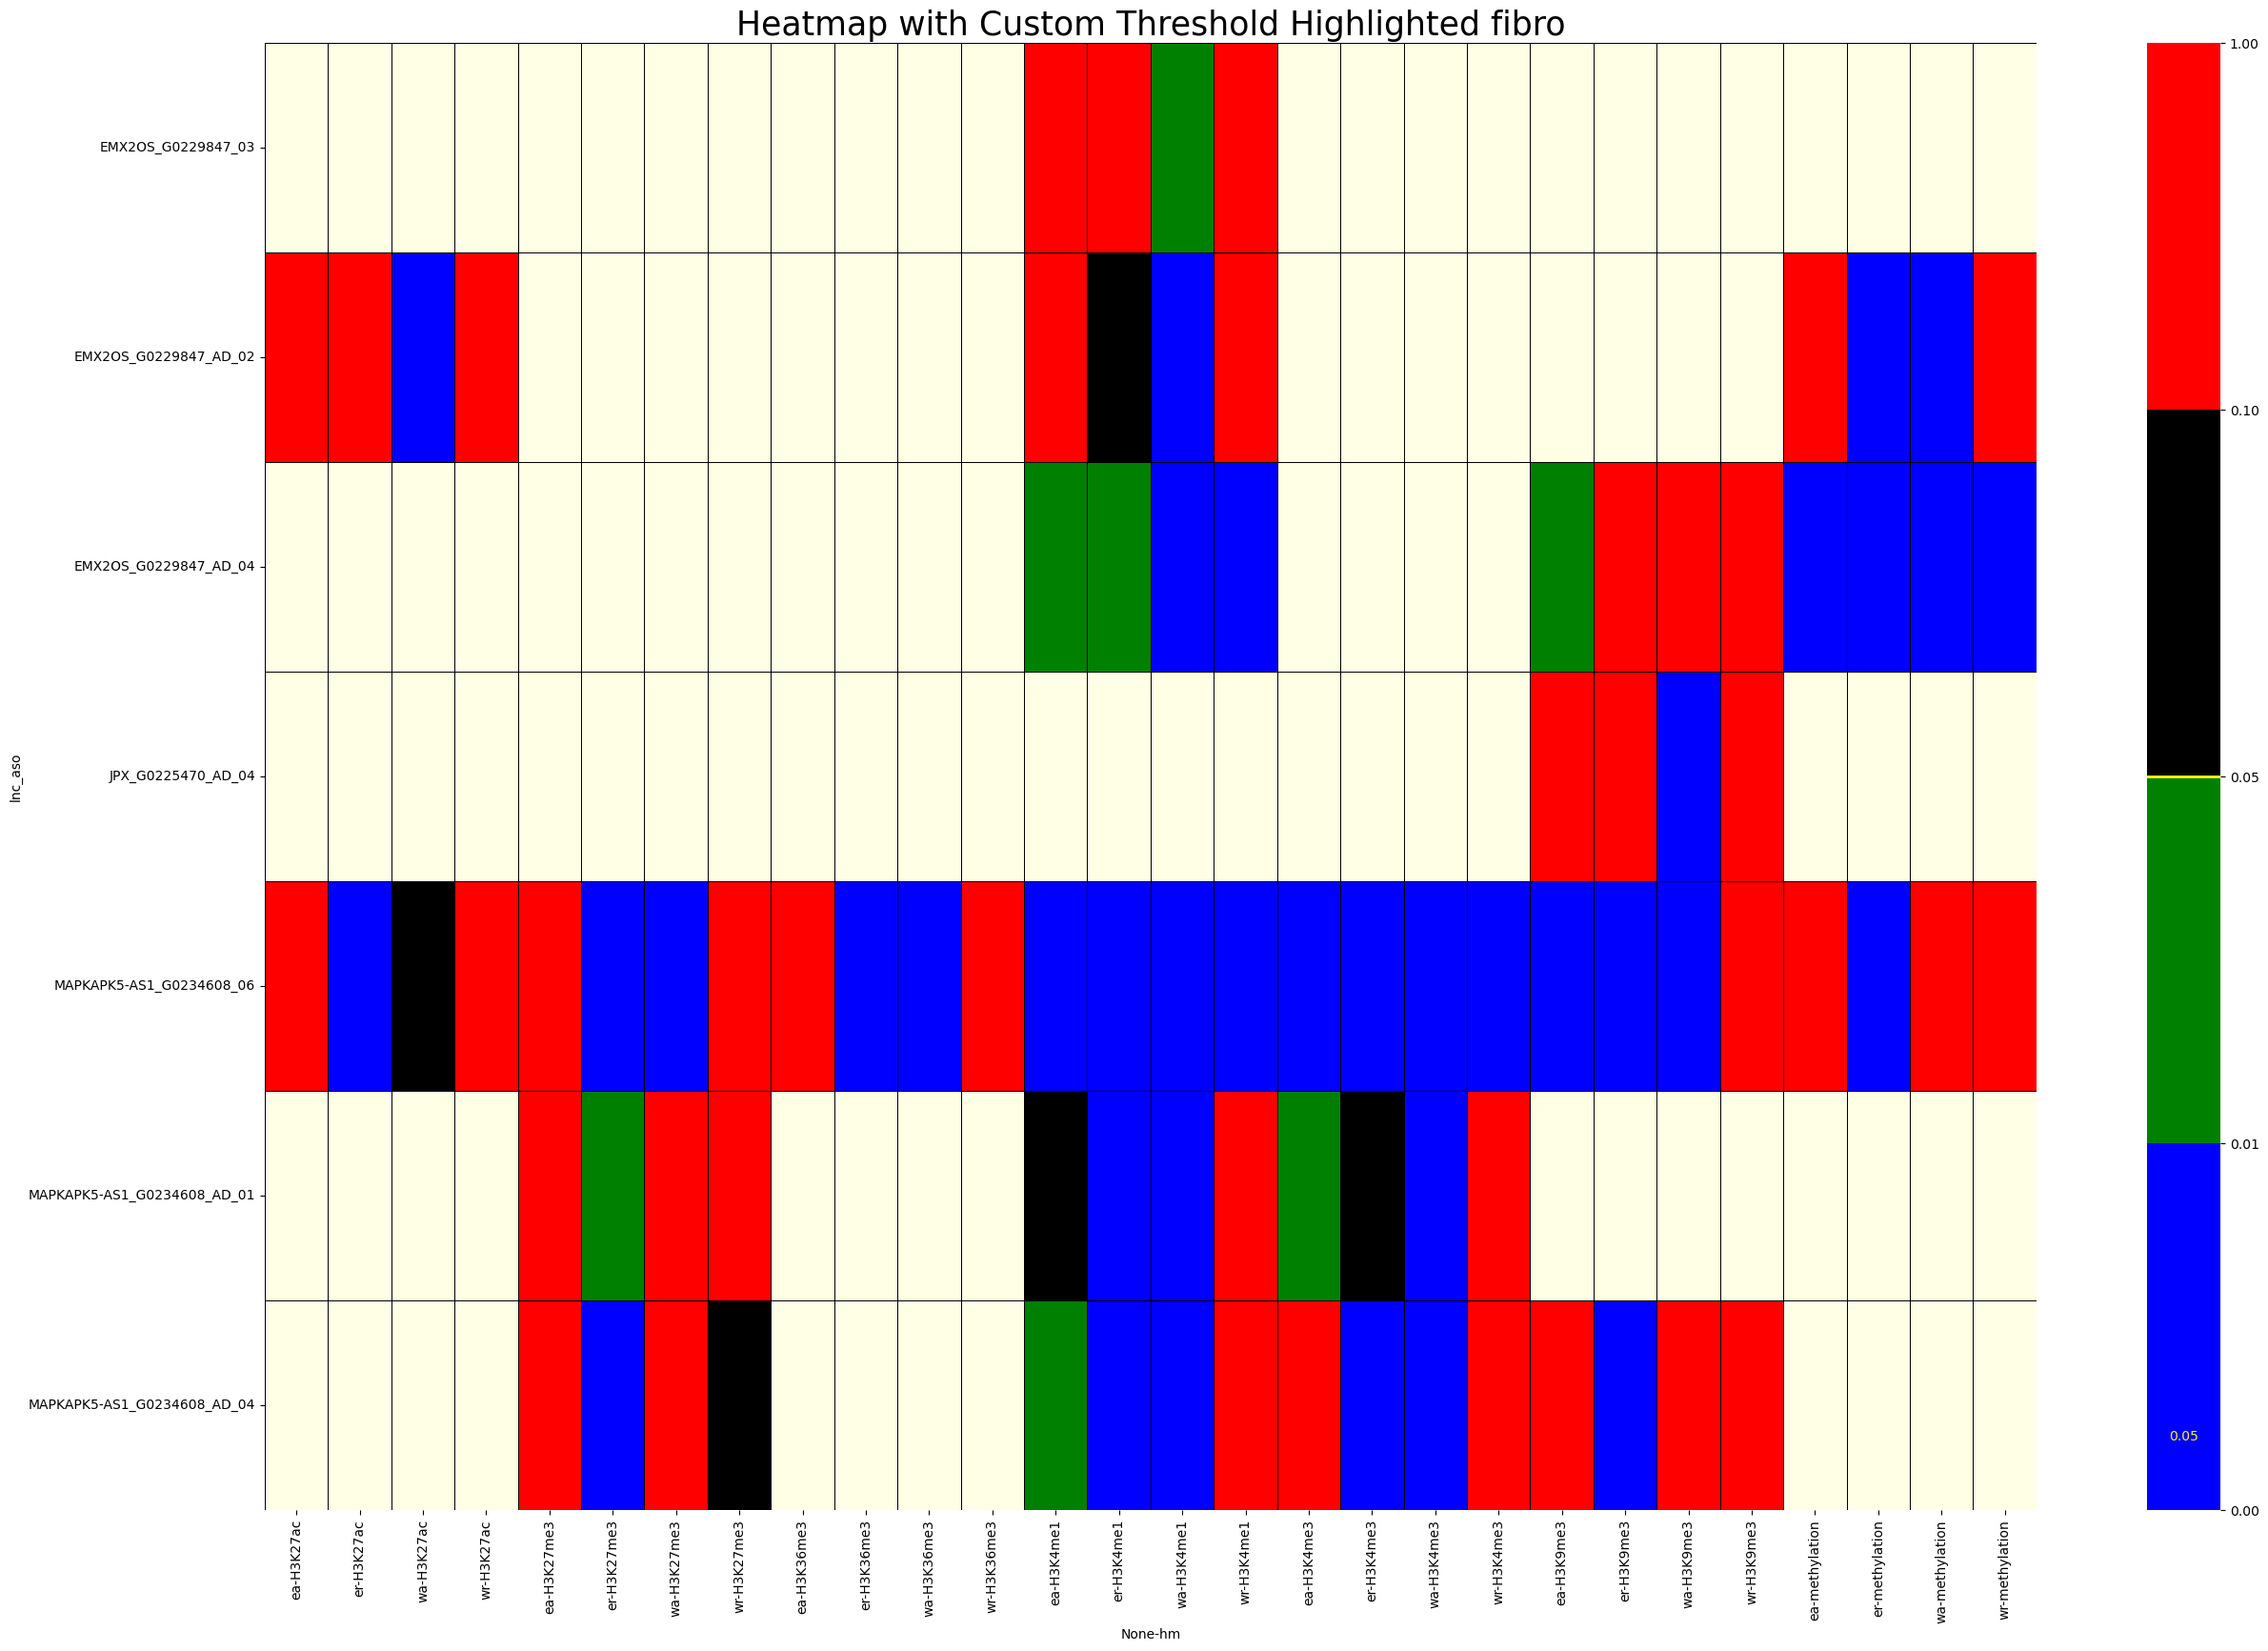

In [56]:
mask = fisher_results_filt_by_exp["fibro"]["lnc"].apply(lambda x: x in df_our_chipseq_res_updated["lnc"].to_list())
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"][mask], exp="fibro", gene_name_col="gene_name")

In [217]:
df_our_chipseq_res_updated

,old-lnc,hm,lnc_ens,lnc,lnc-hm
0,FGD5,H3K9ac,ENSG00000154783,FGD5,FGD5-H3K9ac
1,EMX2OS,H3K9ac,ENSG00000229847,EMX2OS,EMX2OS-H3K9ac
2,AC005592.2,H3K9me3,ENSG00000231185,SPRY4-AS1,SPRY4-AS1-H3K9me3
3,RP11-398K22.12,H3K27ac,ENSG00000229852,KHDC1-AS1,KHDC1-AS1-H3K27ac
4,CTD-2587H24.5,H3K36me3,ENSG00000267577,DNAAF3-AS1,DNAAF3-AS1-H3K36me3
5,JPX,H3K9me3,ENSG00000225470,JPX,JPX-H3K9me3
6,MAPKAPK5-AS1,H3K27me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3
7,MAPKAPK5-AS1,H3K4me3,ENSG00000234608,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3
8,NCA,H3K9me3,NaN,NaN,NaN
9,NCA,H3K36me3,NaN,NaN,NaN


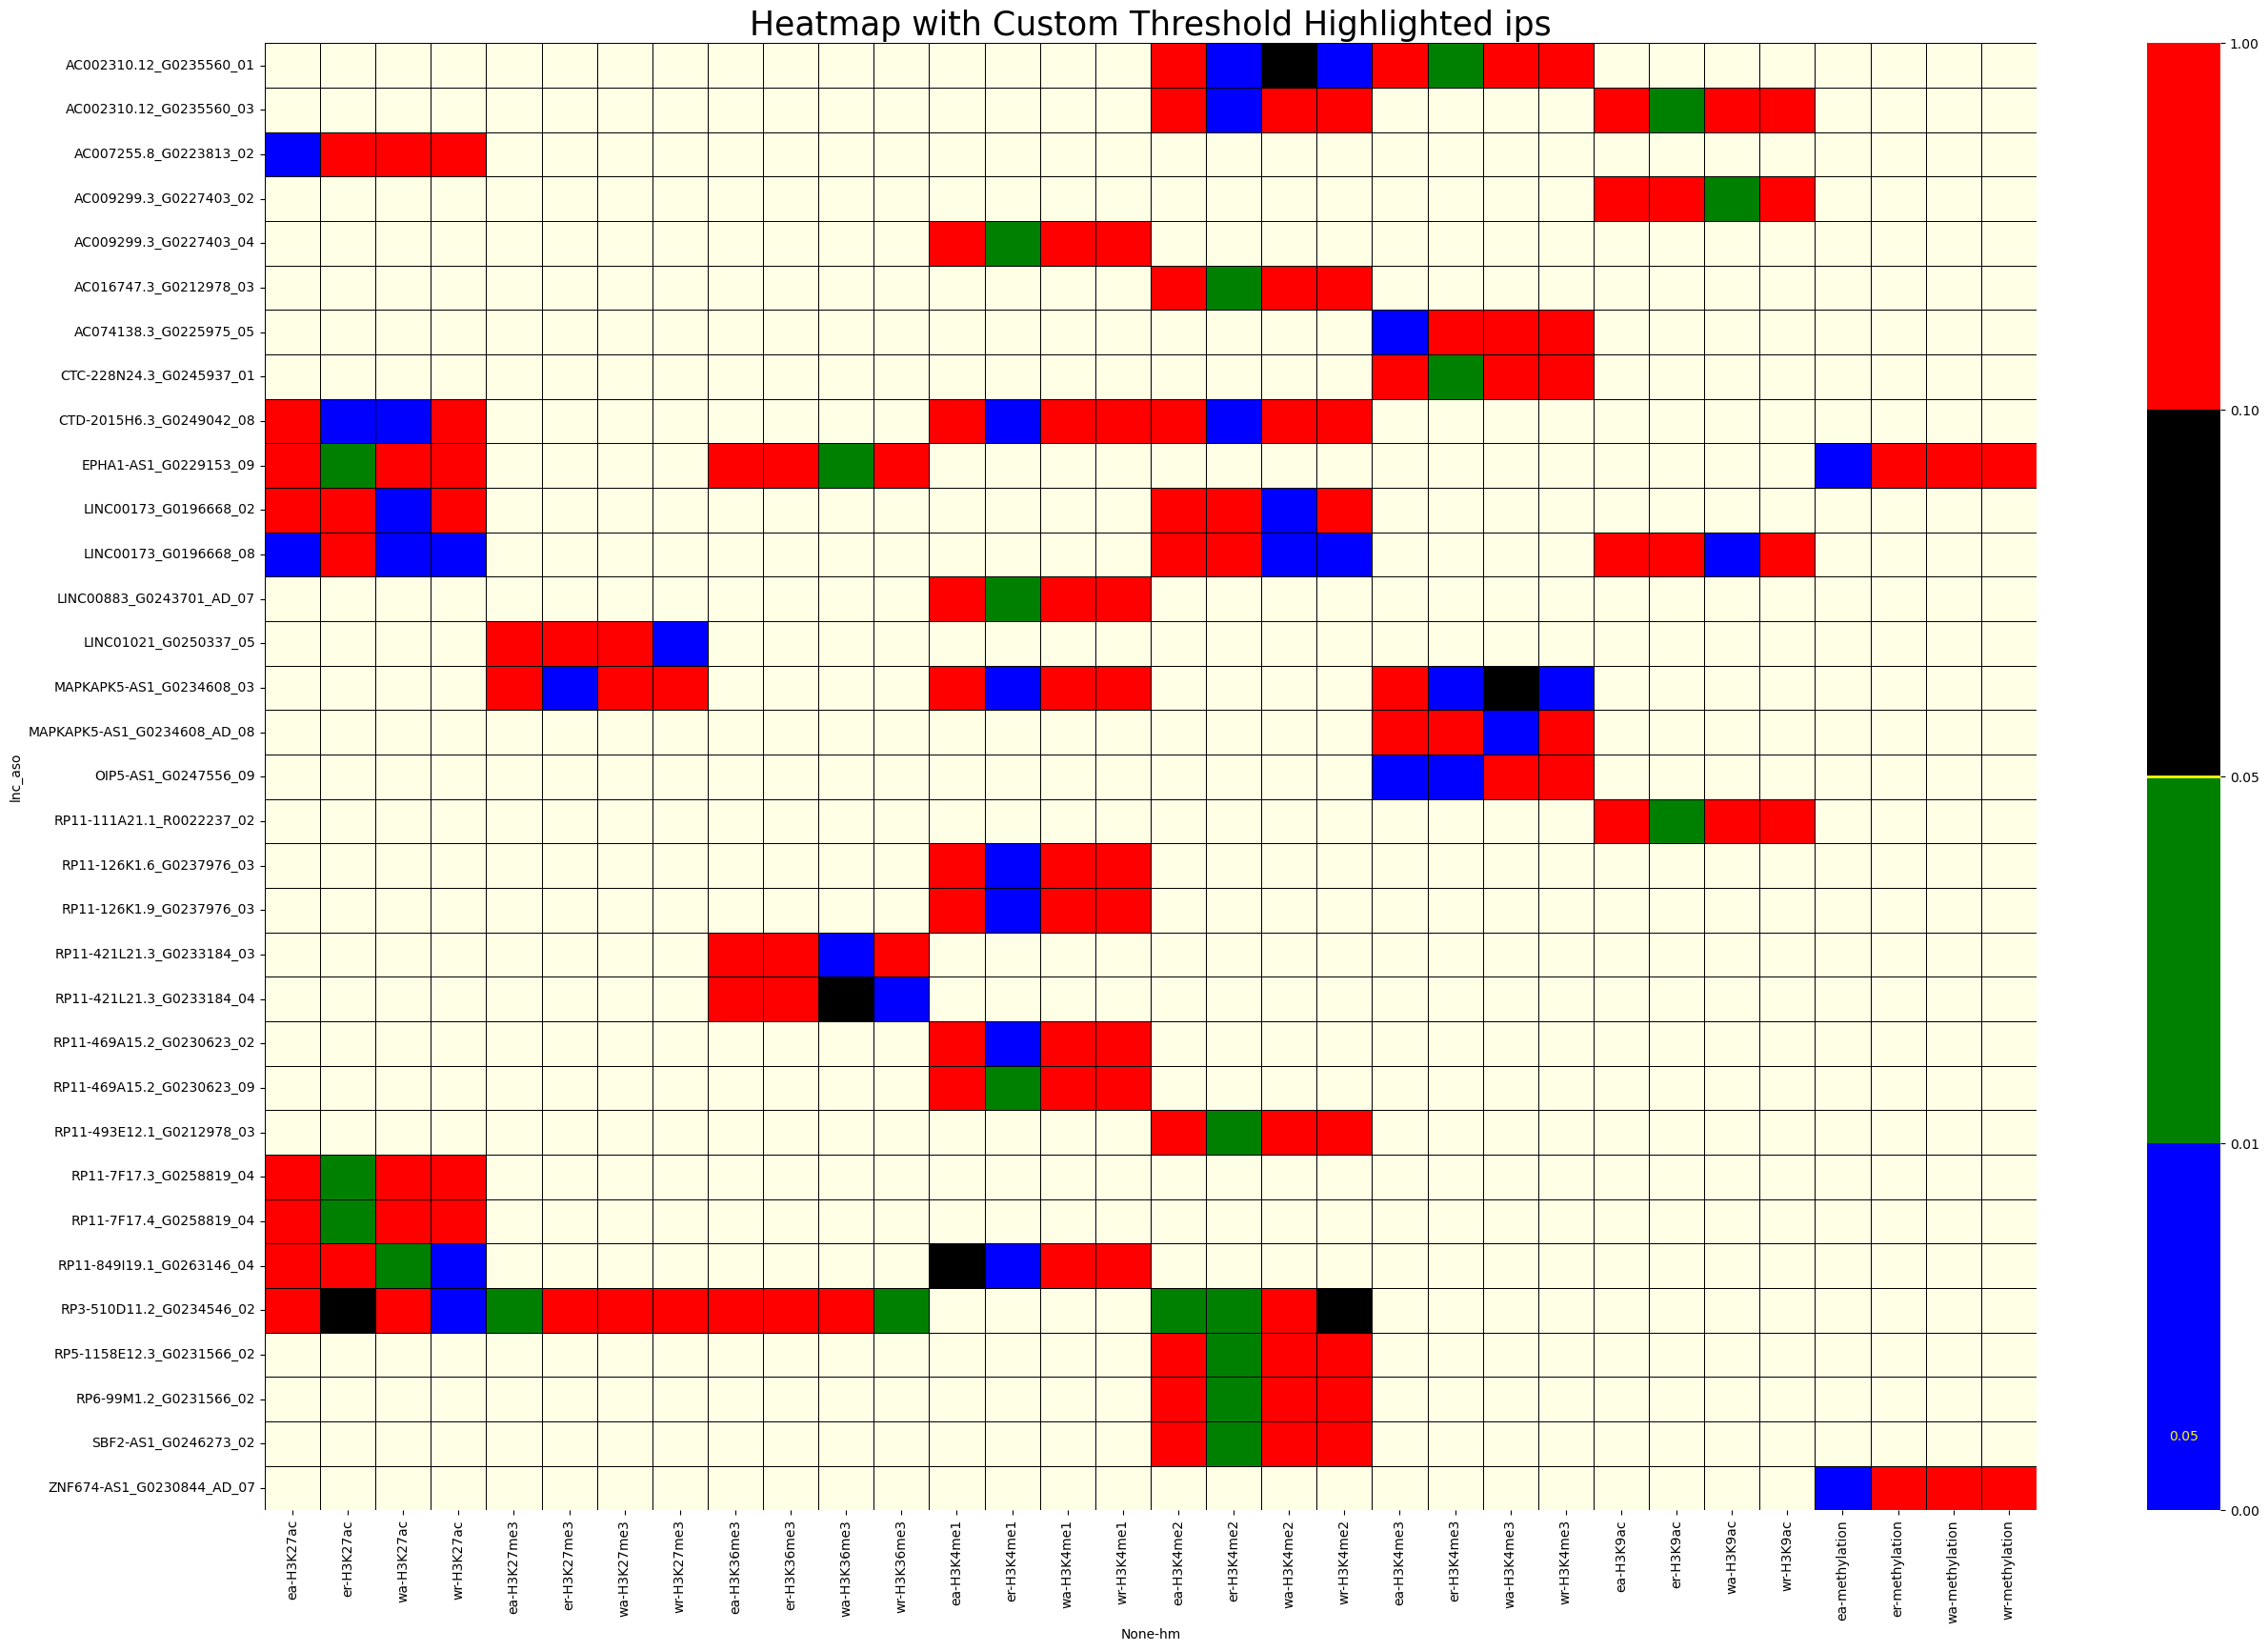

In [57]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["ips"], exp="ips", gene_name_col="gene_name")

/tmp/ipykernel_4879/4202973988.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df[gene_name_col] + "_" + df["aso"]


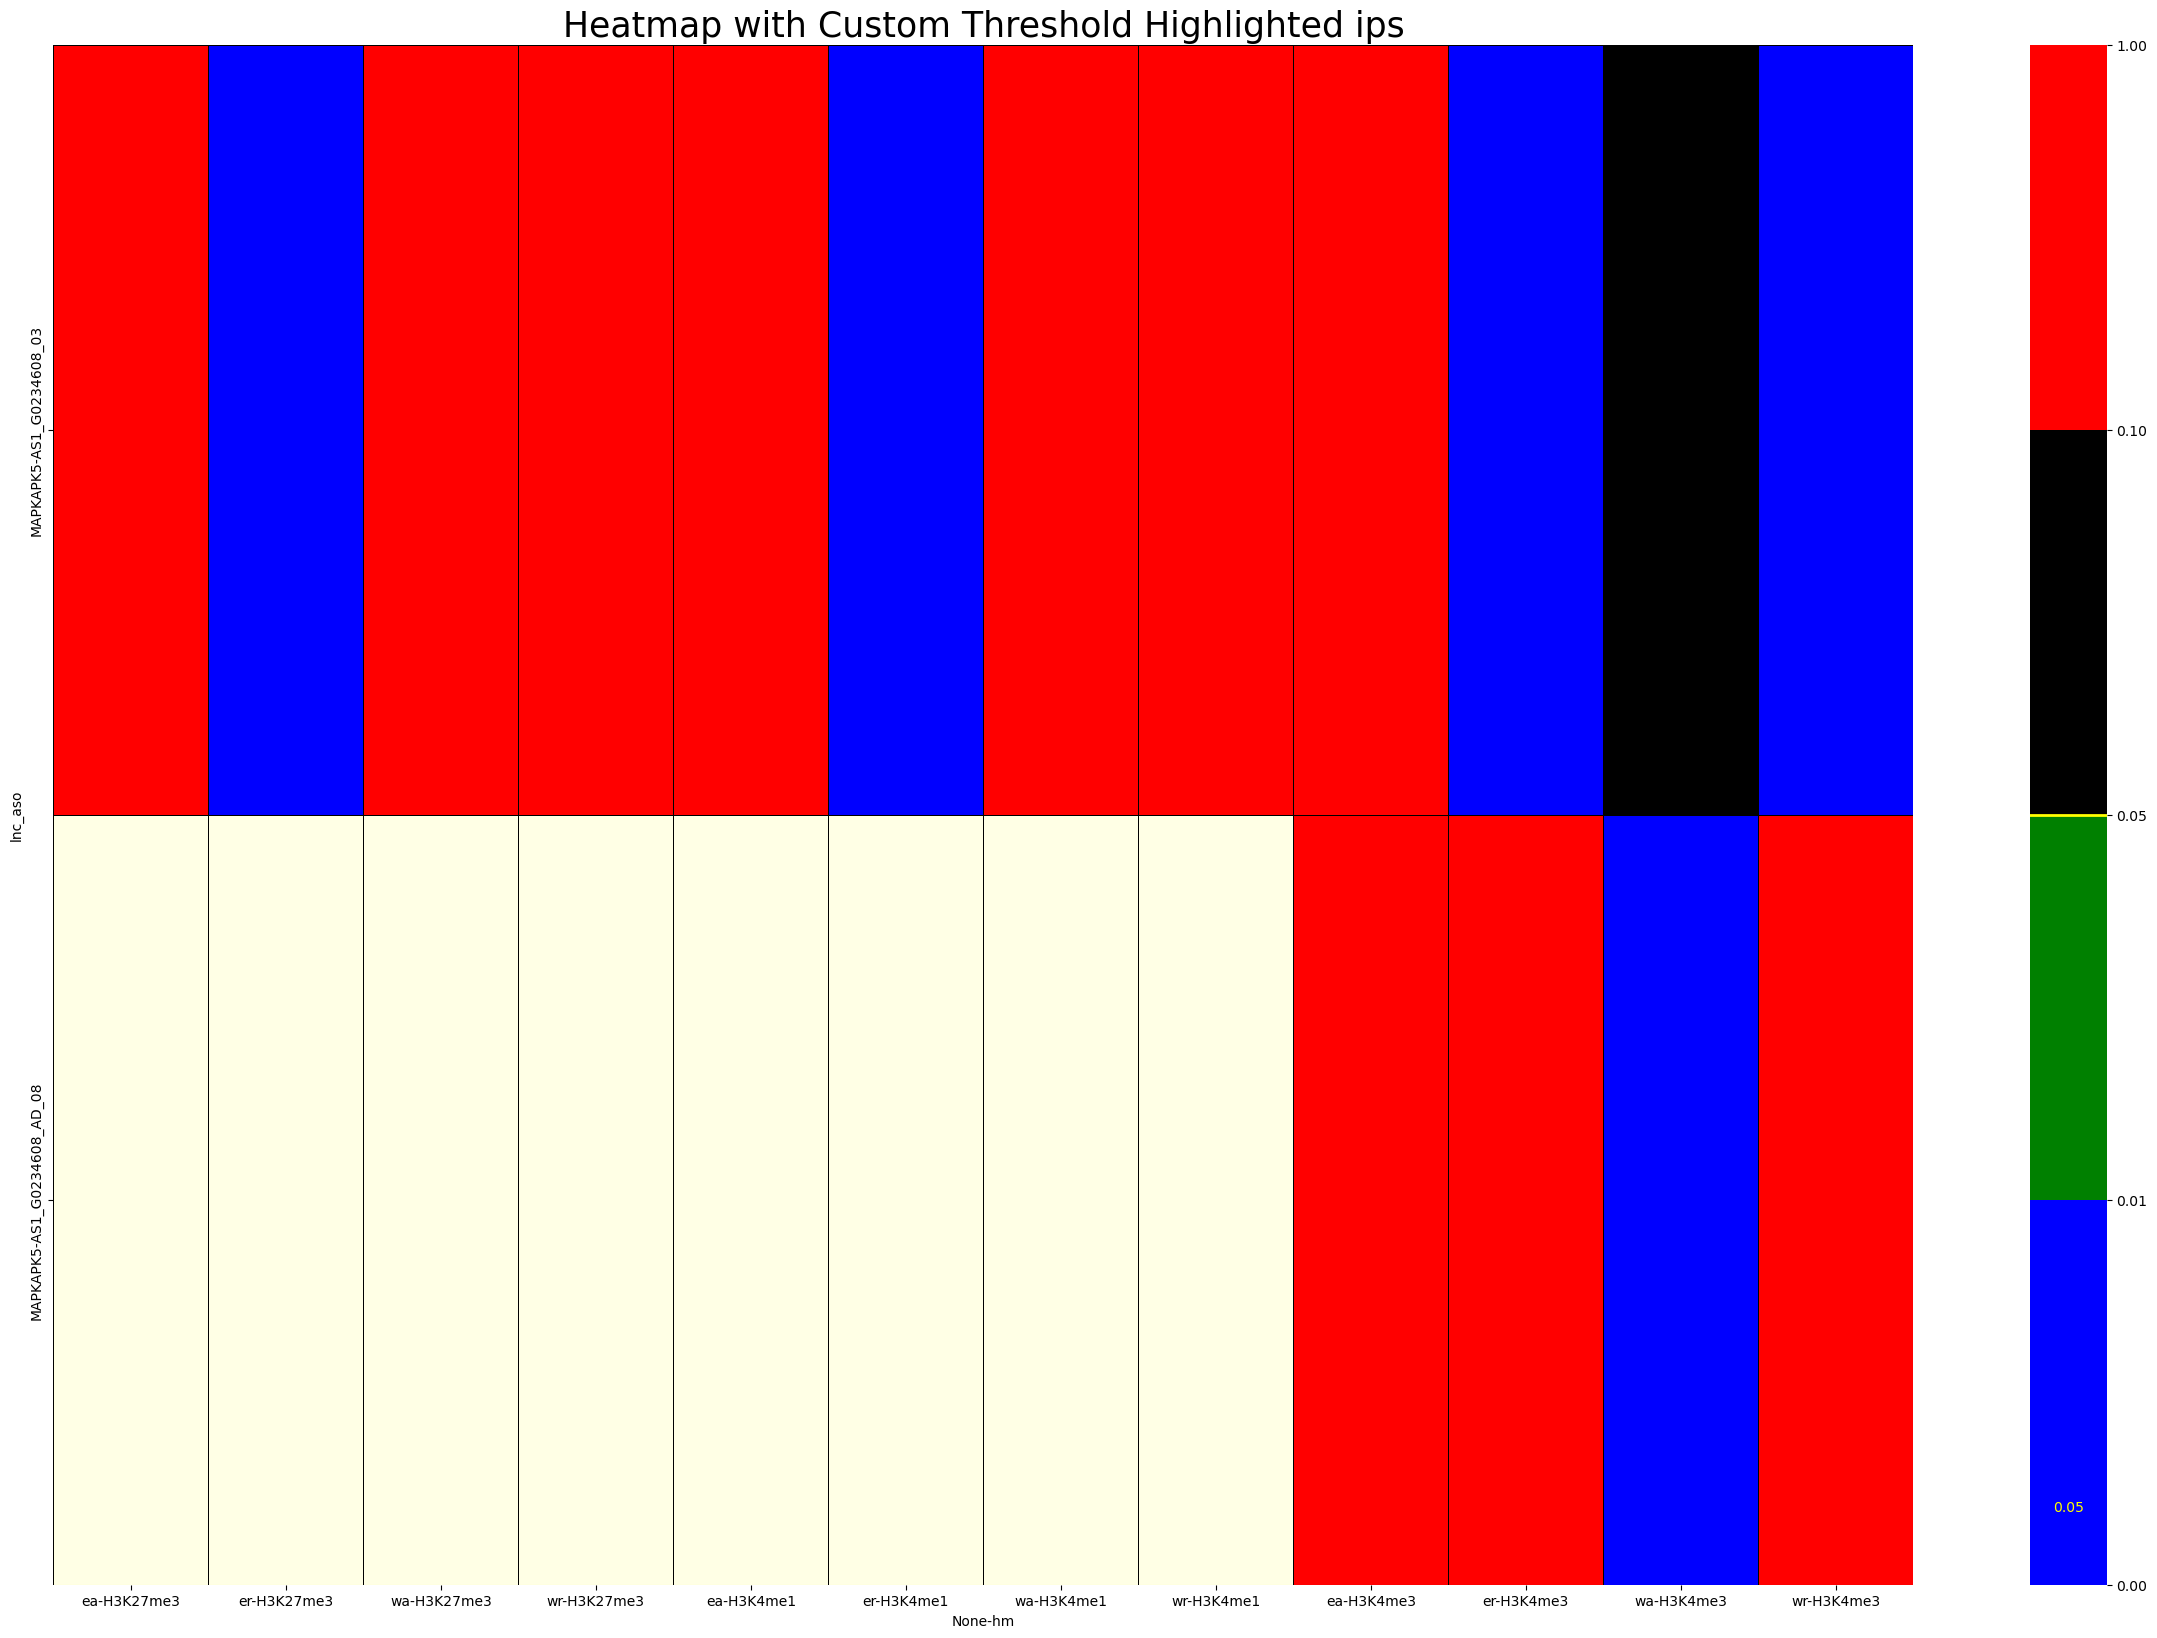

In [58]:
mask = fisher_results_filt_by_exp["ips"]["lnc"].apply(lambda x: x in df_our_chipseq_res_updated["lnc"].to_list())
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["ips"][mask], exp="ips", gene_name_col="gene_name")

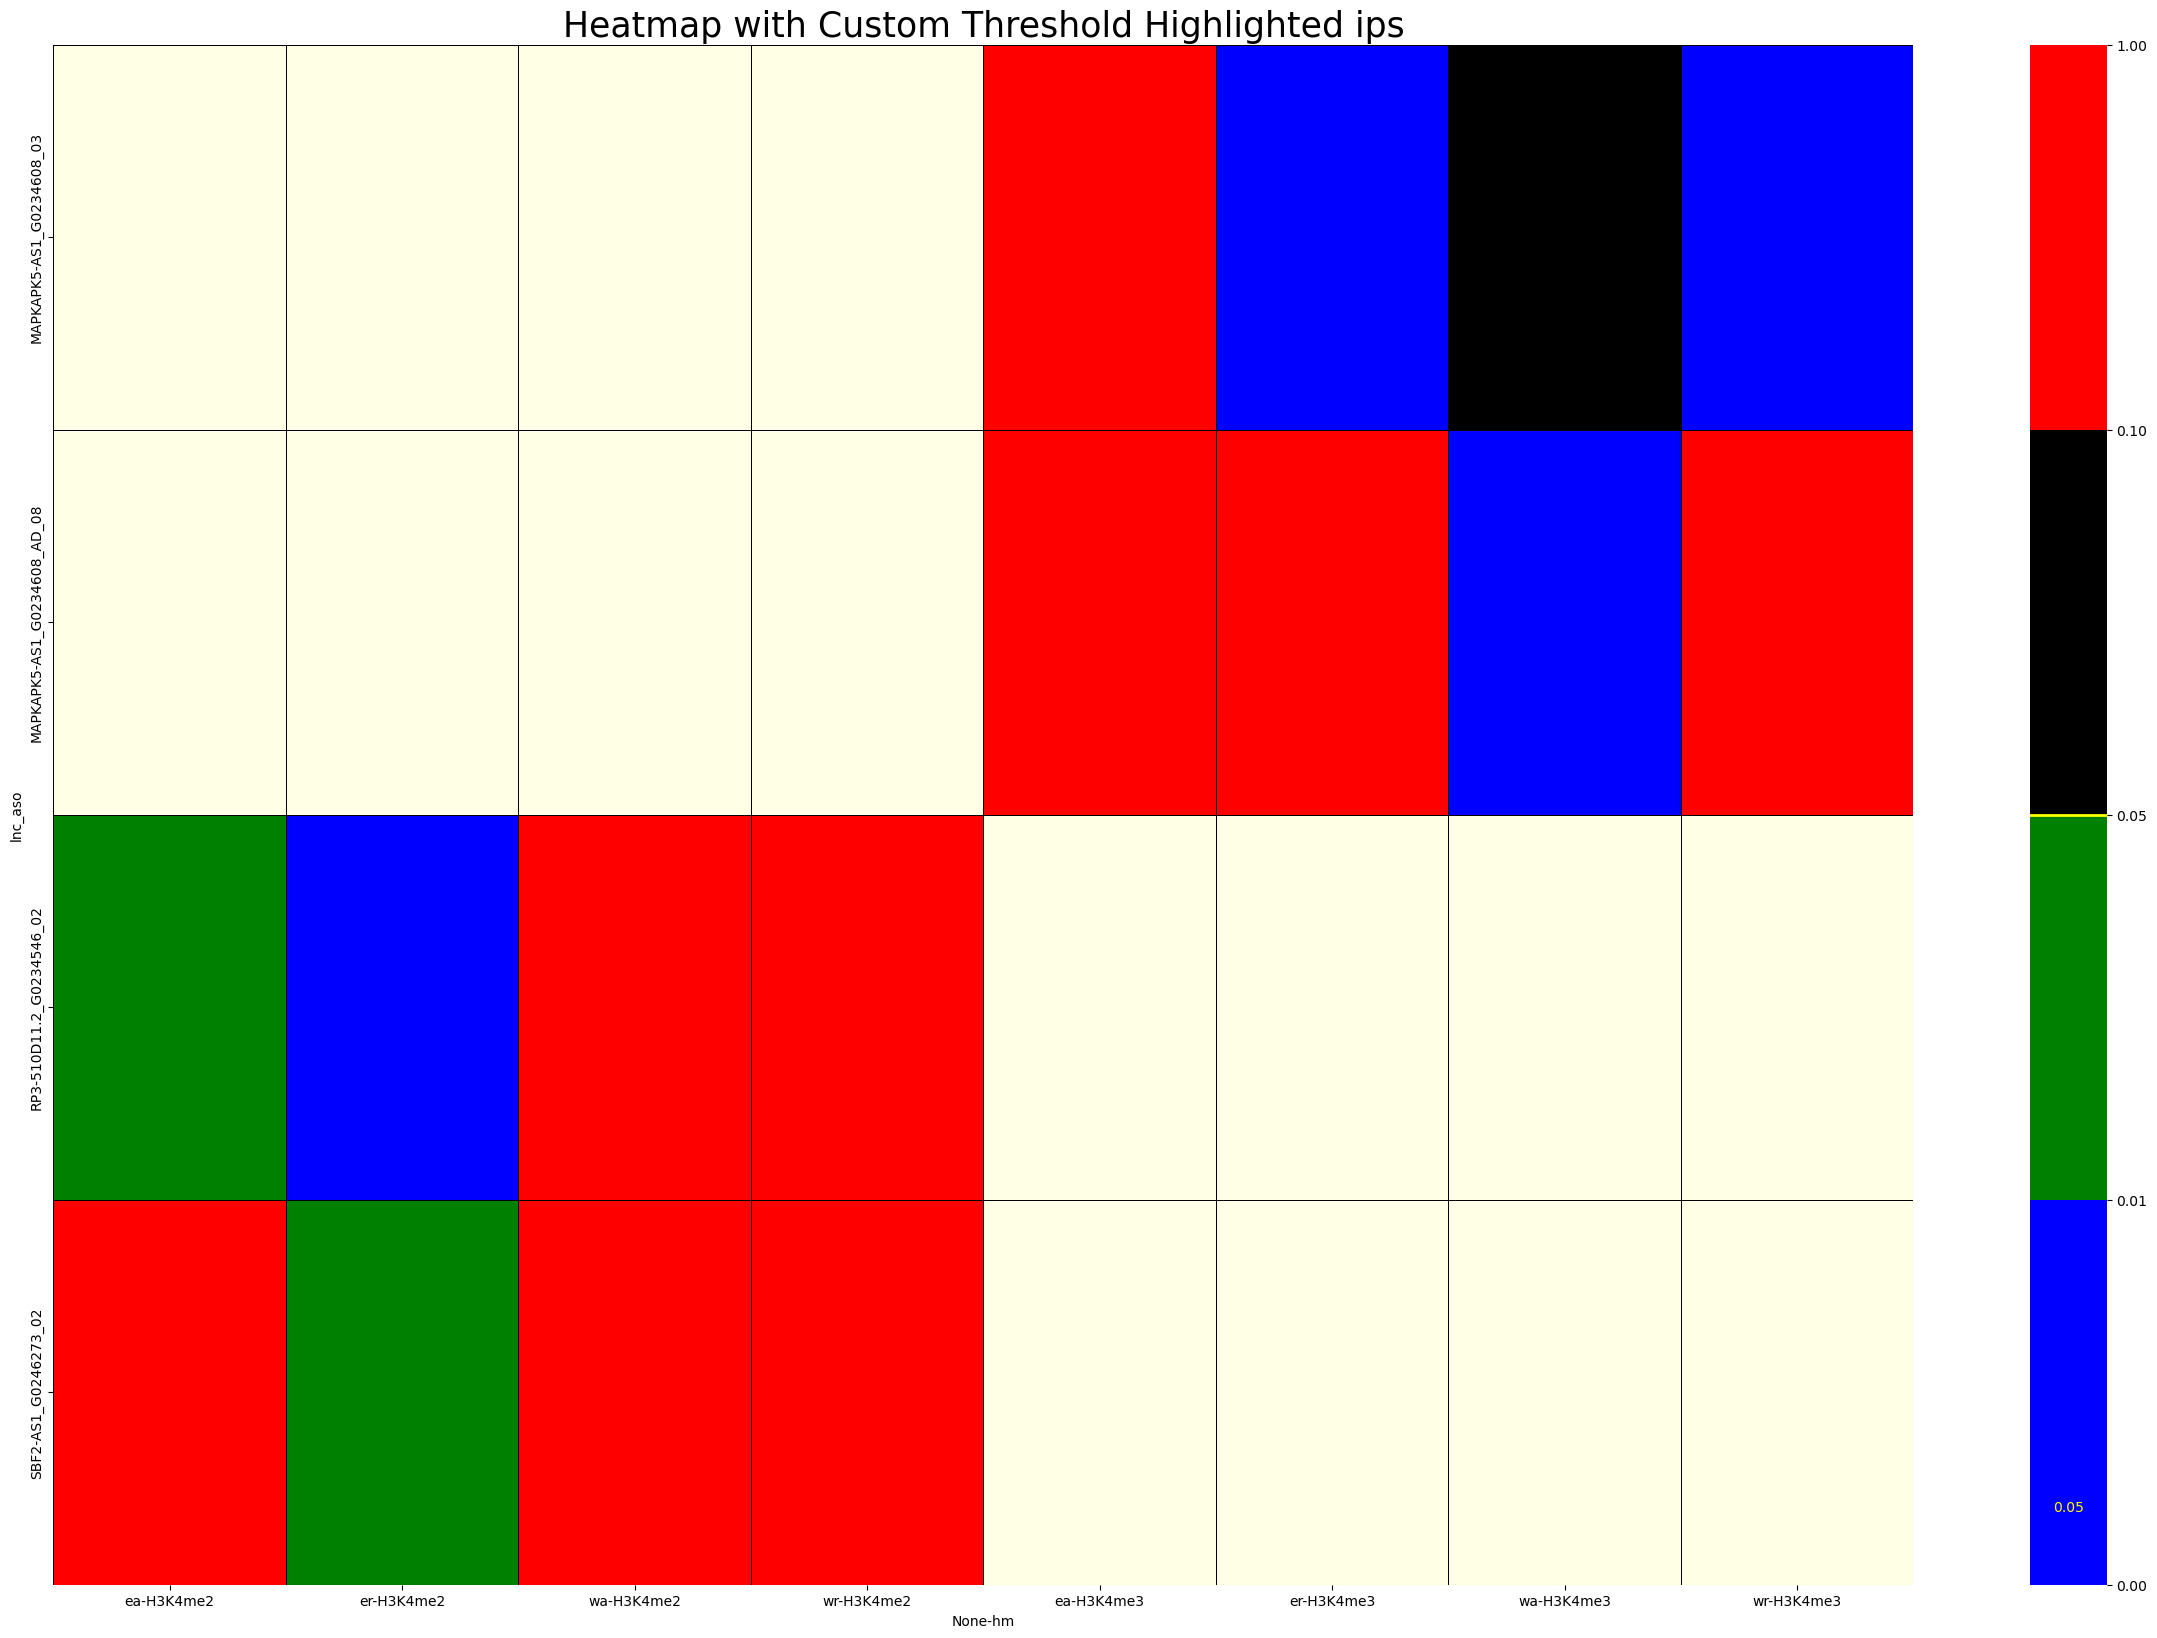

In [29]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp_bootstraped["ips"], exp="ips")

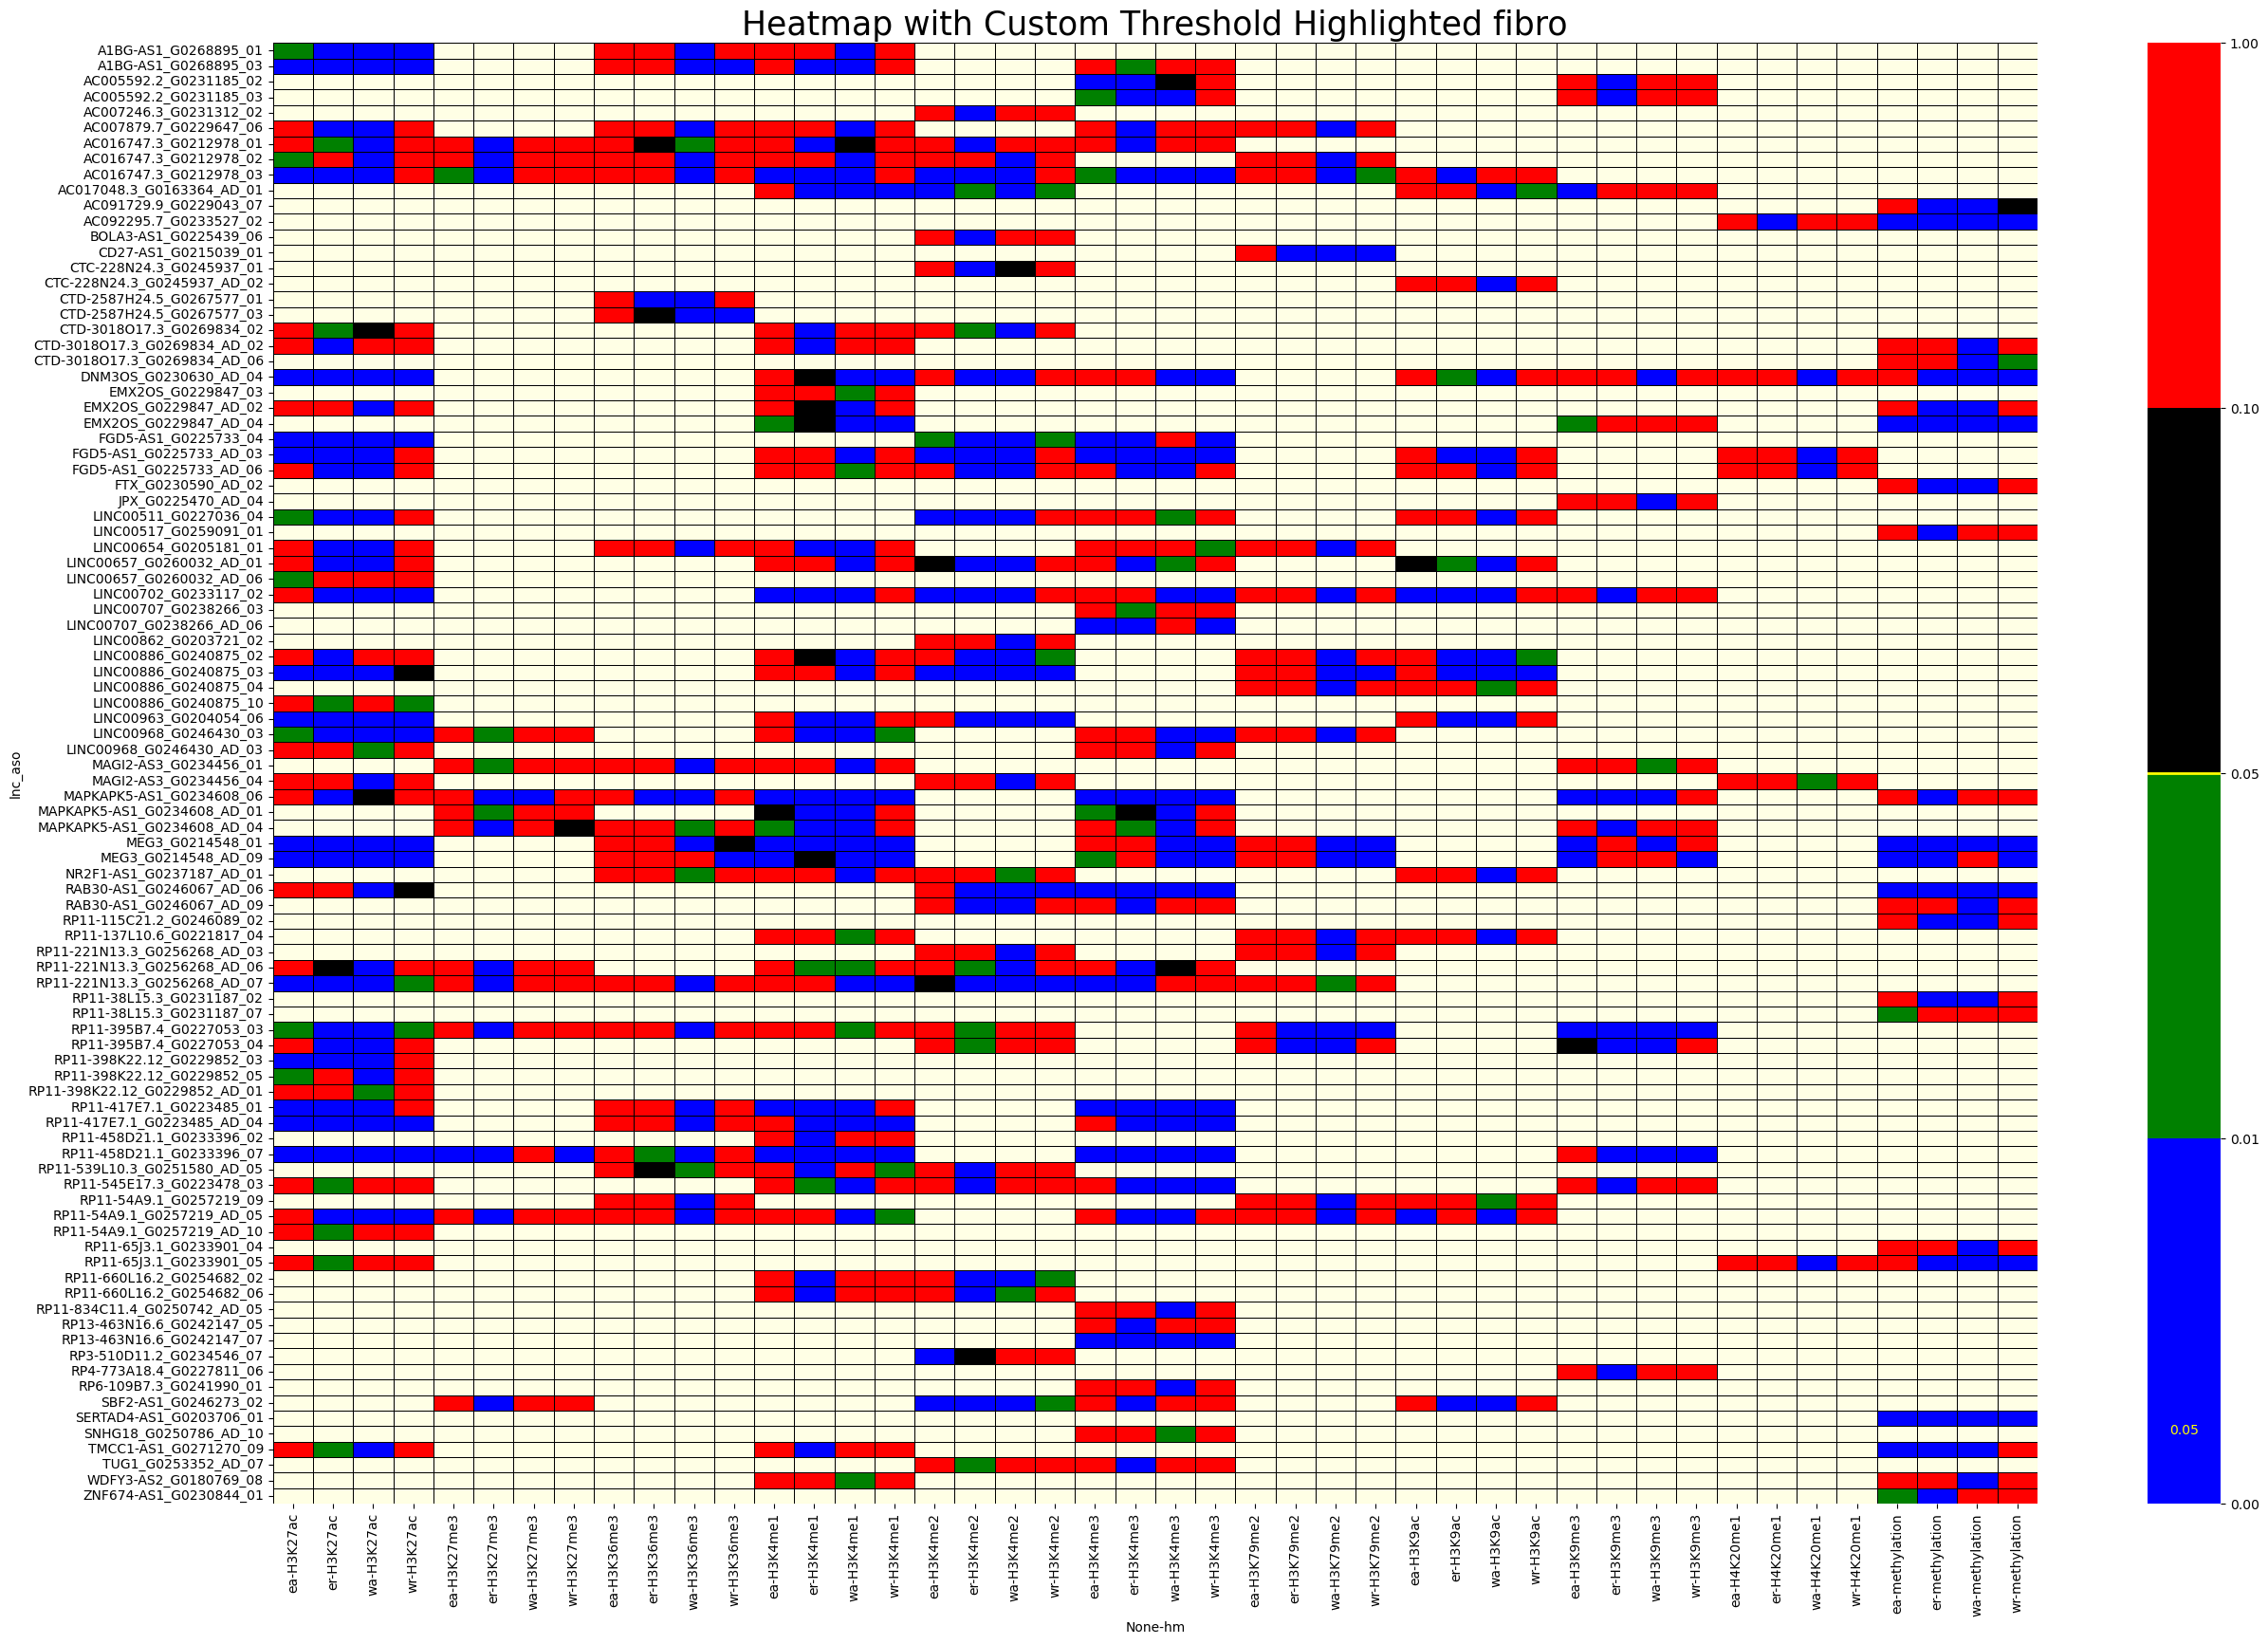

In [12]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp["fibro"], exp="fibro")

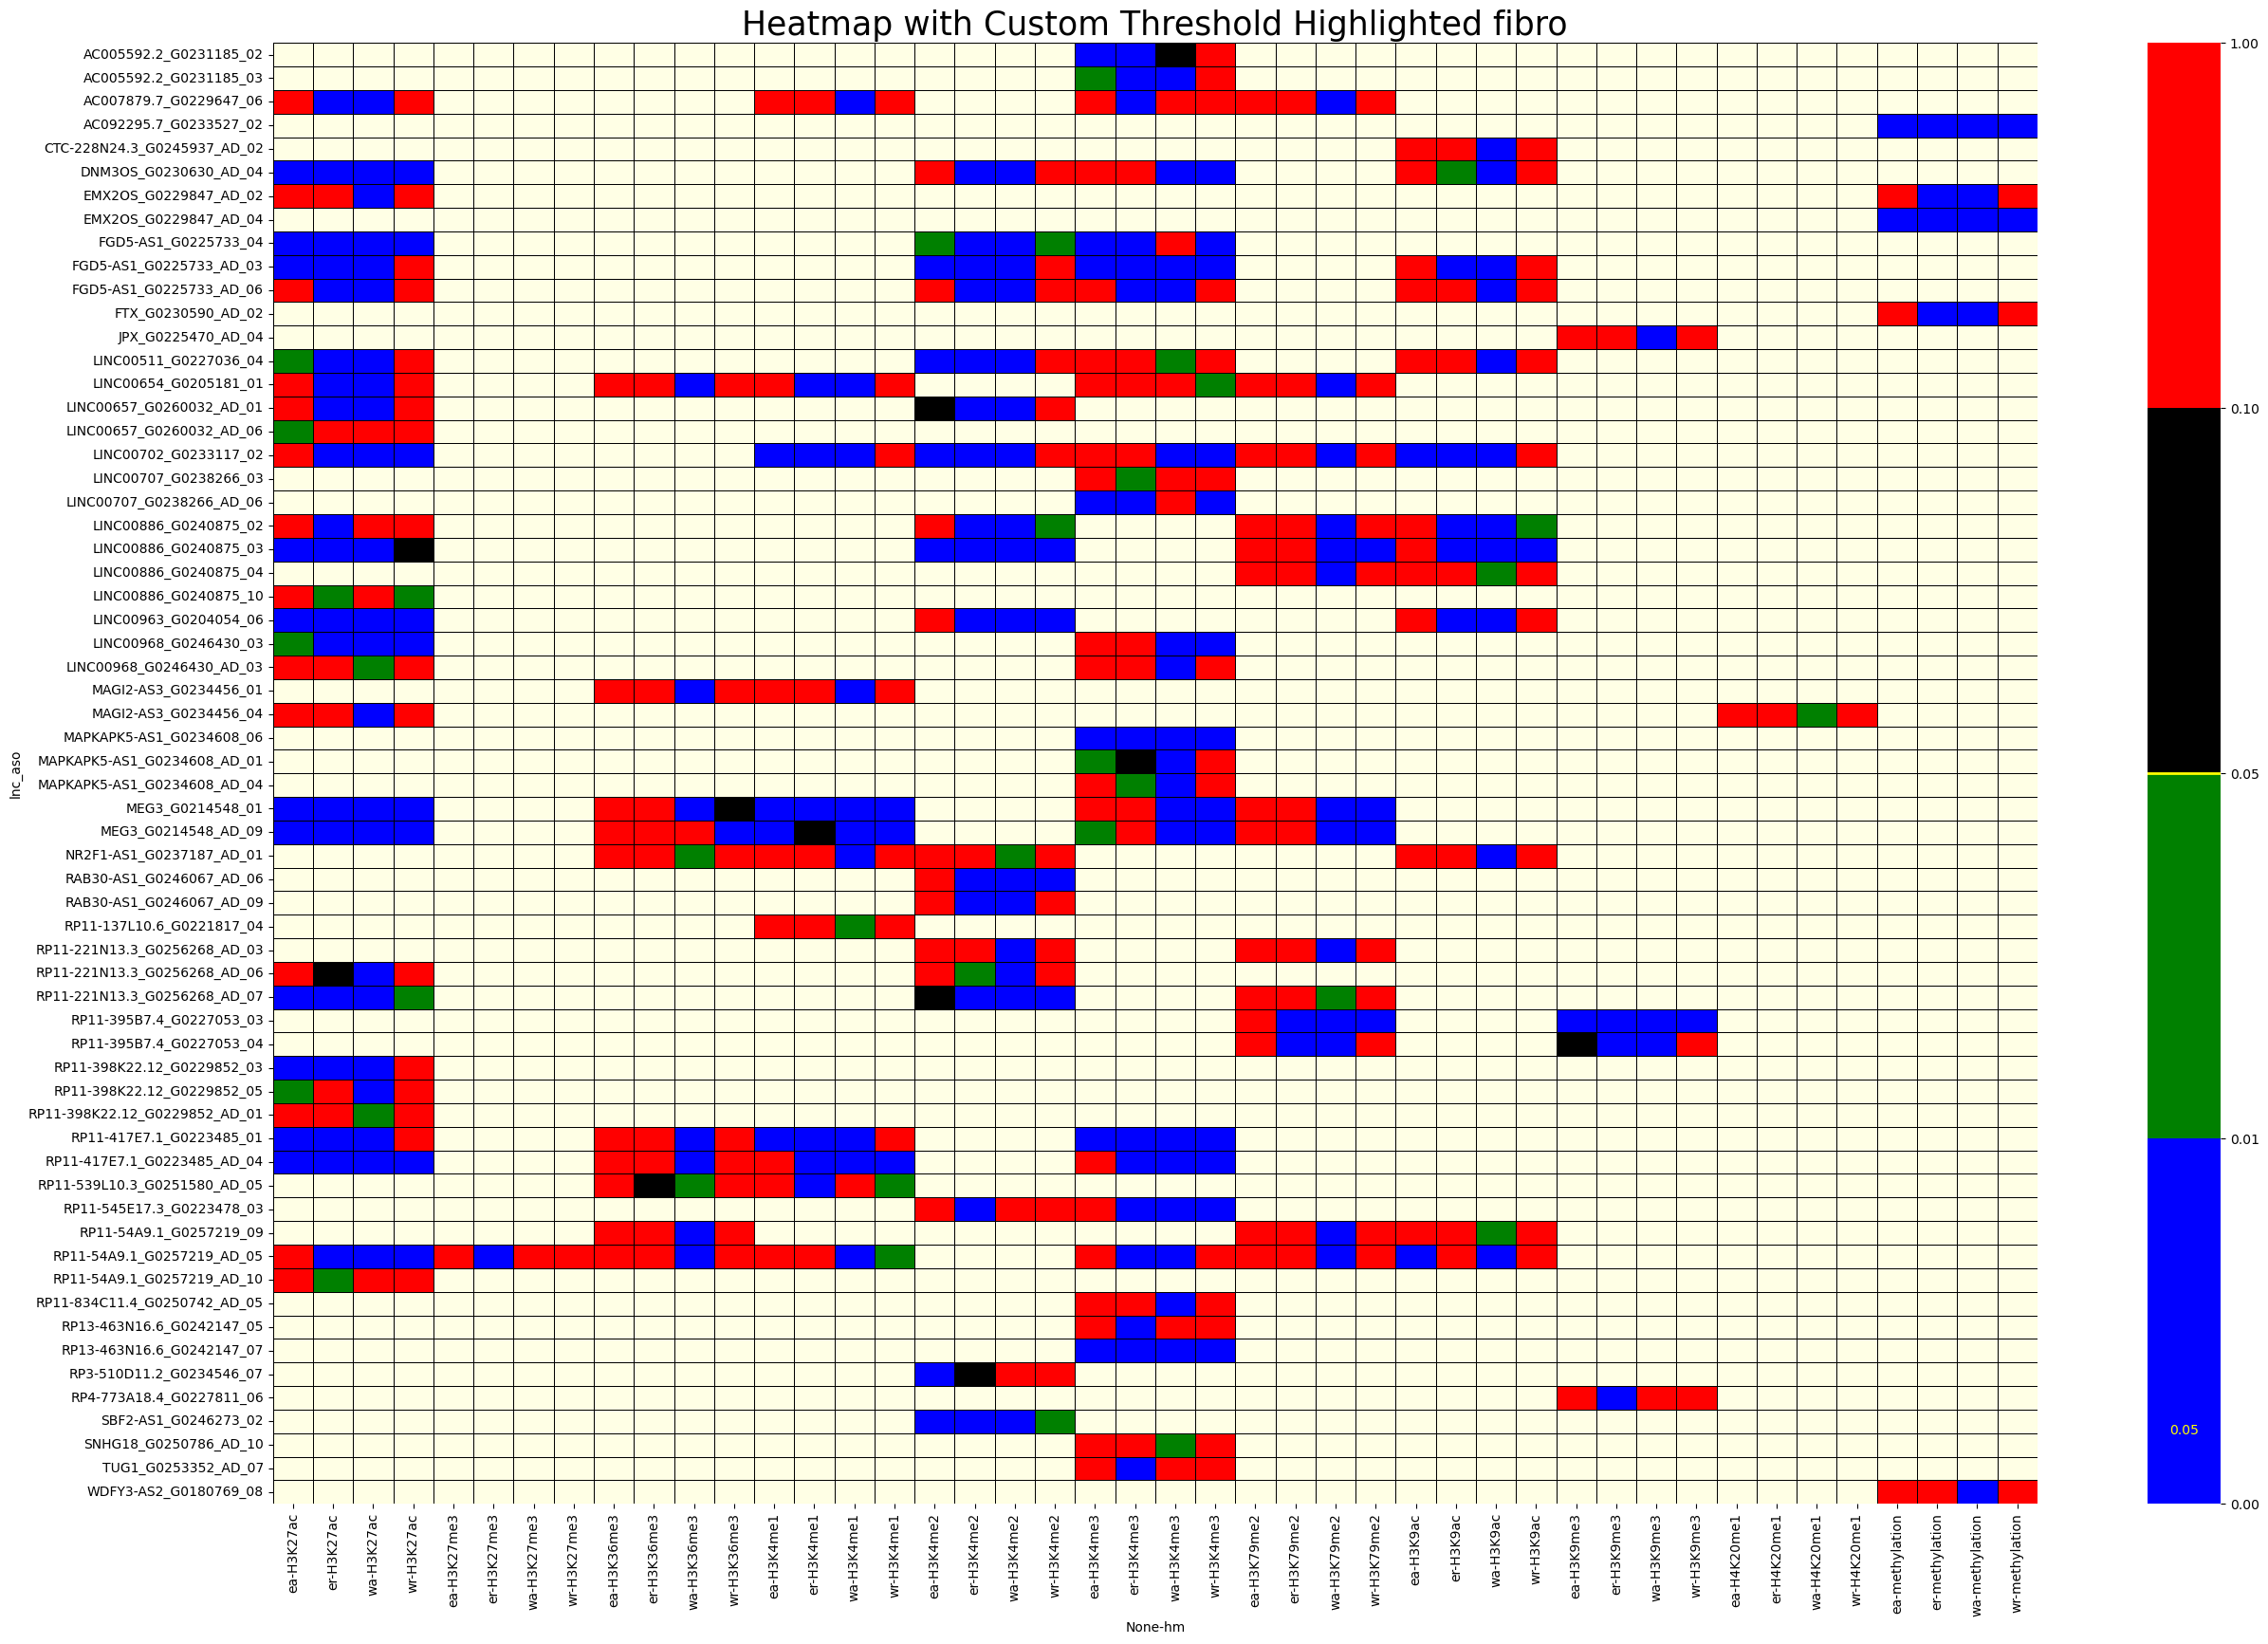

In [30]:
heatmap_pval_blue_red(df=fisher_results_filt_by_exp_bootstraped["fibro"], exp="fibro")

/tmp/ipykernel_32521/4239145872.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["lnc_aso"] = df["lnc"] + "_" + df["aso"]


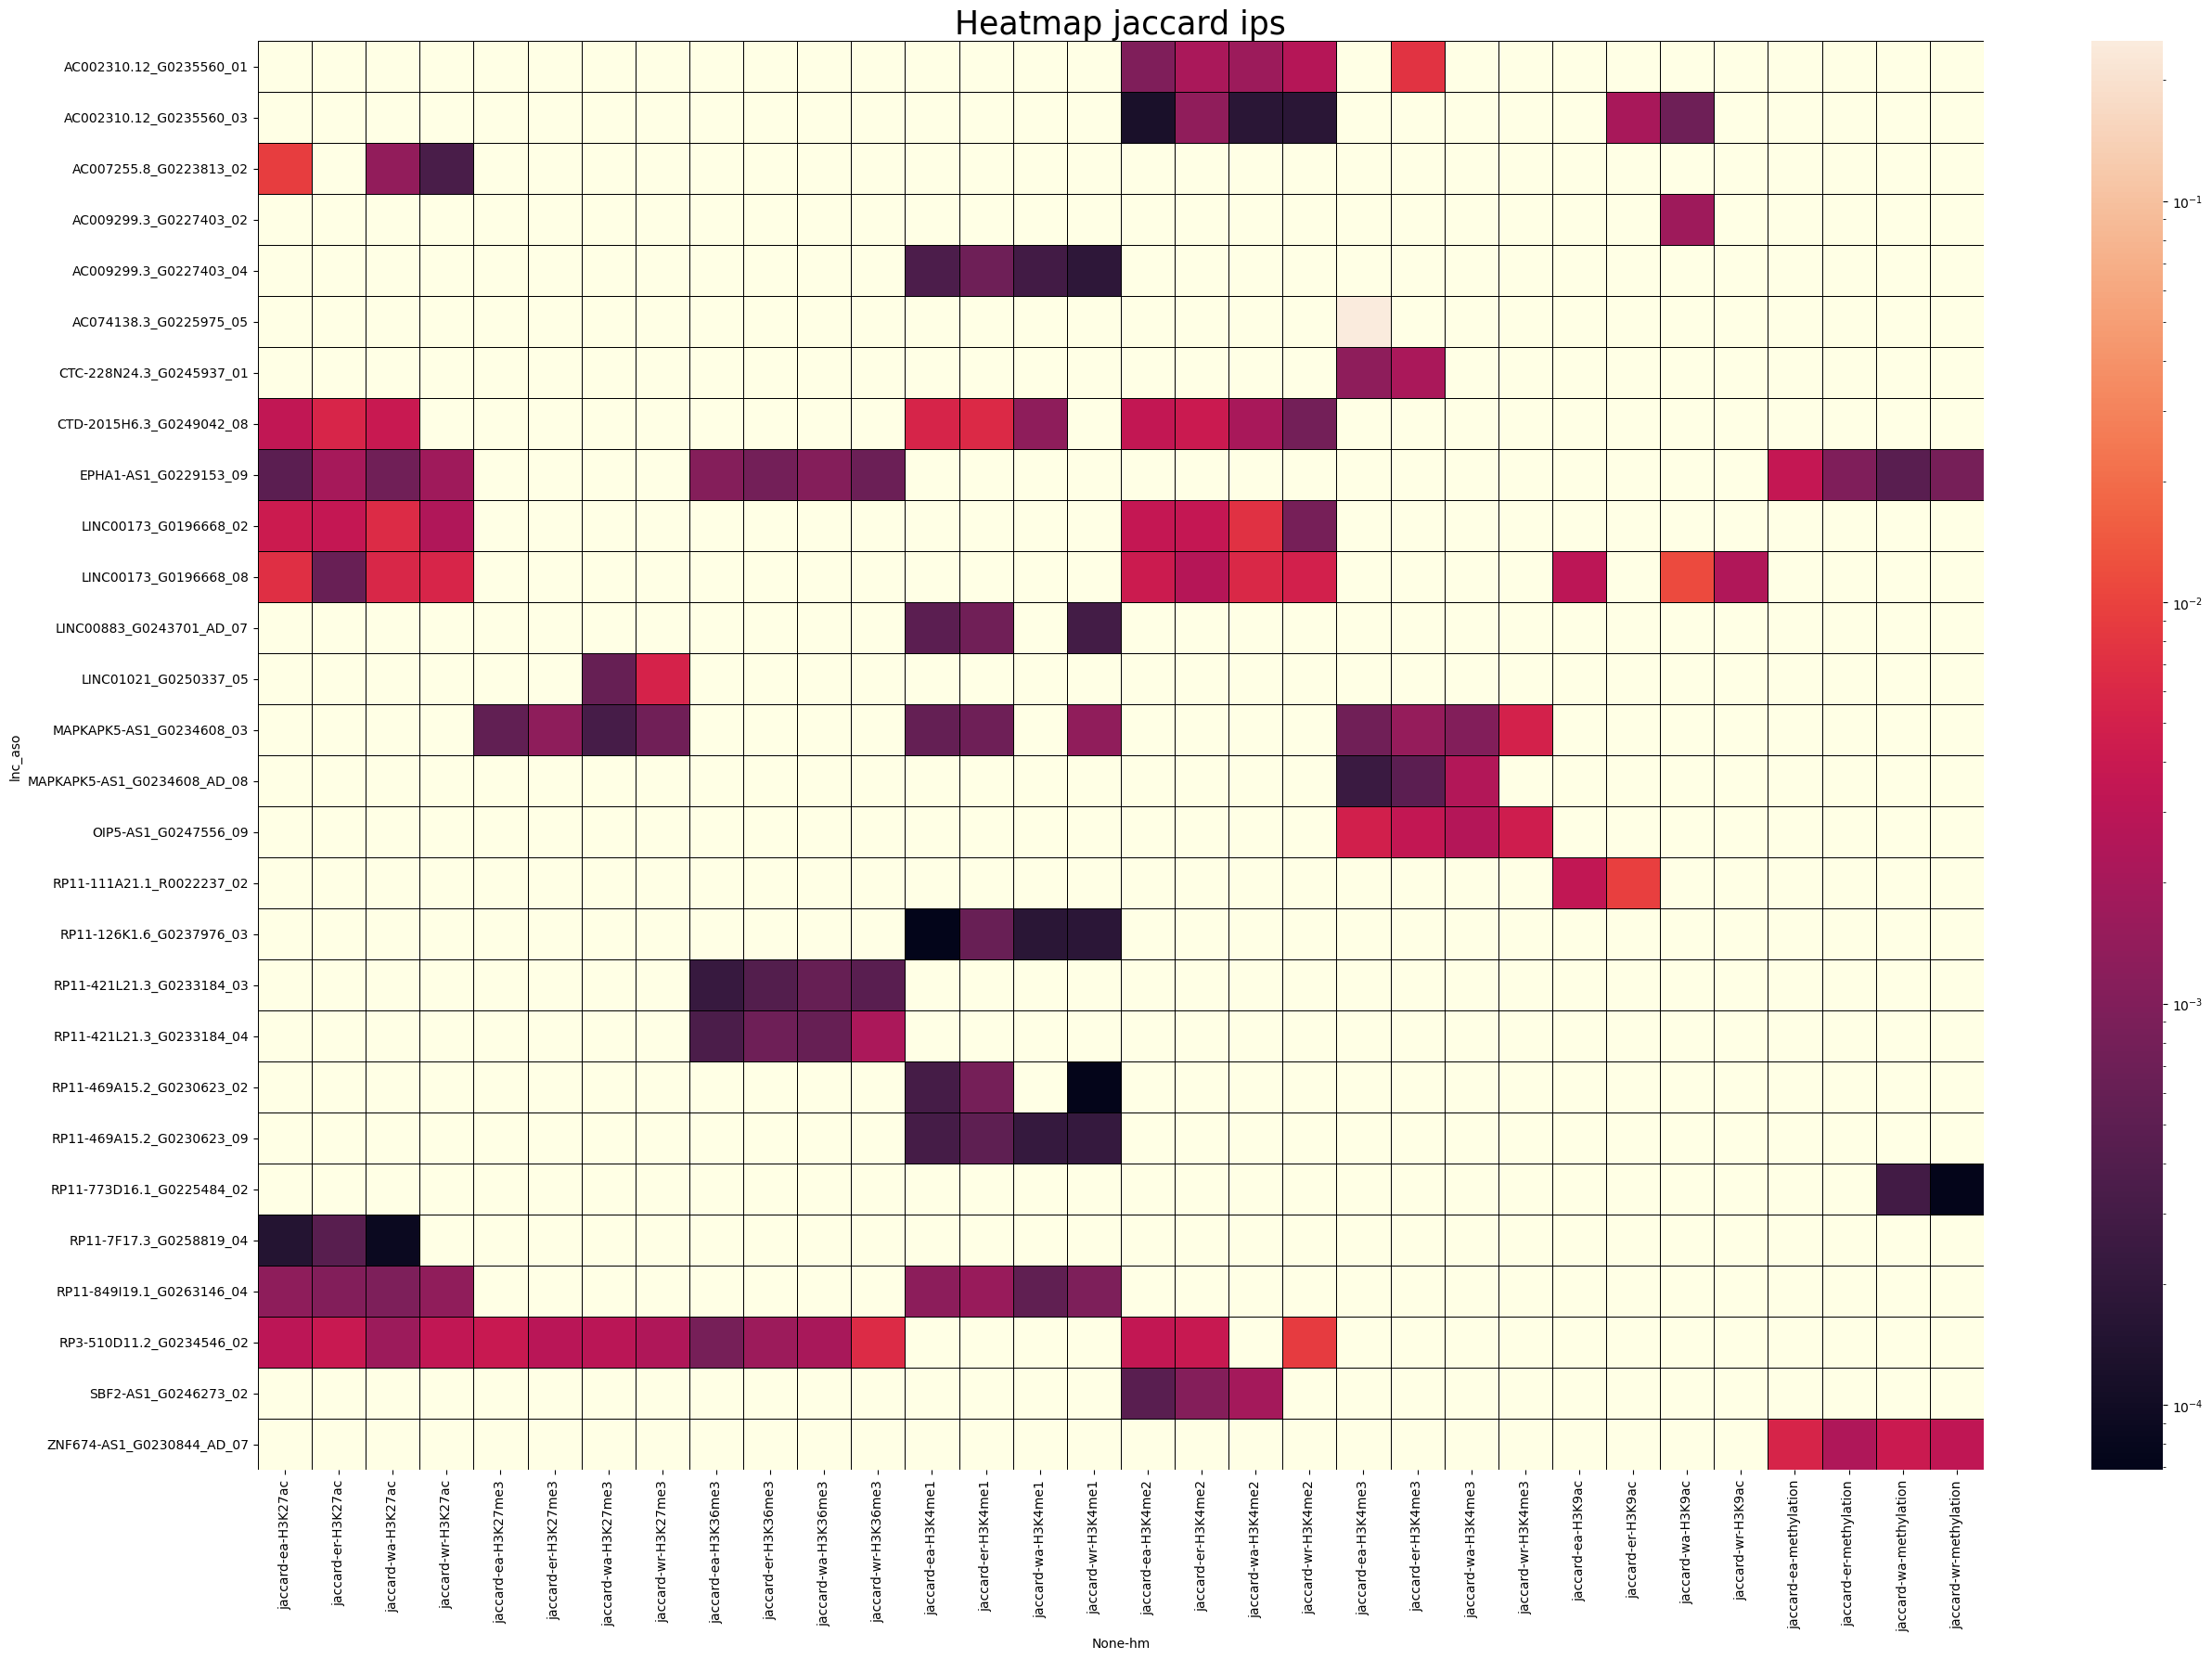

In [11]:
heatmap_pval_blue_red_jaccard(df=jaccard_results_filt_by_exp["ips"], exp="ips")

## Сравнение результатов между ASO в пределах одной ткани

In [281]:
fisher_results_filt_two_aso_by_exp = defaultdict(list)
for exp in ["fibro", "ips"]:
    for (lnc_hm, subdf) in fisher_results_filt_by_exp[exp].groupby(by="lnc-hm"):
        if len(subdf) >= 2:
            mask_er = np.where(subdf["er"] < 0.05, True, False)
            mask_ea = np.where(subdf["ea"] < 0.05, True, False)
            mask_wa = np.where(subdf["wa"] < 0.05, True, False)
            mask_wr = np.where(subdf["wr"] < 0.05, True, False)
            mask = np.where(np.array([mask_er, mask_ea, mask_wa, mask_wr]).sum(axis=1) >= 2, True, False)
            if mask.sum() >=1 :
                fisher_results_filt_two_aso_by_exp[exp].append(subdf)
            #mask = mask_er | mask_ea | mask_wa | mask_wr
            #if mask.sum() >= 2:
            #    fisher_results_filt_two_aso_by_exp[exp].append(subdf[mask])
            #if lnc_hm == "MAPKAPK5-AS1-H3K4me3":
                #break
    if len(fisher_results_filt_two_aso_by_exp[exp]) >= 1:
        fisher_results_filt_two_aso_by_exp[exp] = pd.concat(fisher_results_filt_two_aso_by_exp[exp])

In [282]:
np.where(np.array([mask_er, mask_ea, mask_wa, mask_wr]).sum(axis=1) >= 2, True, False)

array([ True, False, False, False])

In [283]:
np.array([mask_er, mask_ea, mask_wa, mask_wr])

array([[ True,  True],
       [False, False],
       [False, False],
       [False, False]])

In [284]:
np.array([mask_er, mask_ea, mask_wa, mask_wr]).sum(axis=0)

array([1, 1])

In [285]:
subdf

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,lnc_aso
8,methylation,ENSG00000230844,G0230844_AD_07,1.0,0.001146,0.758811,0.773272,ZNF674-AS1,ZNF674-AS1-methylation,ZNF674-AS1-G0230844_AD_07-methylation,ZNF674-AS1_G0230844_AD_07


In [286]:
mask_er | mask_ea | mask_wa | mask_wr

array([ True,  True])

In [287]:
fisher_results_filt_two_aso_by_exp["ips"]

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,lnc_aso
16,H3K4me2,ENSG00000235560,G0235560_01,0.000215,1.000000,1.124345e-01,0.004047,AC002310.12,AC002310.12-H3K4me2,AC002310.12-G0235560_01-H3K4me2,AC002310.12_G0235560_01
17,H3K4me2,ENSG00000235560,G0235560_03,0.000011,1.000000,1.000000e+00,1.000000,AC002310.12,AC002310.12-H3K4me2,AC002310.12-G0235560_03-H3K4me2,AC002310.12_G0235560_03
27,H3K27ac,ENSG00000196668,G0196668_02,0.393249,0.143507,6.696299e-08,0.794276,LINC00173,LINC00173-H3K27ac,LINC00173-G0196668_02-H3K27ac,LINC00173_G0196668_02
28,H3K27ac,ENSG00000196668,G0196668_08,1.000000,0.001563,8.765851e-07,0.000261,LINC00173,LINC00173-H3K27ac,LINC00173-G0196668_08-H3K27ac,LINC00173_G0196668_08
13,H3K4me2,ENSG00000196668,G0196668_02,0.329076,0.622662,6.015796e-09,1.000000,LINC00173,LINC00173-H3K4me2,LINC00173-G0196668_02-H3K4me2,LINC00173_G0196668_02
14,H3K4me2,ENSG00000196668,G0196668_08,0.735395,0.522237,5.228175e-07,0.007464,LINC00173,LINC00173-H3K4me2,LINC00173-G0196668_08-H3K4me2,LINC00173_G0196668_08
36,H3K4me1,ENSG00000230623,G0230623_02,0.004966,0.267027,1.000000e+00,1.000000,RP11-469A15.2,RP11-469A15.2-H3K4me1,RP11-469A15.2-G0230623_02-H3K4me1,RP11-469A15.2_G0230623_02
37,H3K4me1,ENSG00000230623,G0230623_09,0.031364,0.179489,1.000000e+00,0.918733,RP11-469A15.2,RP11-469A15.2-H3K4me1,RP11-469A15.2-G0230623_09-H3K4me1,RP11-469A15.2_G0230623_09


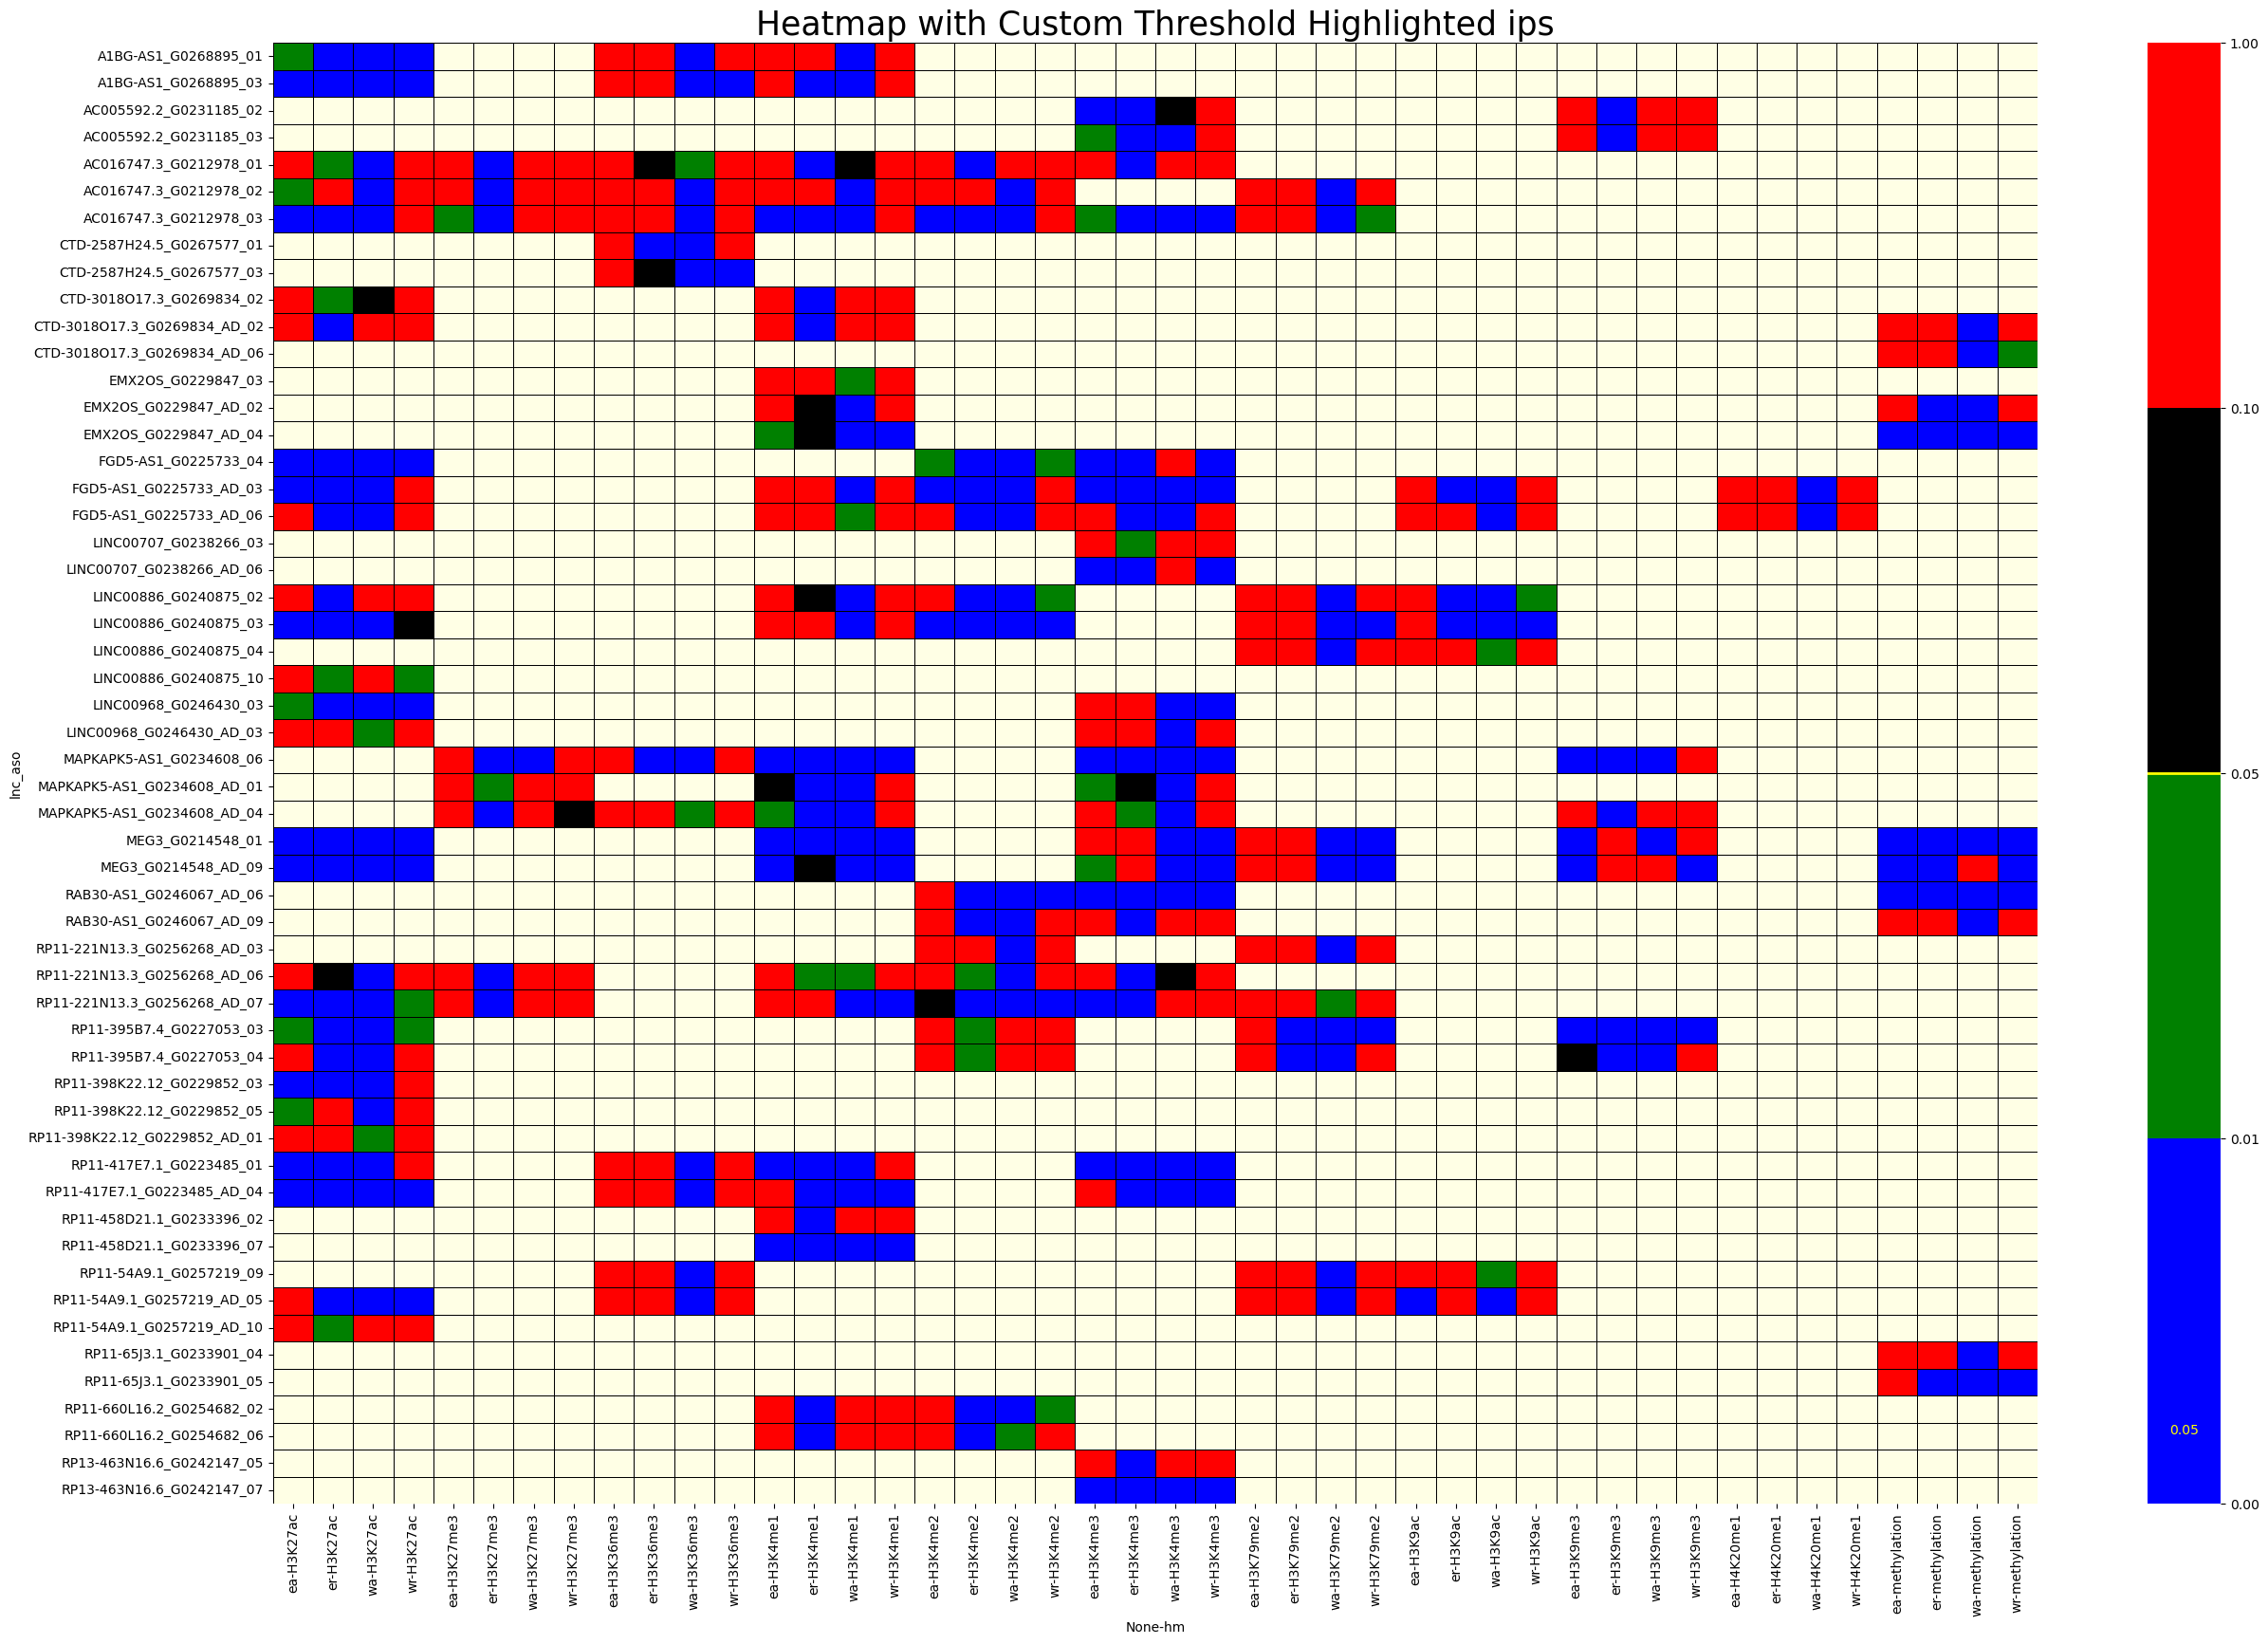

In [289]:
heatmap_pval_blue_red(df=fisher_results_filt_two_aso_by_exp["fibro"], exp="ips")

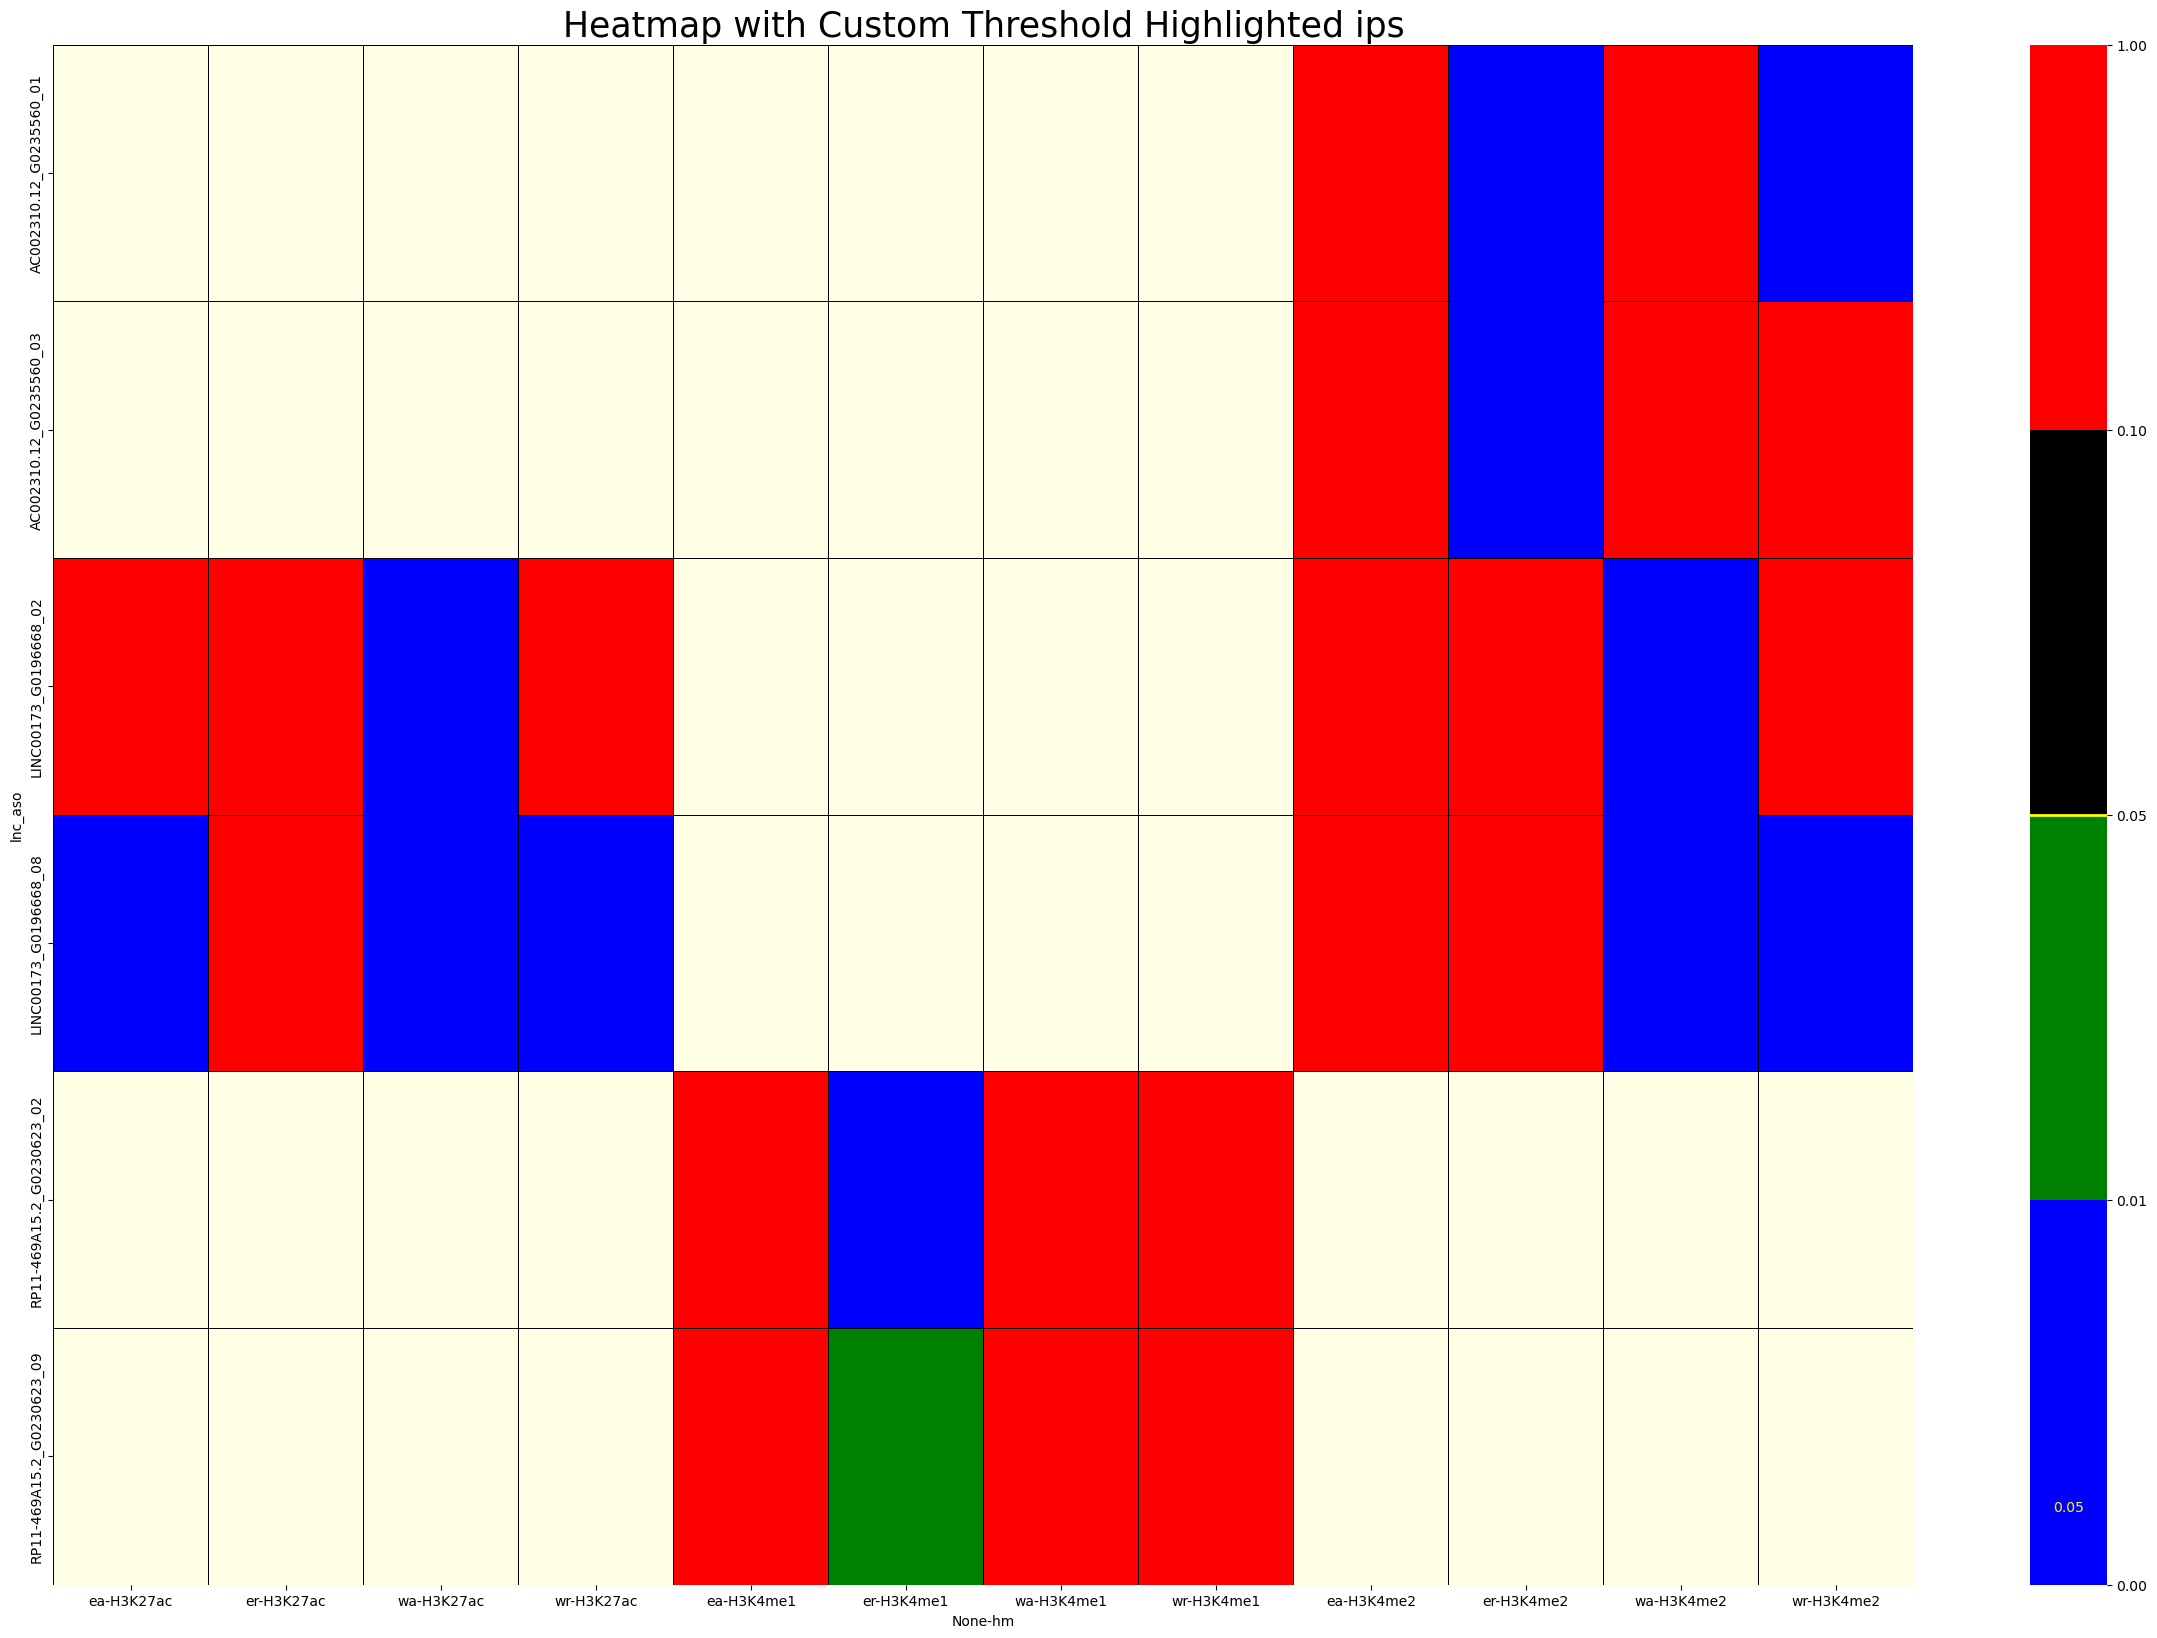

In [288]:
heatmap_pval_blue_red(df=fisher_results_filt_two_aso_by_exp["ips"], exp="ips")

## Сравнение результатов между тканями

In [12]:
set(fisher_results_filt_by_exp["ips"]["lnc-aso-hm"]) & set(fisher_results_filt_by_exp["fibro"]["lnc-aso-hm"])

set()

In [13]:
shared_pairs = set(fisher_results_filt_by_exp["ips"]["lnc-hm"]) & set(fisher_results_filt_by_exp["fibro"]["lnc-hm"])
shared_pairs

{'C2orf74-AS1-H3K4me2',
 'LNCTAM34A-H3K27ac',
 'LNCTAM34A-H3K4me2',
 'MAPKAPK5-AS1-H3K27me3',
 'MAPKAPK5-AS1-H3K4me1',
 'MAPKAPK5-AS1-H3K4me3',
 'SBF2-AS1-H3K4me2',
 'ZNF674-AS1-methylation'}

In [14]:
mask = fisher_results_filt_by_exp["ips"]["lnc-hm"].isin(shared_pairs)
ips_shared_pairs = fisher_results_filt_by_exp["ips"][mask].sort_values(by="lnc-hm")
ips_shared_pairs

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,lnc_aso
22,H3K4me2,ENSG00000271889,G0212978_03,0.044968,1.000000,1.000000,1.000000e+00,C2orf74-AS1,C2orf74-AS1-H3K4me2,C2orf74-AS1-G0212978_03-H3K4me2,C2orf74-AS1_G0212978_03
34,H3K27ac,ENSG00000234546,G0234546_02,0.096006,0.136157,1.000000,9.722402e-03,LNCTAM34A,LNCTAM34A-H3K27ac,LNCTAM34A-G0234546_02-H3K27ac,LNCTAM34A_G0234546_02
16,H3K4me2,ENSG00000234546,G0234546_02,0.015558,0.028680,1.000000,9.563246e-02,LNCTAM34A,LNCTAM34A-H3K4me2,LNCTAM34A-G0234546_02-H3K4me2,LNCTAM34A_G0234546_02
28,H3K27me3,ENSG00000234608,G0234608_03,0.001572,1.000000,1.000000,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-G0234608_03-H3K27me3,MAPKAPK5-AS1_G0234608_03
3,H3K4me1,ENSG00000234608,G0234608_03,0.000371,1.000000,1.000000,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-G0234608_03-H3K4me1,MAPKAPK5-AS1_G0234608_03
39,H3K4me3,ENSG00000234608,G0234608_03,0.002433,1.000000,0.053083,8.072416e-12,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_03-H3K4me3,MAPKAPK5-AS1_G0234608_03
40,H3K4me3,ENSG00000234608,G0234608_AD_08,1.000000,1.000000,0.000001,1.000000e+00,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me3,MAPKAPK5-AS1-G0234608_AD_08-H3K4me3,MAPKAPK5-AS1_G0234608_AD_08
19,H3K4me2,ENSG00000246273,G0246273_02,0.015558,0.711176,0.228552,1.000000e+00,SBF2-AS1,SBF2-AS1-H3K4me2,SBF2-AS1-G0246273_02-H3K4me2,SBF2-AS1_G0246273_02
9,methylation,ENSG00000230844,G0230844_AD_07,0.794325,0.000838,0.604036,7.598129e-01,ZNF674-AS1,ZNF674-AS1-methylation,ZNF674-AS1-G0230844_AD_07-methylation,ZNF674-AS1_G0230844_AD_07


In [15]:
mask = fisher_results_filt_by_exp["fibro"]["lnc-hm"].isin(shared_pairs)
fibro_shared_pairs = fisher_results_filt_by_exp["fibro"][mask].sort_values(by="lnc-hm")
fibro_shared_pairs

,hm,lnc_ens,aso,er,ea,wa,wr,lnc,lnc-hm,lnc-aso-hm,lnc_aso
204,H3K4me2,ENSG00000271889,01,5.025206e-09,1.000000,1.000000e+00,1.000000,C2orf74-AS1,C2orf74-AS1-H3K4me2,C2orf74-AS1-01-H3K4me2,C2orf74-AS1_01
205,H3K4me2,ENSG00000271889,02,5.081613e-01,1.000000,2.659400e-04,0.380448,C2orf74-AS1,C2orf74-AS1-H3K4me2,C2orf74-AS1-02-H3K4me2,C2orf74-AS1_02
206,H3K4me2,ENSG00000271889,03,7.999543e-37,0.000017,1.171426e-10,0.317477,C2orf74-AS1,C2orf74-AS1-H3K4me2,C2orf74-AS1-03-H3K4me2,C2orf74-AS1_03
114,H3K27ac,ENSG00000234546,07,3.831310e-02,0.161738,1.000000e+00,1.000000,LNCTAM34A,LNCTAM34A-H3K27ac,LNCTAM34A-07-H3K27ac,LNCTAM34A_07
187,H3K4me2,ENSG00000234546,07,5.402417e-02,0.000741,1.000000e+00,1.000000,LNCTAM34A,LNCTAM34A-H3K4me2,LNCTAM34A-07-H3K4me2,LNCTAM34A_07
139,H3K27me3,ENSG00000234608,06,9.678980e-70,0.345752,1.855836e-04,0.733376,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-06-H3K27me3,MAPKAPK5-AS1_06
140,H3K27me3,ENSG00000234608,AD_01,3.228953e-02,1.000000,1.000000e+00,0.623069,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-AD_01-H3K27me3,MAPKAPK5-AS1_AD_01
141,H3K27me3,ENSG00000234608,AD_04,1.492558e-10,1.000000,1.000000e+00,0.091073,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K27me3,MAPKAPK5-AS1-AD_04-H3K27me3,MAPKAPK5-AS1_AD_04
272,H3K4me1,ENSG00000234608,06,5.657582e-165,0.000583,2.702706e-10,0.007716,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-06-H3K4me1,MAPKAPK5-AS1_06
273,H3K4me1,ENSG00000234608,AD_01,1.431225e-08,0.052063,9.293804e-05,0.474431,MAPKAPK5-AS1,MAPKAPK5-AS1-H3K4me1,MAPKAPK5-AS1-AD_01-H3K4me1,MAPKAPK5-AS1_AD_01


<Axes: ylabel='lnc-aso-hm'>

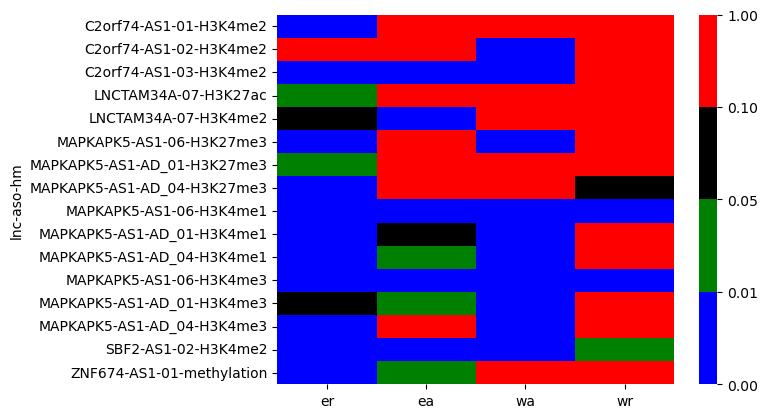

In [16]:
cmap = ListedColormap(['blue', 'green', 'black', 'red'])
bounds = [0, 0.01, 0.05, 0.1, 1]
norm = BoundaryNorm(bounds, cmap.N)
sns.heatmap(fibro_shared_pairs[["lnc-aso-hm", "er", "ea", "wa", "wr"]].set_index("lnc-aso-hm"), cmap=cmap, cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]}, norm=norm)

<Axes: ylabel='lnc-aso-hm'>

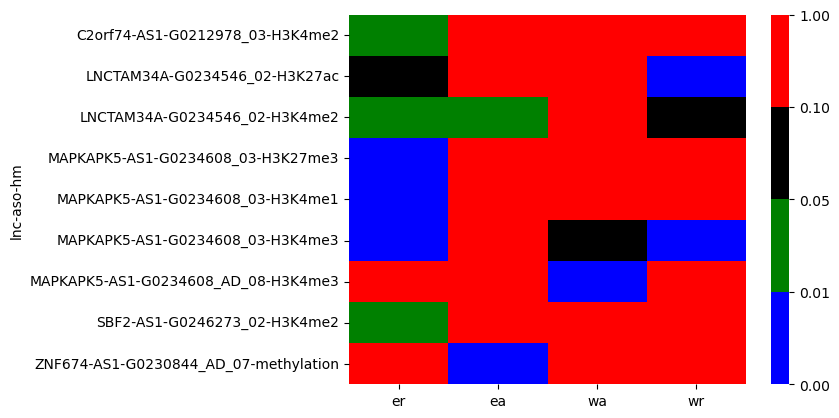

In [17]:
sns.heatmap(ips_shared_pairs[["lnc-aso-hm", "er", "ea", "wa", "wr"]].set_index("lnc-aso-hm"), cmap=cmap, cbar_kws={'boundaries': bounds, 'ticks': [0, 0.01, 0.05, 0.1, 1]}, norm=norm)